In [ ]:
# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Presentación de tablas
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

# Rutas del proyecto
CARPETA_PROYECTO = Path.cwd()
ARCHIVO_DATOS = CARPETA_PROYECTO / "data" / "interim" / "silver_alquileres_scraping_nlp.csv"

print(f"Carpeta del proyecto: {CARPETA_PROYECTO}")
print(f"Archivo encontrado: {ARCHIVO_DATOS.is_file()}")

Carpeta del proyecto: c:\Users\HP\Downloads\PI_EDA_Final
Archivo encontrado: True


In [115]:
# ============================================================
# 2. CARGA DE LA BASE
# ============================================================

if not ARCHIVO_DATOS.is_file():
    raise FileNotFoundError(
        f"No se encontró el archivo en: {ARCHIVO_DATOS}"
    )

df_original = pd.read_csv(
    ARCHIVO_DATOS,
    encoding="utf-8-sig",
    low_memory=False,
)

# Copia de trabajo: conservamos intacta la base original
df = df_original.copy()

print(f"Registros: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]:,}")

columnas_vista = [
    "id_anuncio",
    "tipo_inmueble",
    "distrito",
    "precio_pen_pub",
    "area_total_m2",
]

display(df[columnas_vista].head())

Registros: 7,061
Variables: 92


,id_anuncio,tipo_inmueble,distrito,precio_pen_pub,area_total_m2
0,adondevivir-151071818,cuarto,miraflores,"1,650.00",1.00
1,adondevivir-146574391,cuarto,los olivos,400.00,200.00
2,adondevivir-142562169,cuarto,lince,650.00,12.00
3,adondevivir-151527695,cuarto,jesus maria,950.00,12.00
4,adondevivir-143771963,cuarto,lince,800.00,12.00


In [116]:
# ============================================================
# 3. ELIMINACIÓN DE COLUMNAS AUXILIARES
# ============================================================

COLUMNAS_ELIMINAR = [
    "grupo_inmueble",
    "n_anuncios_grupo",
    "canal",
    "origen_dato",
    "precio_usd_pub",
    "precio_convertido_usd",
    "precision_coord",
    "apto_modelo",
    "motivo_no_apto",
    "id_contenido",
    "fecha_publicacion",
    "modalidad",
    "titulo_anon",
    "ubicacion_texto",
    "motivo_temporalidad",
    "ofrece_temporal",
    "moneda_pub",
    "dormitorios_fuente",
    "dormitorios_conflicto",
    "banos_fuente",
    "banos_conflicto",
    "estacionamientos_fuente",
    "estacionamientos_conflicto",
    "area_titulo_m2",
    "banos_evidencia",
    "es_habitacion",
    "piso_fuente",
    "cant_pisos_fuente",
    "anio_construccion_texto",
    "antiguedad_anios",
    "mantenimiento_usd",
    "mantenimiento_fuente",
    "mantenimiento_incluido",
    "anio_construccion",
    "anio_construccion_fuente",
    "tipo_inmueble_homologado",
    "flag_area_total_menor_construida",
    "ids_anuncios_grupo",
    "descripcion_anon",
    "banos_tipo",
    "mantenimiento_pen",
    "attr_semi_amoblado",
    "attr_servicios_basicos_disponibles",
    "area_terreno_m2",
    "area_construida_m2",
    "area_techada_m2",
    "banos_visita",

]


def eliminar_columnas(
    datos: pd.DataFrame,
    columnas: list[str],
) -> pd.DataFrame:
    """Retira las columnas indicadas sin modificar la base original."""
    no_encontradas = sorted(set(columnas) - set(datos.columns))

    if no_encontradas:
        raise ValueError(
            f"Estas columnas no existen en la base: {no_encontradas}"
        )

    return datos.drop(columns=columnas).copy()


# Crear la base de trabajo desde la base original
df = eliminar_columnas(df_original, COLUMNAS_ELIMINAR)

# Verificar el resultado
print(f"Columnas originales : {df_original.shape[1]}")
print(f"Columnas eliminadas : {len(COLUMNAS_ELIMINAR)}")
print(f"Columnas restantes  : {df.shape[1]}")
print(f"Registros conservados: {df.shape[0]:,}")

display(df.head())

Columnas originales : 92
Columnas eliminadas : 47
Columnas restantes  : 45
Registros conservados: 7,061


,id_anuncio,portal,fecha_captura,distrito,ambito,tipo_inmueble,tipo_alquiler,...,attr_agua_caliente,attr_walk_in_closet,attr_coworking,attr_zona_parrilla,attr_servicios_basicos,attr_vista_ciudad,attr_internet
0,adondevivir-151071818,adondevivir,2026-11-11,miraflores,lima_metropolitana,cuarto,mensual,...,0,1,0,1,0,0,1
1,adondevivir-146574391,adondevivir,2026-11-11,los olivos,lima_metropolitana,cuarto,mensual,...,0,1,0,0,1,1,1
2,adondevivir-142562169,adondevivir,2026-11-11,lince,lima_metropolitana,cuarto,mensual,...,0,0,0,0,1,0,1
3,adondevivir-151527695,adondevivir,2026-11-11,jesus maria,lima_metropolitana,cuarto,mensual,...,1,1,0,0,1,0,1
4,adondevivir-143771963,adondevivir,2026-11-11,lince,lima_metropolitana,cuarto,mensual,...,0,0,0,0,1,0,1


## 4. Panorama inicial de los datos

Describimos la composición de la base por tipo de inmueble,
fuente y distrito, e identificamos las variables con información faltante.

Los gráficos representan los anuncios recolectados, no la distribución
de todas las viviendas de Lima Metropolitana.

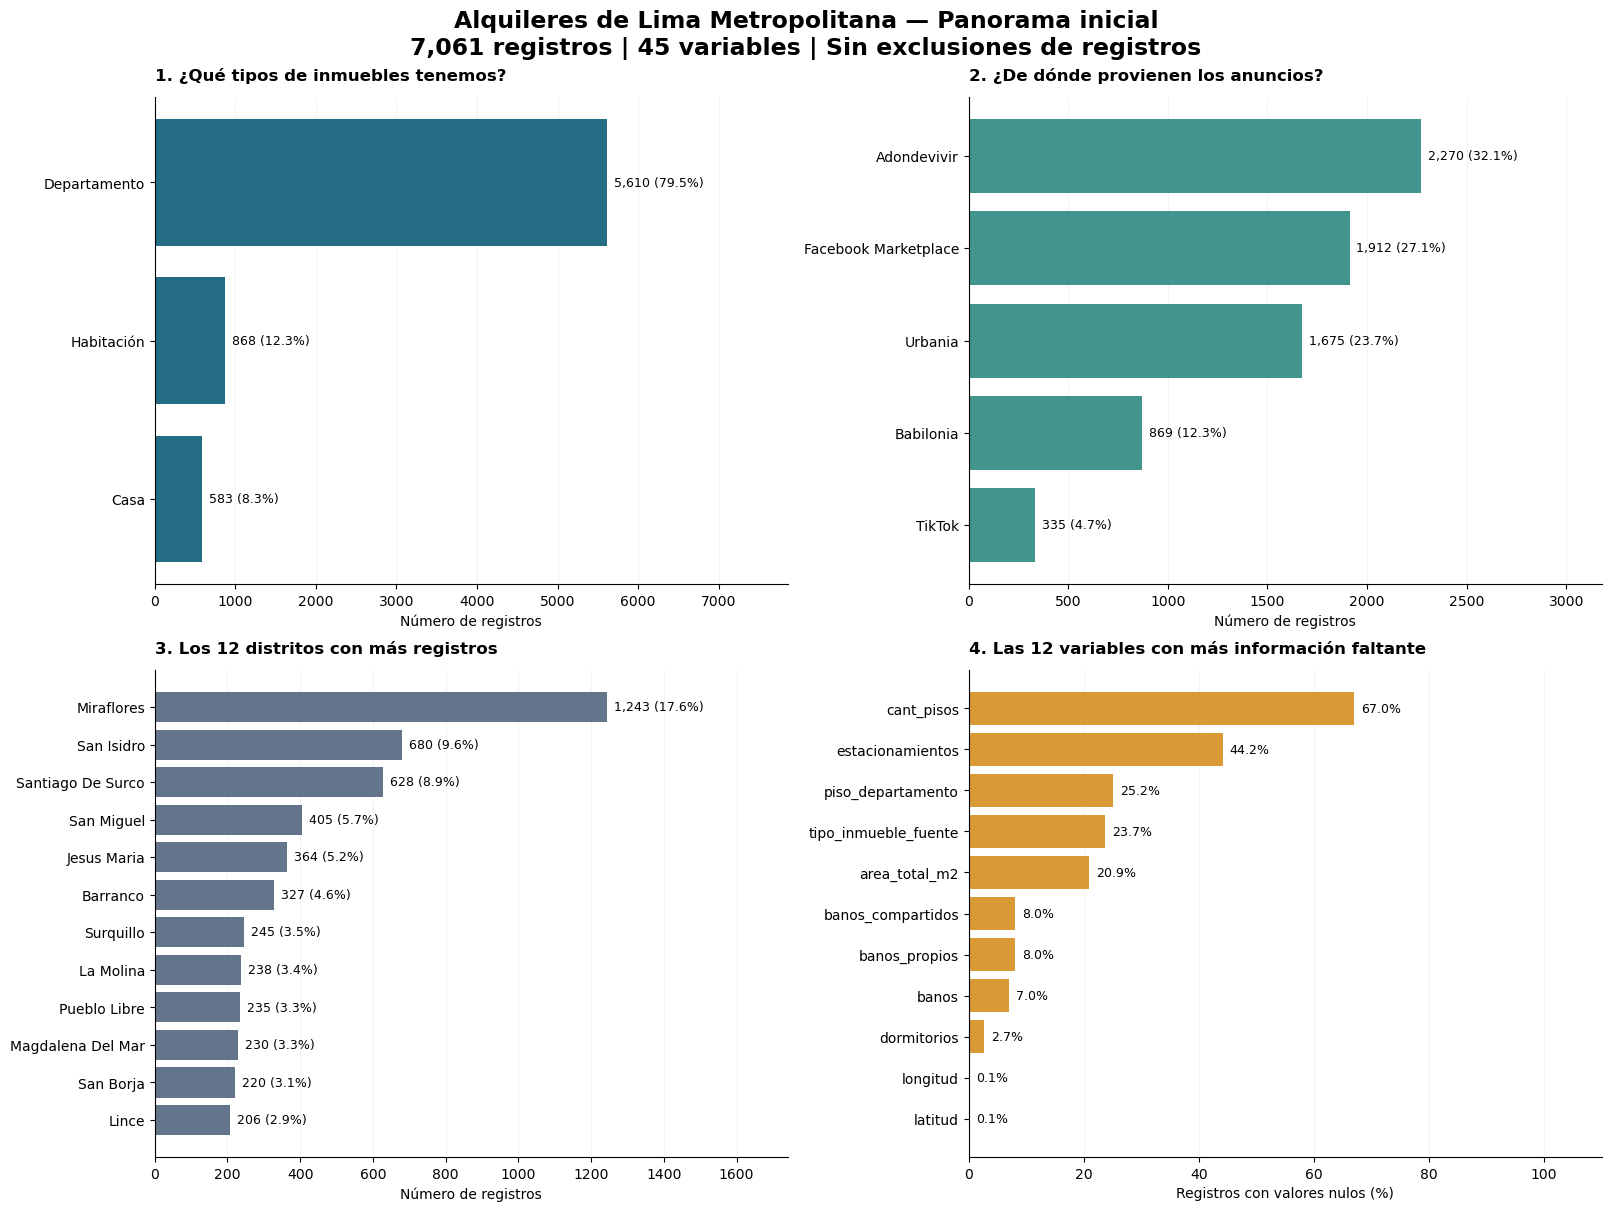

In [117]:
# ============================================================
# 4. PANORAMA INICIAL DE LA BASE
# ============================================================

def graficar_panorama(datos: pd.DataFrame):
    """Visualiza composición y faltantes sin modificar los datos."""

    colores = {
        "azul": "#256D85",
        "verde": "#42958C",
        "gris": "#64748B",
        "naranja": "#D99A36",
    }

    def barras_conteo(ax, serie, titulo, color, limite=None):
        """Representa frecuencias con cantidades y porcentajes."""

        conteos = serie.fillna("Sin información").value_counts()

        if limite is not None:
            conteos = conteos.head(limite)

        conteos = conteos.sort_values()

        barras = ax.barh(
            conteos.index.astype(str),
            conteos.values,
            color=color,
        )

        etiquetas = [
            f"{cantidad:,} ({cantidad / len(datos):.1%})"
            for cantidad in conteos.values
        ]

        ax.bar_label(barras, labels=etiquetas, padding=5, fontsize=9)
        ax.set_xlim(0, conteos.max() * 1.40)
        ax.set_title(titulo, loc="left", fontweight="bold", pad=12)
        ax.set_xlabel("Número de registros")
        ax.set_axisbelow(True)
        ax.grid(axis="x", alpha=0.15)

    with plt.rc_context({
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }):
        fig, axes = plt.subplots(
            2,
            2,
            figsize=(16, 12),
            layout="constrained",
        )

        # 1. Tipo de inmueble
        # Solo cambia las etiquetas del gráfico.
        tipos = datos["tipo_inmueble"].replace({
            "departamento": "Departamento",
            "casa": "Casa",
            "cuarto": "Habitación",
        })

        barras_conteo(
            axes[0, 0],
            tipos,
            "1. ¿Qué tipos de inmuebles tenemos?",
            colores["azul"],
        )

        # 2. Fuente de los anuncios
        fuentes = datos["portal"].replace({
            "adondevivir": "Adondevivir",
            "urbania": "Urbania",
            "babilonia": "Babilonia",
            "facebook_marketplace": "Facebook Marketplace",
            "tiktok": "TikTok",
        })

        barras_conteo(
            axes[0, 1],
            fuentes,
            "2. ¿De dónde provienen los anuncios?",
            colores["verde"],
        )

        # 3. Distritos con más registros
        distritos = datos["distrito"].astype("string").str.title()

        barras_conteo(
            axes[1, 0],
            distritos,
            "3. Los 12 distritos con más registros",
            colores["gris"],
            limite=12,
        )

        # 4. Variables con mayor porcentaje de nulos
        faltantes = (
            datos.isna()
            .mean()
            .mul(100)
            .loc[lambda serie: serie > 0]
            .sort_values(ascending=False)
            .head(12)
            .sort_values()
        )

        ax = axes[1, 1]

        if faltantes.empty:
            ax.text(
                0.5, 0.5,
                "No se detectaron valores nulos",
                ha="center",
                va="center",
                transform=ax.transAxes,
            )
            ax.set_axis_off()
        else:
            barras = ax.barh(
                faltantes.index,
                faltantes.values,
                color=colores["naranja"],
            )

            ax.bar_label(
                barras,
                labels=[f"{valor:.1f}%" for valor in faltantes.values],
                padding=5,
                fontsize=9,
            )

            ax.set_xlim(0, 110)
            ax.set_xticks([0, 20, 40, 60, 80, 100])
            ax.set_xlabel("Registros con valores nulos (%)")
            ax.set_axisbelow(True)
            ax.grid(axis="x", alpha=0.15)

        ax.set_title(
            "4. Las 12 variables con más información faltante",
            loc="left",
            fontweight="bold",
            pad=12,
        )

        fig.suptitle(
            "Alquileres de Lima Metropolitana — Panorama inicial\n"
            f"{len(datos):,} registros | {datos.shape[1]} variables "
            "| Sin exclusiones de registros",
            fontsize=17,
            fontweight="bold",
        )

    return fig


fig_panorama = graficar_panorama(df)
plt.show()

## 5. Diagnóstico inicial de la base de trabajo

Revisamos los tipos de datos, valores faltantes y valores únicos
de cada variable. También identificamos filas e identificadores
repetidos, sin eliminar registros.

In [118]:
# ============================================================
# 5. DIAGNÓSTICO DE ESTRUCTURA Y CALIDAD
# ============================================================

def diagnosticar_variables(datos: pd.DataFrame) -> pd.DataFrame:
    """Resume la estructura y cobertura de cada variable."""

    diagnostico = pd.DataFrame({
        "variable": datos.columns,
        "tipo_dato": datos.dtypes.astype(str).to_numpy(),
        "no_nulos": datos.notna().sum().to_numpy(),
        "nulos": datos.isna().sum().to_numpy(),
        "nulos_pct": (
            datos.isna().mean().mul(100).round(2).to_numpy()
        ),
        "valores_unicos": datos.nunique(dropna=True).to_numpy(),
    })

    return diagnostico.sort_values(
        by="nulos_pct",
        ascending=False,
        kind="stable",
    ).reset_index(drop=True)


diagnostico_variables = diagnosticar_variables(df)

print(f"Base de trabajo: {df.shape[0]:,} registros y {df.shape[1]} variables")

# Mostrar las 54 variables sin cambiar la configuración global
with pd.option_context("display.max_rows", None):
    display(diagnostico_variables)

Base de trabajo: 7,061 registros y 45 variables


,variable,tipo_dato,no_nulos,nulos,nulos_pct,valores_unicos
0,cant_pisos,float64,2333,4728,66.96,38
1,estacionamientos,float64,3942,3119,44.17,16
2,piso_departamento,float64,5285,1776,25.15,37
3,tipo_inmueble_fuente,str,5386,1675,23.72,7
4,area_total_m2,float64,5583,1478,20.93,479
5,banos_compartidos,float64,6495,566,8.02,6
6,banos_propios,float64,6496,565,8.00,12
7,banos,float64,6565,496,7.02,18
8,dormitorios,float64,6872,189,2.68,13
9,latitud,float64,7055,6,0.08,4910


In [119]:
# ============================================================
# 6. REVISIÓN INICIAL DE DUPLICADOS
# ============================================================

resumen_duplicados = pd.DataFrame({
    "indicador": [
        "Filas completamente iguales: repeticiones adicionales",
        "ID de anuncio: repeticiones adicionales no nulas",
        "Registros sin ID de anuncio",
    ],
    "cantidad": [
        int(df.duplicated().sum()),
        int(df["id_anuncio"].dropna().duplicated().sum()),
        int(df["id_anuncio"].isna().sum()),
    ],
})

display(resumen_duplicados)

,indicador,cantidad
0,Filas completamente iguales: repeticiones adicionales,0
1,ID de anuncio: repeticiones adicionales no nulas,0
2,Registros sin ID de anuncio,0


## 7. Patrones de información faltante

Analizamos el porcentaje de valores nulos por tipo de inmueble y fuente.

El objetivo es identificar diferencias de cobertura antes de decidir
si corresponde conservar, completar o retirar variables.
No se imputan valores ni se eliminan registros en esta etapa.

In [120]:
# ============================================================
# 7. FALTANTES POR TIPO DE INMUEBLE Y FUENTE
# ============================================================

VARIABLES_REVISAR = [
    "area_total_m2",
    "dormitorios",
    "banos",
    "banos_propios",
    "banos_compartidos",
    "estacionamientos",
    "piso_departamento",
    "cant_pisos",
    
]


def calcular_faltantes_por_grupo(
    datos: pd.DataFrame,
    grupo: str,
    variables: list[str],
) -> pd.DataFrame:
    """Calcula el porcentaje de nulos dentro de cada grupo."""

    return (
        datos[variables]
        .isna()
        .groupby(datos[grupo], dropna=False)
        .mean()
        .mul(100)
        .round(2)
        .T
    )


faltantes_por_tipo = calcular_faltantes_por_grupo(
    df, "tipo_inmueble", VARIABLES_REVISAR
)

faltantes_por_fuente = calcular_faltantes_por_grupo(
    df, "portal", VARIABLES_REVISAR
)

print("PORCENTAJE DE NULOS DENTRO DE CADA TIPO DE INMUEBLE")
display(faltantes_por_tipo)

print("PORCENTAJE DE NULOS DENTRO DE CADA FUENTE")
display(faltantes_por_fuente)

PORCENTAJE DE NULOS DENTRO DE CADA TIPO DE INMUEBLE


tipo_inmueble,casa,cuarto,departamento
area_total_m2,20.75,74.19,12.71
dormitorios,12.01,1.61,1.87
banos,13.04,25.23,3.58
banos_propios,13.04,33.41,3.55
banos_compartidos,13.04,33.53,3.55
estacionamientos,26.42,94.47,38.24
piso_departamento,0.00,55.99,22.99
cant_pisos,38.25,93.43,65.85


PORCENTAJE DE NULOS DENTRO DE CADA FUENTE


portal,adondevivir,babilonia,facebook_marketplace,tiktok,urbania
area_total_m2,0.75,0.12,63.76,55.52,3.28
dormitorios,0.35,0.69,6.01,14.93,0.60
banos,0.18,0.58,19.51,31.64,0.48
banos_propios,0.31,0.46,22.91,32.54,0.42
banos_compartidos,0.35,0.46,22.91,32.54,0.42
estacionamientos,27.80,21.40,79.65,74.63,31.58
piso_departamento,20.79,12.43,37.03,35.22,22.09
cant_pisos,56.74,53.86,91.11,84.48,56.54


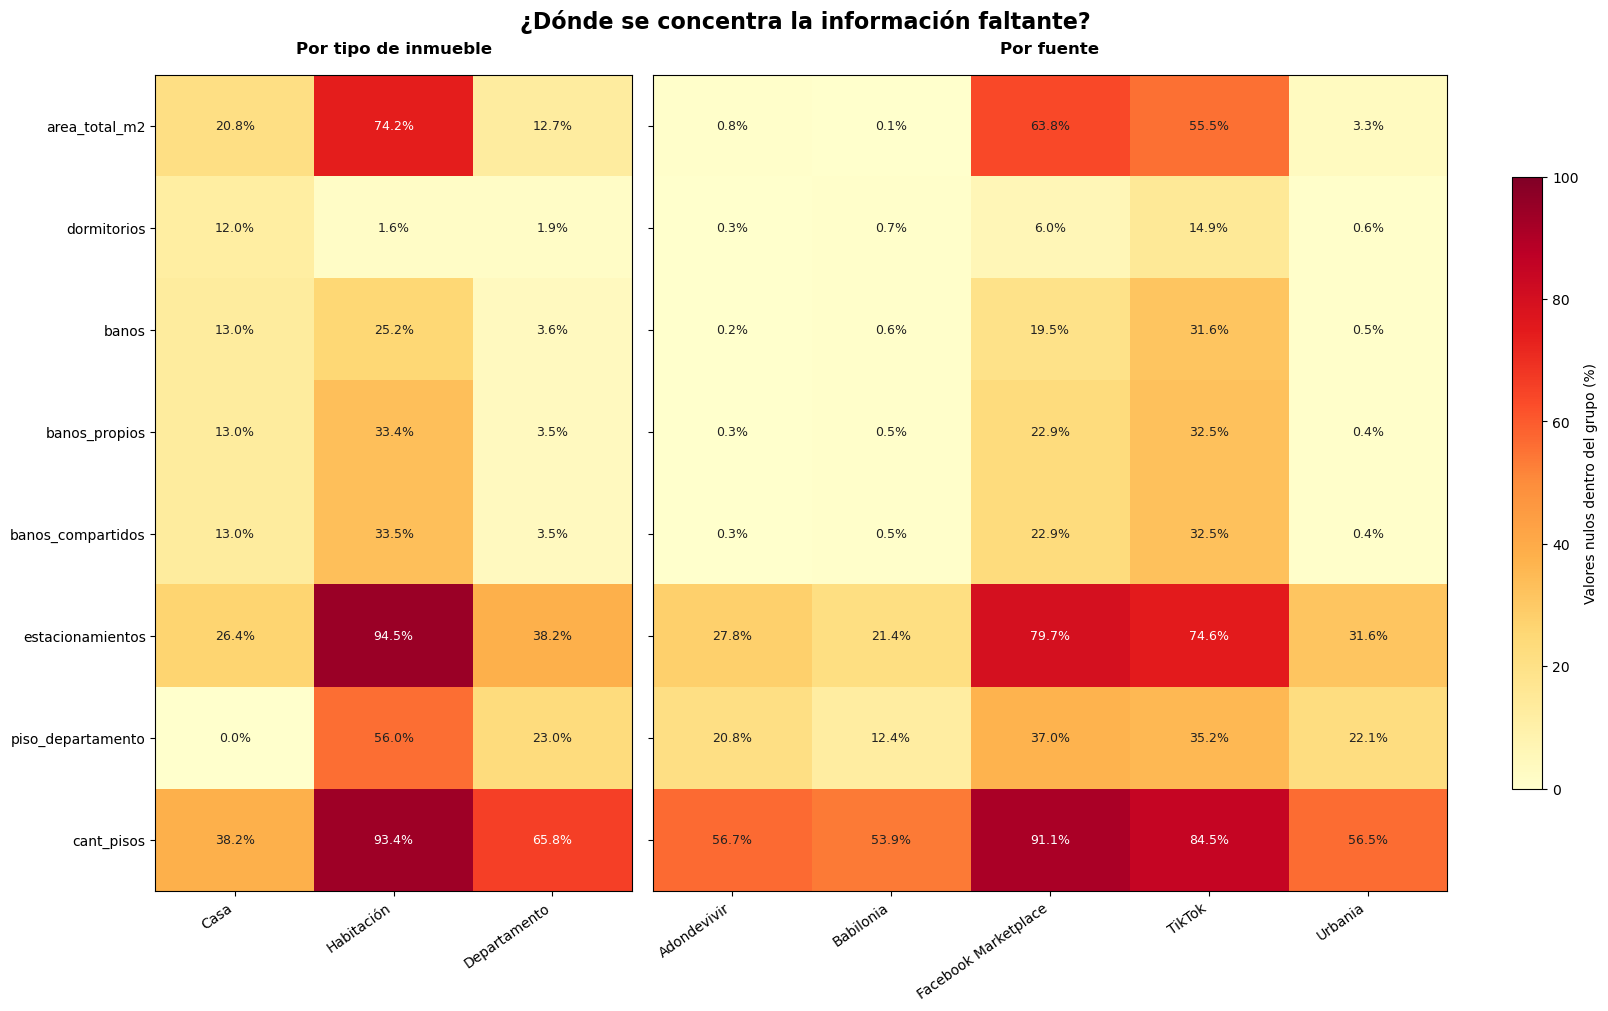

In [121]:
# ============================================================
# 7.1. VISUALIZACIÓN DE LOS PATRONES DE FALTANTES
# ============================================================

def graficar_faltantes_por_grupo(
    tabla_tipo: pd.DataFrame,
    tabla_fuente: pd.DataFrame,
):
    """Compara porcentajes de nulos con una escala común de 0 a 100."""

    etiquetas = {
        "cuarto": "Habitación",
        "casa": "Casa",
        "departamento": "Departamento",
        "adondevivir": "Adondevivir",
        "urbania": "Urbania",
        "babilonia": "Babilonia",
        "facebook_marketplace": "Facebook Marketplace",
        "tiktok": "TikTok",
    }

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 10),
        sharey=True,
        layout="constrained",
        gridspec_kw={"width_ratios": [3, 5]},
    )

    for ax, tabla, titulo in zip(
        axes,
        [tabla_tipo, tabla_fuente],
        ["Por tipo de inmueble", "Por fuente"],
    ):
        imagen = ax.imshow(
            tabla.to_numpy(dtype=float),
            cmap="YlOrRd",
            vmin=0,
            vmax=100,
            aspect="auto",
        )

        ax.set_xticks(range(len(tabla.columns)))
        ax.set_xticklabels(
            [etiquetas.get(col, str(col)) for col in tabla.columns],
            rotation=35,
            ha="right",
        )

        ax.set_yticks(range(len(tabla.index)))
        ax.set_yticklabels(tabla.index)
        ax.set_title(titulo, fontweight="bold", pad=15)

        for fila in range(tabla.shape[0]):
            for columna in range(tabla.shape[1]):
                valor = tabla.iloc[fila, columna]

                ax.text(
                    columna,
                    fila,
                    f"{valor:.1f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white" if valor >= 65 else "#222222",
                )

    fig.colorbar(
        imagen,
        ax=axes,
        label="Valores nulos dentro del grupo (%)",
        shrink=0.75,
    )

    fig.suptitle(
        "¿Dónde se concentra la información faltante?",
        fontsize=16,
        fontweight="bold",
    )

    return fig


fig_faltantes = graficar_faltantes_por_grupo(
    faltantes_por_tipo,
    faltantes_por_fuente,
)

plt.show()

### Interpretación del gráfico de valores nulos

El gráfico muestra el porcentaje de valores nulos de cada variable,
calculado dentro de cada tipo de inmueble y de cada fuente.
Los colores claros representan porcentajes bajos; los tonos rojos,
porcentajes altos. Estos porcentajes describen las celdas vacías,
pero su significado depende de la definición de cada variable.

**Por tipo de inmueble**

- El área total presenta mayor ausencia en habitaciones (74,19 %),
  seguida de casas (20,75 %) y departamentos (12,71 %). Excluir
  todos los registros sin área reduciría especialmente la muestra
  de habitaciones.
- Los dormitorios tienen mayor ausencia en casas (12,01 %).
  Por ello, la regla acordada de excluir registros sin dormitorios
  afectará proporcionalmente más a este tipo de inmueble.
- La información de baños tiene mayor ausencia en habitaciones:
  25,23 % en baños totales y alrededor de 33,5 % en baños propios
  y compartidos. Estos vacíos no deben interpretarse como ausencia
  de baño.
- La cantidad de pisos no está informada en el 93,43 % de las
  habitaciones y el 65,85 % de los departamentos. Esto limita
  su disponibilidad para el análisis.
- El piso del departamento no presenta nulos en casas. Sin embargo,
  tener un valor registrado no garantiza que sea correcto ni que
  tenga el mismo significado entre tipos de inmueble.

**Por fuente**

- Los faltantes de área total se concentran en Facebook Marketplace
  (63,76 %) y TikTok (55,52 %). En Adondevivir, Babilonia y Urbania
  los porcentajes son considerablemente menores.
- Facebook Marketplace y TikTok también presentan mayores
  porcentajes de nulos en dormitorios y variables de baños.
- Estas diferencias evidencian una cobertura desigual de las
  variables entre fuentes. El gráfico no permite determinar
  por sí solo si se debe al contenido de los anuncios, al proceso
  de extracción o a la composición de inmuebles de cada fuente.

**Caso particular: estacionamientos**

Según la definición proporcionada por el equipo, los vacíos de
estacionamientos significan que el inmueble no tiene estacionamiento.
Por tanto, aunque aparecen como nulos en el gráfico, se reemplazarán
por cero. Esta regla no se extiende a las demás variables.

**Decisión para la siguiente etapa**

Se excluirán los registros sin dormitorios y se completarán los
estacionamientos vacíos con cero. Se documentará el impacto de
ambas reglas. Los demás nulos permanecerán sin cambios hasta
completar su revisión.

## 8. Tratamiento inicial de datos

### Dormitorios faltantes

Se excluyen de la base de trabajo los anuncios sin información de
dormitorios. Esta variable describe la capacidad y distribución del
inmueble y forma parte de las características consideradas para
analizar el alquiler.

La exclusión comprende 189 de 7,061 anuncios (2.68 %), por lo que
se conserva el 97.32 % de los registros en esta etapa.

Aunque existen métodos de imputación, no se ha validado su precisión
en esta base. Se opta por trabajar con dormitorios observados y
evitar asignar cantidades estimadas sin evaluar previamente su
fiabilidad. La exclusión no se extiende automáticamente a otras
variables con datos faltantes.

Los registros excluidos se conservan por separado y el bloque 8.1
documenta el impacto por tipo de inmueble y fuente. Las conclusiones
posteriores corresponden a los anuncios que cumplen este criterio
de inclusión.

### Estacionamientos faltantes

Se reemplazan los valores nulos por cero conforme a la regla
establecida porque no es falta de datos sino por que el inmueble no cuenta con esa caracteristica.

Esta es una regla específica de estacionamientos y no se aplica
a las demás variables.

In [122]:
# ============================================================
# 8. TRATAMIENTO INICIAL Y TRAZABILIDAD
# ============================================================

def aplicar_tratamiento_inicial(datos: pd.DataFrame):
    """Aplica las reglas acordadas sin modificar el DataFrame recibido."""

    columnas_requeridas = [
        "id_anuncio",
        "tipo_inmueble",
        "portal",
        "dormitorios",
        "estacionamientos",
    ]

    faltantes = sorted(set(columnas_requeridas) - set(datos.columns))

    if faltantes:
        raise ValueError(f"Faltan columnas requeridas: {faltantes}")

    # --------------------------------------------------------
    # 1. Separar registros sin dormitorios
    # --------------------------------------------------------
    sin_dormitorios = datos["dormitorios"].isna()

    excluidos = datos.loc[sin_dormitorios].copy()
    excluidos["motivo_exclusion"] = "Dormitorios sin información"

    tratados = datos.loc[~sin_dormitorios].copy()

    # --------------------------------------------------------
    # 2. Registrar y completar estacionamientos faltantes
    #    Se aplica únicamente a los registros conservados.
    # --------------------------------------------------------
    sin_estacionamientos = tratados["estacionamientos"].isna()

    cambios = tratados.loc[
        sin_estacionamientos,
        ["id_anuncio", "tipo_inmueble", "portal", "estacionamientos"],
    ].copy()

    cambios = cambios.rename(
        columns={"estacionamientos": "valor_anterior"}
    )
    cambios["valor_nuevo"] = 0
    cambios["motivo"] = (
        "Vacío significa que no tiene estacionamiento, según el equipo"
    )

    tratados["estacionamientos"] = (
        tratados["estacionamientos"].fillna(0)
    )

    # --------------------------------------------------------
    # 3. Balance y verificaciones
    # --------------------------------------------------------
    balance = pd.DataFrame({
        "concepto": [
            "Registros de entrada",
            "Registros excluidos por dormitorios faltantes",
            "Registros conservados",
            "Estacionamientos completados con cero",
        ],
        "cantidad": [
            len(datos),
            len(excluidos),
            len(tratados),
            len(cambios),
        ],
    })

    assert len(datos) == len(tratados) + len(excluidos)
    assert tratados["dormitorios"].notna().all()
    assert tratados["estacionamientos"].notna().all()
    assert tratados.columns.equals(datos.columns)

    return tratados, excluidos, cambios, balance


# Resultado de esta etapa en un objeto separado.
# df conserva la base utilizada en el bloque 7.
(
    df_tratado,
    excluidos_dormitorios,
    cambios_estacionamientos,
    balance_tratamiento,
) = aplicar_tratamiento_inicial(df)

display(balance_tratamiento)

,concepto,cantidad
0,Registros de entrada,7061
1,Registros excluidos por dormitorios faltantes,189
2,Registros conservados,6872
3,Estacionamientos completados con cero,2965


In [123]:
# ============================================================
# 8.1. IMPACTO DE LA EXCLUSIÓN POR TIPO Y FUENTE
# ============================================================

def resumir_impacto_exclusion(
    datos: pd.DataFrame,
    grupo: str,
) -> pd.DataFrame:
    """Calcula las exclusiones por dormitorios faltantes en cada grupo."""

    resumen = (
        datos.assign(
            excluir_sin_dormitorios=datos["dormitorios"].isna()
        )
        .groupby(grupo, dropna=False, observed=True)
        .agg(
            registros_antes=("excluir_sin_dormitorios", "size"),
            excluidos=("excluir_sin_dormitorios", "sum"),
        )
        .reset_index()
    )

    resumen["registros_despues"] = (
        resumen["registros_antes"] - resumen["excluidos"]
    )

    resumen["excluidos_pct"] = (
        resumen["excluidos"]
        .div(resumen["registros_antes"])
        .mul(100)
        .round(2)
    )

    return resumen


print("IMPACTO POR TIPO DE INMUEBLE")
display(resumir_impacto_exclusion(df, "tipo_inmueble"))

print("IMPACTO POR FUENTE")
display(resumir_impacto_exclusion(df, "portal"))

IMPACTO POR TIPO DE INMUEBLE


,tipo_inmueble,registros_antes,excluidos,registros_despues,excluidos_pct
0,casa,583,70,513,12.01
1,cuarto,868,14,854,1.61
2,departamento,5610,105,5505,1.87


IMPACTO POR FUENTE


,portal,registros_antes,excluidos,registros_despues,excluidos_pct
0,adondevivir,2270,8,2262,0.35
1,babilonia,869,6,863,0.69
2,facebook_marketplace,1912,115,1797,6.01
3,tiktok,335,50,285,14.93
4,urbania,1675,10,1665,0.60


## 9. Validación inicial de variables numéricas

Revisamos el formato y los rangos de las variables numéricas
en la base tratada.

Identificamos valores no numéricos, infinitos, negativos, ceros
y valores fraccionarios. Estas señales requieren interpretación
según cada variable y no implican exclusión automática.

La revisión no modifica df_tratado.

In [124]:
# ============================================================
# 9.1. VALIDACIÓN DE VARIABLES NUMÉRICAS
# ============================================================

import numpy as np

VARIABLES_NUMERICAS = [
    "precio_pen_pub",
    "area_total_m2",
    "dormitorios",
    "banos",
    "banos_propios",
    "banos_compartidos",
    "estacionamientos",
    "piso_departamento",
    "cant_pisos",
]


def diagnosticar_numericas(
    datos: pd.DataFrame,
    variables: list[str],
) -> pd.DataFrame:
    """Revisa formato y rangos sin modificar la base de entrada."""

    faltantes = sorted(set(variables) - set(datos.columns))

    if faltantes:
        raise ValueError(f"Faltan columnas requeridas: {faltantes}")

    filas = []

    for variable in variables:
        original = datos[variable]

        # Conversión temporal para el diagnóstico
        numerica = pd.to_numeric(
            original, errors="coerce"
        ).astype("float64")

        es_finito = pd.Series(
            np.isfinite(numerica.to_numpy()),
            index=datos.index,
        )

        valores = numerica.loc[es_finito]

        fraccionarios = (
            ~np.isclose(
                valores.to_numpy(),
                np.round(valores.to_numpy()),
                rtol=0,
                atol=1e-8,
            )
        ).sum()

        filas.append({
            "variable": variable,
            "nulos_originales": int(original.isna().sum()),
            "no_numericos": int(
                (original.notna() & numerica.isna()).sum()
            ),
            "infinitos": int(
                (numerica.notna() & ~es_finito).sum()
            ),
            "negativos": int(valores.lt(0).sum()),
            "ceros": int(valores.eq(0).sum()),
            "fraccionarios": int(fraccionarios),
            "minimo": valores.min(),
            "p01": valores.quantile(0.01),
            "mediana": valores.median(),
            "p99": valores.quantile(0.99),
            "maximo": valores.max(),
        })

    return pd.DataFrame(filas)


diagnostico_numerico = diagnosticar_numericas(
    df_tratado,
    VARIABLES_NUMERICAS,
)

with pd.option_context(
    "display.max_columns", None,
    "display.max_rows", None,
):
    display(diagnostico_numerico.round(2))

,variable,nulos_originales,no_numericos,infinitos,negativos,ceros,fraccionarios,minimo,p01,mediana,p99,maximo
0,precio_pen_pub,0,0,0,0,0,1,1.00,250.00,"2,400.00","29,639.73","918,000.00"
1,area_total_m2,1340,0,0,0,0,80,0.19,12.00,74.00,"1,009.38","69,090.00"
2,dormitorios,0,0,0,0,0,0,1.00,1.00,2.00,6.00,15.00
3,banos,345,0,0,0,1,116,0.00,0.50,2.00,5.00,12.00
4,banos_propios,415,0,0,0,502,0,0.00,0.00,2.00,5.00,12.00
5,banos_compartidos,416,0,0,0,5955,0,0.00,0.00,0.00,1.00,7.00
6,estacionamientos,0,0,0,0,3445,0,0.00,0.00,0.00,4.00,20.00
7,piso_departamento,1700,0,0,0,513,0,0.00,0.00,4.00,24.00,38.00
8,cant_pisos,4566,0,0,0,0,0,1.00,1.00,5.00,31.00,40.00


In [125]:
# ============================================================
# 9.2. IDENTIFICACIÓN DE VALORES QUE REQUIEREN REVISIÓN
# ============================================================

import numpy as np
import pandas as pd


def identificar_inconsistencias(datos: pd.DataFrame) -> pd.DataFrame:
    """Identifica problemas de dominio y sospechas sin modificar datos."""

    variables = [
        "precio_pen_pub", "area_total_m2", "dormitorios",
        "banos", "banos_propios", "banos_compartidos",
        "estacionamientos", "piso_departamento", "cant_pisos",
    ]

    requeridas = {"id_anuncio", "tipo_inmueble", "portal", *variables}
    faltantes = requeridas - set(datos.columns)

    if faltantes:
        raise ValueError(f"Faltan columnas: {sorted(faltantes)}")

    base = datos.reset_index(drop=True)
    numericas = base[variables].apply(pd.to_numeric, errors="coerce")
    registros = []

    def registrar(mascara, variable, categoria, motivo):
        for indice in base.index[mascara.fillna(False)]:
            registros.append({
                "id_anuncio": base.at[indice, "id_anuncio"],
                "tipo_inmueble": base.at[indice, "tipo_inmueble"],
                "portal": base.at[indice, "portal"],
                "variable": variable,
                "valor_original": base.at[indice, variable],
                "categoria": categoria,
                "motivo": motivo,
            })

    # 1. Formato y dominio de las variables.
    conteos_enteros = {
        "dormitorios", "banos_propios", "banos_compartidos",
        "estacionamientos", "piso_departamento", "cant_pisos",
    }

    for variable in variables:
        serie = numericas[variable]
        finitos = serie.notna() & np.isfinite(serie)

        registrar(
            base[variable].notna() & serie.isna(),
            variable, "Formato",
            "Valor no interpretable como número; contrastar fuente.",
        )
        registrar(
            serie.notna() & ~np.isfinite(serie),
            variable, "Dominio",
            "Valor infinito: no representa una medición válida.",
        )

        if variable != "piso_departamento":
            registrar(
                finitos & serie.lt(0),
                variable, "Dominio",
                "Valor negativo incompatible con la variable.",
            )

        if variable in {"precio_pen_pub", "area_total_m2", "cant_pisos"}:
            registrar(
                finitos & serie.eq(0),
                variable, "Dominio",
                "Cero no representa un valor válido para esta variable.",
            )

        if variable in conteos_enteros:
            fraccionario = ~np.isclose(
                serie.fillna(0), serie.fillna(0).round(),
                rtol=0, atol=1e-8,
            )
            registrar(
                finitos & fraccionario,
                variable, "Dominio",
                "El conteo debe expresarse como número entero.",
            )

    # 2. Valores sospechosos: requieren evidencia antes de corregir.
    registrar(
        numericas["area_total_m2"].gt(0)
        & numericas["area_total_m2"].lt(5),
        "area_total_m2", "Sospecha",
        "Área de hasta 5 m²: verificar unidad, extracción y espacio alquilado.",
    )
    registrar(
        numericas["precio_pen_pub"].gt(0)
        & numericas["precio_pen_pub"].le(1),
        "precio_pen_pub", "Sospecha",
        "Precio posiblemente simbólico; verificar alquiler mensual.",
    )
    registrar(
        base["tipo_inmueble"].eq("cuarto")
        & numericas["dormitorios"].gt(1),
        "dormitorios", "Sospecha",
        "Podría describir toda la vivienda y no la habitación alquilada.",
    )

    for variable in ["dormitorios", "banos"]:
        registrar(
            numericas[variable].eq(0),
            variable, "Sospecha",
            "Verificar significado del cero; no asumir que es un faltante.",
        )

    registrar(
        numericas["piso_departamento"].lt(0),
        "piso_departamento", "Sospecha",
        "Verificar si corresponde a un sótano.",
    )

    # 3. Coherencia entre variables.
    piso_incompatible = numericas["piso_departamento"].gt(
        numericas["cant_pisos"]
    )
    for variable in ["piso_departamento", "cant_pisos"]:
        registrar(
            piso_incompatible, variable, "Coherencia",
            "Piso de ubicación superior al total de pisos; revisar definiciones.",
        )

    for componente in ["banos_propios", "banos_compartidos"]:
        incompatibles = numericas[componente].gt(numericas["banos"])
        for variable in [componente, "banos"]:
            registrar(
                incompatibles, variable, "Coherencia",
                f"{componente} supera a banos; contrastar ambos campos.",
            )

    columnas = [
        "id_anuncio", "tipo_inmueble", "portal", "variable",
        "valor_original", "categoria", "motivo",
    ]
    return pd.DataFrame(registros, columns=columnas).drop_duplicates()


revision_numerica = identificar_inconsistencias(df_tratado)

resumen_revision_numerica = (
    revision_numerica
    .groupby(["variable", "categoria"], as_index=False)
    .agg(anuncios=("id_anuncio", "nunique"))
)

display(resumen_revision_numerica)

print(
    "Anuncios distintos para revisión:",
    revision_numerica["id_anuncio"].nunique(),
)

display(
    revision_numerica.loc[
        revision_numerica["variable"].eq("area_total_m2")
    ]
)

,variable,categoria,anuncios
0,area_total_m2,Sospecha,28
1,banos,Coherencia,2
2,banos,Sospecha,1
3,banos_compartidos,Coherencia,1
4,banos_propios,Coherencia,1
5,cant_pisos,Coherencia,2
6,dormitorios,Sospecha,34
7,piso_departamento,Coherencia,2
8,precio_pen_pub,Sospecha,3


Anuncios distintos para revisión: 68


,id_anuncio,tipo_inmueble,portal,variable,valor_original,categoria,motivo
0,adondevivir-151071818,cuarto,adondevivir,area_total_m2,1.00,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
1,urbania-151504934,departamento,urbania,area_total_m2,1.00,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
2,facebook_marketplace-1835930997829824,cuarto,facebook_marketplace,area_total_m2,1.11,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
3,facebook_marketplace-1696889498033694,cuarto,facebook_marketplace,area_total_m2,1.11,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
4,facebook_marketplace-1089420580815304,cuarto,facebook_marketplace,area_total_m2,1.86,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
5,facebook_marketplace-2356237448462221,cuarto,facebook_marketplace,area_total_m2,1.39,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
6,facebook_marketplace-1048048961200945,cuarto,facebook_marketplace,area_total_m2,1.11,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
7,facebook_marketplace-1490680636291643,cuarto,facebook_marketplace,area_total_m2,1.39,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
8,facebook_marketplace-2467738723716279,cuarto,facebook_marketplace,area_total_m2,0.74,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."
9,facebook_marketplace-1461563199513272,cuarto,facebook_marketplace,area_total_m2,1.58,Sospecha,"Área de hasta 5 m²: verificar unidad, extracción y espac..."


### Interpretación del diagnóstico numérico

Se distinguen problemas de formato, valores incompatibles con el
dominio de la variable y sospechas que requieren contrastar la fuente.

Las áreas de hasta 5 m² se seleccionan para revisión. Este umbral
no demuestra por sí solo que el dato sea incorrecto ni autoriza
multiplicarlo por un factor para obtener un área aparentemente válida.

Los valores fraccionarios de precio y área son admisibles.
Los baños pueden incluir medios baños; no se redondean automáticamente.



## 10. Distribución inicial de precio y área por tipo de inmueble

Comparamos casas, habitaciones y departamentos mediante diagramas
de caja con eje logarítmico.

Se representan todos los valores positivos y finitos disponibles.
Los nulos no pueden representarse y se contabilizan aparte.
No se eliminan registros ni se transforma la base.

Los puntos fuera de los bigotes son valores extremos según la regla
gráfica de 1,5 veces el rango intercuartílico; no son necesariamente errores.

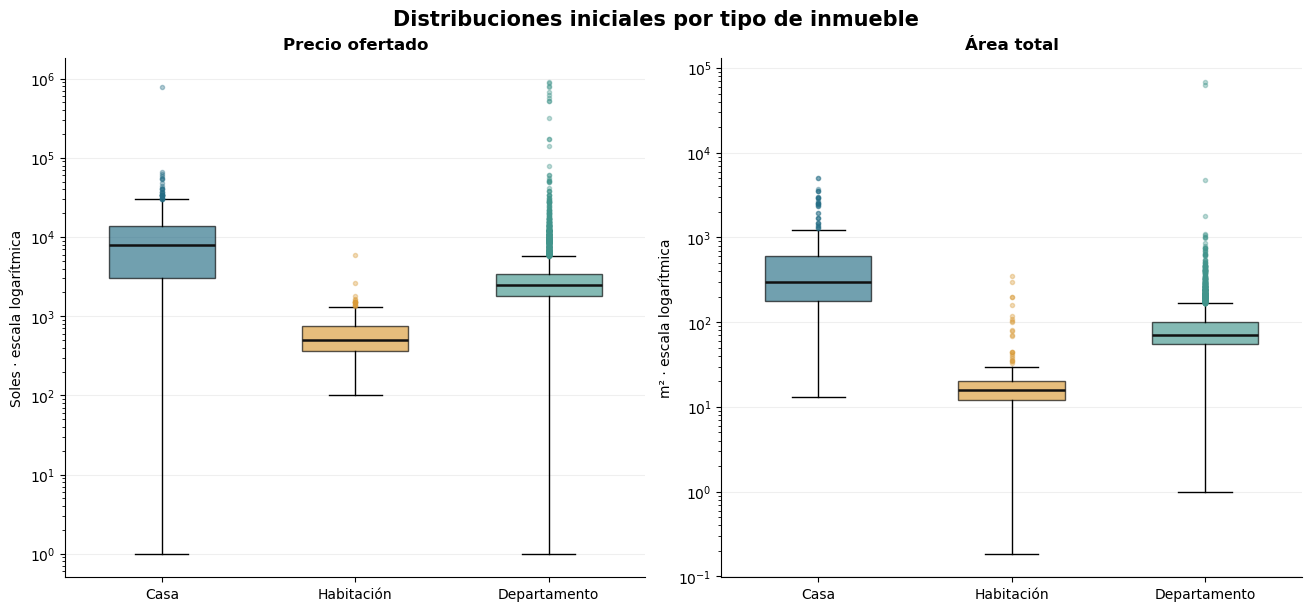

,variable,tipo_inmueble,registros,graficados,nulos,otros_no_representables
0,precio_pen_pub,casa,513,513,0,0
1,precio_pen_pub,cuarto,854,854,0,0
2,precio_pen_pub,departamento,5505,5505,0,0
3,area_total_m2,casa,513,435,78,0
4,area_total_m2,cuarto,854,220,634,0
5,area_total_m2,departamento,5505,4877,628,0


In [126]:
# ============================================================
# 10. PRECIO Y ÁREA POR TIPO DE INMUEBLE
# ============================================================

def graficar_precio_area(datos: pd.DataFrame):
    """Compara distribuciones sin modificar ni recortar la base."""

    tipos = ["casa", "cuarto", "departamento"]
    nombres = ["Casa", "Habitación", "Departamento"]
    colores = ["#256D85", "#D99A36", "#42958C"]

    configuracion = [
        ("precio_pen_pub", "Precio ofertado", "Soles · escala logarítmica"),
        ("area_total_m2", "Área total", "m² · escala logarítmica"),
    ]

    cobertura = []

    with plt.rc_context({
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }):
        fig, axes = plt.subplots(
            1, 2,
            figsize=(13, 6),
            layout="constrained",
        )

        for ax, (variable, titulo, unidad) in zip(
            axes, configuracion
        ):
            for posicion, (tipo, nombre, color) in enumerate(
                zip(tipos, nombres, colores),
                start=1,
            ):
                original = datos.loc[
                    datos["tipo_inmueble"].eq(tipo), variable
                ]

                numerica = pd.to_numeric(
                    original, errors="coerce"
                ).astype("float64")

                representable = (
                    np.isfinite(numerica.to_numpy())
                    & numerica.gt(0).to_numpy()
                )

                valores = numerica.loc[representable]

                cobertura.append({
                    "variable": variable,
                    "tipo_inmueble": tipo,
                    "registros": len(original),
                    "graficados": len(valores),
                    "nulos": int(original.isna().sum()),
                    "otros_no_representables": int(
                        len(original)
                        - len(valores)
                        - original.isna().sum()
                    ),
                })

                if valores.empty:
                    continue

                caja = ax.boxplot(
                    valores.to_numpy(),
                    positions=[posicion],
                    widths=0.55,
                    patch_artist=True,
                    showfliers=True,
                    whis=1.5,
                    medianprops={
                        "color": "#111111",
                        "linewidth": 1.8,
                    },
                    flierprops={
                        "marker": "o",
                        "markersize": 3,
                        "alpha": 0.35,
                        "markeredgecolor": color,
                        "markerfacecolor": color,
                    },
                )

                caja["boxes"][0].set_facecolor(color)
                caja["boxes"][0].set_alpha(0.65)

            ax.set_xticks([1, 2, 3])
            ax.set_xticklabels(nombres)
            ax.set_yscale("log")
            ax.set_ylabel(unidad)
            ax.set_title(titulo, fontweight="bold")
            ax.grid(axis="y", which="major", alpha=0.2)

        fig.suptitle(
            "Distribuciones iniciales por tipo de inmueble",
            fontsize=15,
            fontweight="bold",
        )

    return fig, pd.DataFrame(cobertura)


fig_distribuciones, cobertura_graficos = graficar_precio_area(
    df_tratado
)

plt.show()
display(cobertura_graficos)

### Interpretación de las distribuciones de precio y área

Los diagramas de caja muestran diferencias entre casas, departamentos
y habitaciones. La línea central representa la mediana y la caja
contiene el 50 % central de los valores.

Los ejes utilizan una escala logarítmica: cada salto principal
multiplica el valor por diez. Esto permite visualizar magnitudes
muy distintas sin eliminar los extremos ni modificar la base.

#### Precio ofertado

Las casas presentan la mediana de precio más alta, seguidas por
los departamentos y las habitaciones. Las casas también muestran
una mayor dispersión en el 50 % central de sus precios.

En casas y departamentos se observan precios mínimos de S/1 y
valores superiores de varios cientos de miles de soles. Estos casos
requieren verificar la moneda, la periodicidad y si corresponden
realmente a alquileres o a posibles errores de extracción.

Los departamentos presentan numerosos puntos extremos, pero también
constituyen el grupo con más registros. Por tanto, una mayor cantidad
de puntos no implica necesariamente una mayor proporción de anomalías.

#### Área total

Las casas presentan áreas típicas mayores, seguidas por los
departamentos y las habitaciones. Sin embargo, se observan superficies
que requieren revisión: habitaciones con menos de 1 m² o con cientos
de metros cuadrados y departamentos con decenas de miles de metros
cuadrados.

En habitaciones, algunas áreas elevadas podrían corresponder a toda
la vivienda y no al cuarto alquilado. Esta posibilidad debe verificarse
antes de corregir o excluir registros.

La disponibilidad del área es diferente entre grupos:

| Tipo de inmueble | Registros con área | Total de registros | Cobertura |
|---|---:|---:|---:|
| Casa | 435 | 513 | 84,80 % |
| Habitación | 220 | 854 | 25,76 % |
| Departamento | 4.877 | 5.505 | 88,59 % |

La distribución del área de habitaciones representa únicamente los
220 registros con información disponible. No podemos asumir que
las habitaciones sin área tengan las mismas características.
El gráfico de precios, en cambio, incluye todos los registros conservados.

#### Implicaciones para el análisis

Los resultados justifican analizar precio y área por tipo de inmueble.
Se priorizará la revisión de precios de S/1, precios extraordinariamente
altos y superficies extremas.

Los puntos fuera de los bigotes son valores atípicos según la regla
gráfica, pero no necesariamente errores. Asimismo, un valor dentro
de los bigotes no garantiza que sea válido. En esta etapa no se
eliminan registros automáticamente.

In [127]:
# ============================================================
# 10.1. VERIFICACIÓN DE CEROS EN PISO POR TIPO
# ============================================================

revision_piso = (
    df_tratado.groupby("tipo_inmueble", observed=True)
    ["piso_departamento"]
    .agg(
        registros="size",
        ceros=lambda serie: serie.eq(0).sum(),
        nulos=lambda serie: serie.isna().sum(),
        positivos=lambda serie: serie.gt(0).sum(),
    )
    .reset_index()
)

display(revision_piso)

,tipo_inmueble,registros,ceros,nulos,positivos
0,casa,513,513,0,0
1,cuarto,854,0,476,378
2,departamento,5505,0,1224,4281


## 11. Identificación de anuncios para revisión

Se identifican registros con precios o áreas que requieren inspección.

La selección incluye precios de S/1 o menos, áreas de 1 m² o menos
y los tres valores más bajos y más altos de cada variable por tipo
de inmueble.

Estos criterios organizan la revisión, pero no determinan que un
registro sea incorrecto. No se eliminan filas ni se modifican valores.

La selección de extremos no constituye una auditoría completa:
pueden existir inconsistencias en otros registros.

In [128]:
# ============================================================
# 11.1. IDENTIFICACIÓN DE CASOS PARA REVISIÓN
# ============================================================

def identificar_casos_revision(
    datos: pd.DataFrame,
    n_extremos: int = 3,
) -> pd.DataFrame:
    """Selecciona casos para inspección sin modificar la base."""

    requeridas = [
        "id_anuncio",
        "tipo_inmueble",
        "precio_pen_pub",
        "area_total_m2",
    ]

    faltantes = sorted(set(requeridas) - set(datos.columns))

    if faltantes:
        raise ValueError(f"Faltan columnas requeridas: {faltantes}")

    if n_extremos < 1:
        raise ValueError("n_extremos debe ser mayor o igual a 1.")

    # Índice temporal único para identificar las filas con seguridad
    base = datos.copy().reset_index(drop=True)

    motivos = {indice: [] for indice in base.index}

    def registrar(indices, motivo):
        for indice in indices:
            motivos[indice].append(motivo)

    # Señales prioritarias de revisión
    registrar(
        base.index[base["precio_pen_pub"].le(1)],
        "Precio de S/1 o menos",
    )

    registrar(
        base.index[base["area_total_m2"].le(1)],
        "Área de 1 m² o menos",
    )

    # Extremos por tipo: selección exploratoria, no exclusión
    for tipo, grupo in base.groupby(
        "tipo_inmueble",
        dropna=False,
        observed=True,
    ):
        for variable in ["precio_pen_pub", "area_total_m2"]:
            valores = grupo[variable].dropna()

            registrar(
                valores.nsmallest(n_extremos).index,
                f"{variable}: entre los {n_extremos} menores de {tipo}",
            )

            registrar(
                valores.nlargest(n_extremos).index,
                f"{variable}: entre los {n_extremos} mayores de {tipo}",
            )

    seleccionados = [
        indice
        for indice, lista_motivos in motivos.items()
        if lista_motivos
    ]

    revision = base.loc[seleccionados].copy()

    revision["motivo_revision"] = [
        " | ".join(motivos[indice])
        for indice in seleccionados
    ]

    revision["estado_revision"] = "Pendiente"

    return (
        revision.sort_values(
            ["tipo_inmueble", "precio_pen_pub"],
            kind="stable",
        )
        .reset_index(drop=True)
    )


casos_revision = identificar_casos_revision(
    df_tratado,
    n_extremos=3,
)

columnas_mostrar = [
    "id_anuncio",
    "portal",
    "tipo_inmueble",
    "distrito",
    "precio_pen_pub",
    "area_total_m2",
    "dormitorios",
    "banos",
    "motivo_revision",
]

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", 150,
):
    display(casos_revision[columnas_mostrar])

print(f"Registros seleccionados para revisión: {len(casos_revision)}")
print(f"Registros conservados en df_tratado: {len(df_tratado)}")

,id_anuncio,portal,tipo_inmueble,distrito,precio_pen_pub,area_total_m2,dormitorios,banos,motivo_revision
0,adondevivir-145353217,adondevivir,casa,lurin,1.00,"1,700.00",4.00,4.00,Precio de S/1 o menos | precio_pen_pub: entre los 3 menores de casa
1,urbania-65949884,urbania,casa,punta hermosa,1.00,"1,700.00",4.00,4.00,Precio de S/1 o menos | precio_pen_pub: entre los 3 menores de casa
2,facebook_marketplace-1008147191667796,facebook_marketplace,casa,pachacamac,250.00,58.34,3.00,3.00,precio_pen_pub: entre los 3 menores de casa
3,facebook_marketplace-1132669945813121,facebook_marketplace,casa,independencia,550.00,21.00,4.00,2.00,area_total_m2: entre los 3 menores de casa
4,urbania-151566391,urbania,casa,magdalena del mar,770.00,15.00,1.00,1.00,area_total_m2: entre los 3 menores de casa
5,babilonia-172253,babilonia,casa,cieneguilla,"13,672.00","3,768.00",4.00,4.00,area_total_m2: entre los 3 mayores de casa
6,adondevivir-150251130,adondevivir,casa,carabayllo,"30,600.00","5,000.00",5.00,5.00,area_total_m2: entre los 3 mayores de casa
7,babilonia-124458,babilonia,casa,la molina,"30,762.00","5,000.00",5.00,5.00,area_total_m2: entre los 3 mayores de casa
8,adondevivir-149762285,adondevivir,casa,santiago de surco,"33,500.00",13.00,4.00,5.00,area_total_m2: entre los 3 menores de casa
9,urbania-149316037,urbania,casa,san isidro,"62,134.00",783.00,4.00,4.00,precio_pen_pub: entre los 3 mayores de casa


Registros seleccionados para revisión: 36
Registros conservados en df_tratado: 6872


In [129]:
# ============================================================
# 11.2. ALCANCE DE LA REVISIÓN
# ============================================================

totales_tipo = (
    df_tratado.groupby("tipo_inmueble", observed=True)
    .size()
    .rename("registros_base")
)

senalados_tipo = (
    casos_revision.groupby("tipo_inmueble", observed=True)
    .size()
    .rename("registros_senalados")
)

resumen_revision = (
    totales_tipo.to_frame()
    .join(senalados_tipo)
)

resumen_revision["registros_senalados"] = (
    resumen_revision["registros_senalados"]
    .fillna(0)
    .astype(int)
)

resumen_revision["senalados_pct"] = (
    resumen_revision["registros_senalados"]
    .div(resumen_revision["registros_base"])
    .mul(100)
    .round(2)
)

display(resumen_revision.reset_index())

,tipo_inmueble,registros_base,registros_senalados,senalados_pct
0,casa,513,12,2.34
1,cuarto,854,12,1.41
2,departamento,5505,12,0.22


In [130]:
# ============================================================
# 11.3. DECISIONES SOBRE ÁREAS MENORES DE 5 M²
# Contraste realizado con la base original de este proyecto.
# ============================================================

casos_area = (
    revision_numerica.loc[
        revision_numerica["variable"].eq("area_total_m2")
        & pd.to_numeric(
            revision_numerica["valor_original"], errors="coerce"
        ).between(0, 5, inclusive="neither")
    ]
    .drop_duplicates(["id_anuncio", "variable"])
    .copy()
)

decisiones_areas = casos_area[
    ["id_anuncio", "variable", "valor_original"]
].rename(columns={"valor_original": "valor_esperado"})

decisiones_areas["accion"] = "no_verificado"
decisiones_areas["valor_nuevo"] = np.nan
decisiones_areas["evidencia"] = (
    "Área menor de 5 m² no verificada. Se contrastaron los textos "
    "y campos de superficie disponibles en la base original, "
    "sin identificar un reemplazo fiable para la unidad alquilada."
)

display(decisiones_areas)
print(f"Áreas propuestas para reemplazar por NaN: {len(decisiones_areas)}")

,id_anuncio,variable,valor_esperado,accion,valor_nuevo,evidencia
0,adondevivir-151071818,area_total_m2,1.00,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
1,urbania-151504934,area_total_m2,1.00,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
2,facebook_marketplace-1835930997829824,area_total_m2,1.11,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
3,facebook_marketplace-1696889498033694,area_total_m2,1.11,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
4,facebook_marketplace-1089420580815304,area_total_m2,1.86,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
5,facebook_marketplace-2356237448462221,area_total_m2,1.39,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
6,facebook_marketplace-1048048961200945,area_total_m2,1.11,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
7,facebook_marketplace-1490680636291643,area_total_m2,1.39,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
8,facebook_marketplace-2467738723716279,area_total_m2,0.74,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...
9,facebook_marketplace-1461563199513272,area_total_m2,1.58,no_verificado,NaN,Área menor de 5 m² no verificada. Se contrastaron los te...


Áreas propuestas para reemplazar por NaN: 28


### Resultado de la revisión inicial de casos

Se revisaron los 36 registros seleccionados y se contrastaron algunos
con las descripciones conservadas en la base original.

La revisión identificó problemas de distinta naturaleza:

- Un anuncio de venta incluido en la base de alquileres.
- Un alquiler semanal clasificado como mensual.
- Dos superficies inconsistentes con las áreas indicadas
  explícitamente en las descripciones.
- Dos departamentos completos clasificados como habitaciones.

Estos hallazgos muestran que los extremos no deben tratarse mediante
una única regla de eliminación: algunos requieren exclusión por estar
fuera del alcance, otros permiten una corrección documentada y otros
necesitan reclasificación.

Los casos sin evidencia suficiente permanecen pendientes. No se
corrigen superficies suponiendo una posición decimal ni se eliminan
anuncios únicamente por presentar precios elevados.

Las descripciones se consultan como respaldo de auditoría, sin
reincorporarlas como predictores del modelo.

Esta revisión es parcial y no permite afirmar que el resto de la
base esté libre de inconsistencias.

## 12. Correcciones y exclusiones documentadas

Se aplican las decisiones sustentadas en las descripciones
conservadas en la base original:

- Excluir un anuncio de venta y un alquiler semanal.
- Corregir dos áreas según las superficies indicadas en las descripciones.
- Reclasificar dos habitaciones como departamentos completos.

Cada decisión registra el identificador, la variable afectada,
el valor anterior, el valor nuevo y la evidencia.

El resultado se almacena en df_revisado. La base df_tratado
permanece sin modificaciones y los casos no resueltos siguen pendientes.

In [131]:
# ============================================================
# 12.1. DECISIONES RESPALDADAS POR EVIDENCIA
# ============================================================

decisiones_revision = pd.DataFrame([
    {
        "id_anuncio": "adondevivir-146611227",
        "accion": "excluir",
        "variable": None,
        "valor_esperado": None,
        "valor_nuevo": None,
        "evidencia": (
            "La descripción indica 'Se vende'. "
            "No corresponde al alcance de alquileres."
        ),
    },
    {
        "id_anuncio": "adondevivir-150945833",
        "accion": "excluir",
        "variable": None,
        "valor_esperado": None,
        "valor_nuevo": None,
        "evidencia": (
            "La descripción especifica alquiler por semana. "
            "No corresponde a una oferta de alquiler mensual."
        ),
    },
    {
        "id_anuncio": "adondevivir-151444416",
        "accion": "corregir",
        "variable": "area_total_m2",
        "valor_esperado": 62520.0,
        "valor_nuevo": 62.52,
        "evidencia": (
            "La descripción indica explícitamente un área de 62.52 m²."
        ),
    },
    {
        "id_anuncio": "urbania-149292240",
        "accion": "corregir",
        "variable": "area_total_m2",
        "valor_esperado": 4756.0,
        "valor_nuevo": 47.56,
        "evidencia": (
            "La descripción detallada indica 47.56 m². "
            "Se prioriza frente al campo estructurado y al título, "
            "que contienen cifras inconsistentes."
        ),
    },
    {
        "id_anuncio": "adondevivir-146077408",
        "accion": "corregir",
        "variable": "tipo_inmueble",
        "valor_esperado": "cuarto",
        "valor_nuevo": "departamento",
        "evidencia": (
            "La descripción ofrece un departamento dúplex completo, "
            "con sala, cocina y tres dormitorios."
        ),
    },
    {
        "id_anuncio": "adondevivir-150915584",
        "accion": "corregir",
        "variable": "tipo_inmueble",
        "valor_esperado": "cuarto",
        "valor_nuevo": "departamento",
        "evidencia": (
            "La descripción ofrece un departamento completo "
            "de tres dormitorios."
        ),
    },
])

display(decisiones_revision)

,id_anuncio,accion,variable,valor_esperado,valor_nuevo,evidencia
0,adondevivir-146611227,excluir,NaN,None,None,La descripción indica 'Se vende'. No corresponde al alca...
1,adondevivir-150945833,excluir,NaN,None,None,La descripción especifica alquiler por semana. No corres...
2,adondevivir-151444416,corregir,area_total_m2,"62,520.00",62.52,La descripción indica explícitamente un área de 62.52 m².
3,urbania-149292240,corregir,area_total_m2,"4,756.00",47.56,La descripción detallada indica 47.56 m². Se prioriza fr...
4,adondevivir-146077408,corregir,tipo_inmueble,cuarto,departamento,"La descripción ofrece un departamento dúplex completo, c..."
5,adondevivir-150915584,corregir,tipo_inmueble,cuarto,departamento,La descripción ofrece un departamento completo de tres d...


In [132]:
# ============================================================
# 12.2. APLICACIÓN CONTROLADA DE DECISIONES
# ============================================================

import numpy as np
import pandas as pd


def aplicar_decisiones(
    datos: pd.DataFrame,
    decisiones: pd.DataFrame,
):
    """Aplica decisiones documentadas sin modificar la base recibida."""

    # --------------------------------------------------------
    # 1. Validar estructura e identificadores
    # --------------------------------------------------------
    columnas_requeridas = {
        "id_anuncio",
        "accion",
        "variable",
        "valor_esperado",
        "valor_nuevo",
        "evidencia",
    }

    faltantes = columnas_requeridas - set(decisiones.columns)

    if faltantes:
        raise ValueError(
            f"Faltan columnas en las decisiones: {sorted(faltantes)}"
        )

    if datos["id_anuncio"].isna().any():
        raise ValueError("Hay registros sin id_anuncio.")

    if datos["id_anuncio"].duplicated().any():
        raise ValueError("Hay identificadores repetidos en la base.")

    if decisiones["id_anuncio"].isna().any():
        raise ValueError("Hay decisiones sin id_anuncio.")

    acciones_permitidas = {
        "corregir",
        "excluir",
        "invalidar_valor",
        "no_verificado",
    }

    if not decisiones["accion"].isin(acciones_permitidas).all():
        raise ValueError("Hay acciones no reconocidas en las decisiones.")

    evidencia_vacia = (
        decisiones["evidencia"].isna()
        | decisiones["evidencia"].astype(str).str.strip().eq("")
    )

    if evidencia_vacia.any():
        raise ValueError("Toda decisión debe incluir evidencia o motivo.")

    # Permitir cambios en varias variables del mismo anuncio,
    # pero no dos decisiones para el mismo campo.
    decisiones_campos = decisiones.loc[
        ~decisiones["accion"].eq("excluir")
    ]

    if decisiones_campos.duplicated(
        ["id_anuncio", "variable"]
    ).any():
        raise ValueError(
            "Hay decisiones repetidas para un mismo anuncio y variable."
        )

    decisiones_exclusion = decisiones.loc[
        decisiones["accion"].eq("excluir")
    ]

    if decisiones_exclusion["id_anuncio"].duplicated().any():
        raise ValueError("Hay exclusiones repetidas.")

    ids_excluir = set(decisiones_exclusion["id_anuncio"])

    if ids_excluir & set(decisiones_campos["id_anuncio"]):
        raise ValueError(
            "Un anuncio no puede excluirse y modificarse "
            "en la misma ronda."
        )

    base = datos.set_index("id_anuncio", drop=False)

    # --------------------------------------------------------
    # 2. Verificar todas las decisiones antes de aplicar cambios
    # --------------------------------------------------------
    for decision in decisiones.to_dict("records"):
        identificador = decision["id_anuncio"]

        if identificador not in base.index:
            raise ValueError(f"No se encontró: {identificador}")

        if decision["accion"] == "excluir":
            continue

        variable = decision["variable"]

        if variable not in base.columns or variable == "id_anuncio":
            raise ValueError(
                f"Variable no válida para modificar: {variable}"
            )

        actual = base.at[identificador, variable]
        esperado = decision["valor_esperado"]

        coinciden = (
            (pd.isna(actual) and pd.isna(esperado))
            or (
                pd.notna(actual)
                and pd.notna(esperado)
                and actual == esperado
            )
        )

        if not coinciden:
            raise ValueError(
                f"{identificador} — {variable}: "
                f"se esperaba {esperado!r}, "
                f"pero se encontró {actual!r}."
            )

        if (
            decision["accion"] == "corregir"
            and pd.isna(decision["valor_nuevo"])
        ):
            raise ValueError(
                "Para reemplazar por NaN utiliza "
                "'invalidar_valor' o 'no_verificado'."
            )

    # --------------------------------------------------------
    # 3. Conservar los anuncios excluidos y sus motivos
    # --------------------------------------------------------
    excluidos = datos.loc[
        datos["id_anuncio"].isin(ids_excluir)
    ].copy()

    motivos_exclusion = decisiones_exclusion.set_index(
        "id_anuncio"
    )["evidencia"]

    excluidos["motivo_exclusion_revision"] = (
        excluidos["id_anuncio"].map(motivos_exclusion)
    )

    # --------------------------------------------------------
    # 4. Aplicar cambios y registrar la auditoría
    # --------------------------------------------------------
    resultado = datos.copy()
    registros_auditoria = []

    for decision in decisiones.to_dict("records"):
        identificador = decision["id_anuncio"]
        accion = decision["accion"]

        if accion == "excluir":
            variable = "pertenencia_base"
            anterior = "Incluido"
            nuevo = "Excluido"

        else:
            variable = decision["variable"]
            anterior = base.at[identificador, variable]

            nuevo = (
                np.nan
                if accion in {"invalidar_valor", "no_verificado"}
                else decision["valor_nuevo"]
            )

            mascara = resultado["id_anuncio"].eq(identificador)
            resultado.loc[mascara, variable] = nuevo

        registros_auditoria.append({
            "id_anuncio": identificador,
            "accion": accion,
            "variable": variable,
            "valor_anterior": anterior,
            "valor_nuevo": nuevo,
            "evidencia": decision["evidencia"],
            "fuente_evidencia": (
                "Cruce de textos y campos disponibles "
                "en la base original"
                if accion == "no_verificado"
                else "Evidencia documentada de la base original"
            ),
        })

    resultado = resultado.loc[
        ~resultado["id_anuncio"].isin(ids_excluir)
    ].copy()

    auditoria = pd.DataFrame(
        registros_auditoria,
        columns=[
            "id_anuncio",
            "accion",
            "variable",
            "valor_anterior",
            "valor_nuevo",
            "evidencia",
            "fuente_evidencia",
        ],
    )

    # --------------------------------------------------------
    # 5. Balance de registros y campos tratados
    # --------------------------------------------------------
    balance = pd.DataFrame({
        "concepto": [
            "Registros de entrada",
            "Registros excluidos",
            "Registros conservados",
            "Anuncios corregidos o reclasificados",
            "Campos corregidos",
            "Campos invalidados por error confirmado",
            "Campos no verificados reemplazados por NaN",
        ],
        "cantidad": [
            len(datos),
            len(excluidos),
            len(resultado),
            decisiones.loc[
                decisiones["accion"].eq("corregir"),
                "id_anuncio",
            ].nunique(),
            int(decisiones["accion"].eq("corregir").sum()),
            int(decisiones["accion"].eq("invalidar_valor").sum()),
            int(decisiones["accion"].eq("no_verificado").sum()),
        ],
    })

    assert len(resultado) + len(excluidos) == len(datos)
    assert resultado["id_anuncio"].is_unique

    return resultado, excluidos, auditoria, balance


# ============================================================
# 6. COMBINAR Y APLICAR LAS DECISIONES DE ESTA RONDA
# ============================================================

# decisiones_revision: definida en el bloque 12.1.
# decisiones_areas: definida en el bloque 11.3.
decisiones_bloque_12 = pd.concat(
    [decisiones_revision, decisiones_areas],
    ignore_index=True,
)

(
    df_revisado,
    excluidos_revision,
    auditoria_revision,
    balance_revision,
) = aplicar_decisiones(
    datos=df_tratado,
    decisiones=decisiones_bloque_12,
)

display(balance_revision)


# ============================================================
# 7. COMPROBAR EL TRATAMIENTO DE LAS ÁREAS
# ============================================================

ids_areas = decisiones_areas["id_anuncio"]

verificacion_areas = df_revisado.loc[
    df_revisado["id_anuncio"].isin(ids_areas),
    ["id_anuncio", "tipo_inmueble", "area_total_m2"],
].copy()

assert len(verificacion_areas) == ids_areas.nunique()
assert verificacion_areas["area_total_m2"].isna().all()

print(f"Áreas reemplazadas por NaN: {len(verificacion_areas)}")
print("Los anuncios correspondientes se conservaron.")

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 100,
):
    display(
        auditoria_revision.loc[
            auditoria_revision["accion"].eq("no_verificado")
        ]
    )

,concepto,cantidad
0,Registros de entrada,6872
1,Registros excluidos,2
2,Registros conservados,6870
3,Anuncios corregidos o reclasificados,4
4,Campos corregidos,4
5,Campos invalidados por error confirmado,0
6,Campos no verificados reemplazados por NaN,28


Áreas reemplazadas por NaN: 28
Los anuncios correspondientes se conservaron.


,id_anuncio,accion,variable,valor_anterior,valor_nuevo,evidencia,fuente_evidencia
6,adondevivir-151071818,no_verificado,area_total_m2,1.00,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
7,urbania-151504934,no_verificado,area_total_m2,1.00,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
8,facebook_marketplace-1835930997829824,no_verificado,area_total_m2,1.11,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
9,facebook_marketplace-1696889498033694,no_verificado,area_total_m2,1.11,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
10,facebook_marketplace-1089420580815304,no_verificado,area_total_m2,1.86,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
11,facebook_marketplace-2356237448462221,no_verificado,area_total_m2,1.39,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
12,facebook_marketplace-1048048961200945,no_verificado,area_total_m2,1.11,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
13,facebook_marketplace-1490680636291643,no_verificado,area_total_m2,1.39,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
14,facebook_marketplace-2467738723716279,no_verificado,area_total_m2,0.74,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original
15,facebook_marketplace-1461563199513272,no_verificado,area_total_m2,1.58,NaN,Área menor de 5 m² no verificada. Se contrastaron los textos y campos de superficie disponibles ...,Cruce de textos y campos disponibles en la base original


### Interpretación de las correcciones y exclusiones

La base pasó de 6.872 a 6.870 registros tras excluir un anuncio
de venta y otro de alquiler semanal, ambos fuera del alcance
del análisis de alquiler mensual.

Se corrigieron dos superficies utilizando los valores explícitos
de las descripciones: 62.520 m² se reemplazó por 62,52 m² y
4.756 m² por 47,56 m². Estas correcciones fueron individuales;
no se aplicó una regla general de división a las demás áreas.

Asimismo, dos anuncios clasificados como habitaciones se
reclasificaron como departamentos completos, de acuerdo con
la descripción de la unidad ofrecida.

Los cambios quedaron registrados en la tabla de auditoría,
con el valor anterior, el nuevo valor y la evidencia utilizada.

La base resultante conserva 513 casas, 852 habitaciones y
5.505 departamentos. Permanecen 30 casos pendientes de la
selección inicial; estas correcciones no implican que toda
la base esté validada para el modelamiento.

## 13. Segunda ronda de revisión documentada

La revisión de los casos pendientes identificó tres anuncios fuera
del alcance residencial de alquiler y seis correcciones respaldadas
por las descripciones originales.

Se aplican correcciones de tipo de inmueble, superficie y distrito.
Corregir un campo no significa que todos los campos del anuncio
hayan quedado validados.

Los precios, superficies y demás datos sin evidencia suficiente
se mantienen pendientes. No se sustituyen por cifras supuestas.

In [133]:
# ============================================================
# 13.1. DECISIONES ADICIONALES
# ============================================================

decisiones_segunda_ronda = pd.DataFrame(
    [
        (
            "urbania-148925658",
            "excluir", None, None, None,
            "La descripción ofrece una oficina flat de 163 m²; "
            "fuera del alcance residencial.",
        ),
        (
            "urbania-151024355",
            "excluir", None, None, None,
            "La descripción ofrece un departamento en venta.",
        ),
        (
            "urbania-151566481",
            "excluir", None, None, None,
            "La descripción indica venta de departamento en San Borja.",
        ),
        (
            "urbania-151566391",
            "corregir", "tipo_inmueble", "casa", "cuarto",
            "La descripción ofrece una habitación con baño compartido.",
        ),
        (
            "urbania-151090880",
            "corregir", "tipo_inmueble", "departamento", "cuarto",
            "La descripción ofrece una habitación amoblada.",
        ),
        (
            "urbania-149316037",
            "corregir", "tipo_inmueble", "casa", "departamento",
            "La descripción presenta un penthouse dúplex en el piso 7. "
            "El precio y la modalidad permanecen pendientes.",
        ),
        (
            "adondevivir-146574391",
            "corregir", "area_total_m2", 200.0, 20.0,
            "La descripción especifica habitaciones privadas de 20 m². "
            "Baños y estacionamientos pendientes de revisión.",
        ),
        (
            "adondevivir-147844512",
            "corregir", "area_total_m2", 10.0, 79.80,
            "La descripción indica explícitamente 79.80 m².",
        ),
        (
            "adondevivir-150251130",
            "corregir", "distrito", "carabayllo", "la molina",
            "Título y descripción sitúan el inmueble en Sol de La Molina. "
            "Modalidad mixta y ubicación geográfica pendientes de revisión.",
        ),
    ],
    columns=[
        "id_anuncio",
        "accion",
        "variable",
        "valor_esperado",
        "valor_nuevo",
        "evidencia",
    ],
)


# Reutilizar la función definida en el bloque 12
(
    df_revisado_2,
    excluidos_segunda_ronda,
    auditoria_segunda_ronda,
    balance_segunda_ronda,
) = aplicar_decisiones(
    df_revisado,
    decisiones_segunda_ronda,
)

display(balance_segunda_ronda)

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 120,
):
    display(auditoria_segunda_ronda)

,concepto,cantidad
0,Registros de entrada,6870
1,Registros excluidos,3
2,Registros conservados,6867
3,Anuncios corregidos o reclasificados,6
4,Campos corregidos,6
5,Campos invalidados por error confirmado,0
6,Campos no verificados reemplazados por NaN,0


,id_anuncio,accion,variable,valor_anterior,valor_nuevo,evidencia,fuente_evidencia
0,urbania-148925658,excluir,pertenencia_base,Incluido,Excluido,La descripción ofrece una oficina flat de 163 m²; fuera del alcance residencial.,Evidencia documentada de la base original
1,urbania-151024355,excluir,pertenencia_base,Incluido,Excluido,La descripción ofrece un departamento en venta.,Evidencia documentada de la base original
2,urbania-151566481,excluir,pertenencia_base,Incluido,Excluido,La descripción indica venta de departamento en San Borja.,Evidencia documentada de la base original
3,urbania-151566391,corregir,tipo_inmueble,casa,cuarto,La descripción ofrece una habitación con baño compartido.,Evidencia documentada de la base original
4,urbania-151090880,corregir,tipo_inmueble,departamento,cuarto,La descripción ofrece una habitación amoblada.,Evidencia documentada de la base original
5,urbania-149316037,corregir,tipo_inmueble,casa,departamento,La descripción presenta un penthouse dúplex en el piso 7. El precio y la modalidad permanecen pendientes.,Evidencia documentada de la base original
6,adondevivir-146574391,corregir,area_total_m2,200.00,20.00,La descripción especifica habitaciones privadas de 20 m². Baños y estacionamientos pendientes de revisión.,Evidencia documentada de la base original
7,adondevivir-147844512,corregir,area_total_m2,10.00,79.80,La descripción indica explícitamente 79.80 m².,Evidencia documentada de la base original
8,adondevivir-150251130,corregir,distrito,carabayllo,la molina,Título y descripción sitúan el inmueble en Sol de La Molina. Modalidad mixta y ubicación geográfica pendientes de re...,Evidencia documentada de la base original


In [134]:
# ============================================================
# RECONSTRUIR LOS CASOS PENDIENTES DE LA PRIMERA RONDA
# ============================================================

# Incluye las decisiones originales y las áreas tratadas.
ids_primera_ronda = decisiones_bloque_12["id_anuncio"].unique()

casos_pendientes = casos_revision.loc[
    ~casos_revision["id_anuncio"].isin(ids_primera_ronda)
].copy()

print(
    "Casos de la selección inicial que continúan en seguimiento:",
    len(casos_pendientes),
)

Casos de la selección inicial que continúan en seguimiento: 26


In [135]:
# ============================================================
# 13.2. AUDITORÍA ACUMULADA Y SEGUIMIENTO
# ============================================================

auditoria_acumulada = pd.concat(
    [
        auditoria_revision.assign(ronda=1),
        auditoria_segunda_ronda.assign(ronda=2),
    ],
    ignore_index=True,
)

excluidos_acumulados_revision = pd.concat(
    [
        excluidos_revision,
        excluidos_segunda_ronda,
    ],
    ignore_index=True,
)

# Actualizar los 30 casos pendientes con sus valores actuales.
# Los excluidos ya no forman parte de la base de trabajo.
seguimiento_revision = df_revisado_2.loc[
    df_revisado_2["id_anuncio"].isin(
        casos_pendientes["id_anuncio"]
    )
].copy()

ids_corregidos = decisiones_segunda_ronda.loc[
    decisiones_segunda_ronda["accion"].eq("corregir"),
    "id_anuncio",
]

seguimiento_revision["estado_revision"] = np.where(
    seguimiento_revision["id_anuncio"].isin(ids_corregidos),
    "Corrección aplicada; verificar cierre del caso",
    "Pendiente de evidencia o validación",
)

print("COMPOSICIÓN ACTUAL")
display(
    df_revisado_2["tipo_inmueble"]
    .value_counts()
    .rename_axis("tipo_inmueble")
    .reset_index(name="registros")
)

print(
    "Casos de esta ronda que permanecen en seguimiento:",
    len(seguimiento_revision),
)

COMPOSICIÓN ACTUAL


,tipo_inmueble,registros
0,departamento,5503
1,cuarto,854
2,casa,510


Casos de esta ronda que permanecen en seguimiento: 23


### Balance de la segunda ronda de revisión

La base revisada conserva 6.867 registros: 5.503 departamentos,
854 habitaciones y 510 casas.

En las dos rondas de revisión se excluyeron cinco anuncios:
tres ofertas de venta, un alquiler semanal y una oficina.
También se aplicaron diez correcciones de área, tipo de inmueble
o distrito, documentadas en la auditoría.

La base está compuesta principalmente por departamentos.
Por ello, los resultados globales estarán fuertemente influidos
por este segmento y deberán complementarse con análisis y
evaluaciones por tipo de inmueble.

Permanecen 27 casos de la segunda ronda en seguimiento.
Estos registros siguen incluidos en la base y sus campos
pendientes no se consideran validados.

La revisión realizada se limita a una selección inicial de casos;
no garantiza que el resto de la base esté libre de inconsistencias.

## 14. Auditoría ampliada de la base

Se revisan todos los registros para identificar:

- Precios de S/1 o menos y áreas de 1 m² o menos.
- Precios y áreas fuera de los percentiles 1 y 99 de cada tipo.
- Habitaciones con más de un dormitorio.
- Cantidades fraccionarias en variables que representan conteos.
- Departamentos o habitaciones con piso registrado como cero.
- Piso del inmueble superior al número de pisos de la infraestructura.

Las reglas generan alertas, no exclusiones automáticas.
Los percentiles son referencias descriptivas para priorizar casos,
no límites de validez ni criterios definitivos de limpieza.

Los nulos se mantienen bajo el tratamiento de faltantes ya definido.
Un registro sin alertas no necesariamente está libre de errores.

In [136]:
# ============================================================
# 14.1. AUDITORÍA AMPLIADA SIN MODIFICAR LA BASE
# ============================================================

def generar_alertas_ampliadas(datos: pd.DataFrame):
    """Identifica señales de revisión y documenta sus criterios."""

    requeridas = [
        "id_anuncio", "portal", "tipo_inmueble",
        "precio_pen_pub", "area_total_m2", "dormitorios",
        "estacionamientos", "piso_departamento", "cant_pisos",
    ]

    faltantes = sorted(set(requeridas) - set(datos.columns))
    if faltantes:
        raise ValueError(f"Faltan columnas: {faltantes}")

    base = datos.reset_index(drop=True).copy()
    alertas = []
    limites = []

    def registrar(mascara, variable, motivo):
        seleccion = base.loc[
            mascara.fillna(False),
            ["id_anuncio", "portal", "tipo_inmueble"],
        ].copy()

        seleccion["variable"] = variable
        seleccion["valor_observado"] = base.loc[
            seleccion.index, variable
        ]
        seleccion["motivo"] = motivo

        alertas.append(seleccion)

    # 1. Señales directas de revisión
    registrar(
        base["precio_pen_pub"].le(1),
        "precio_pen_pub",
        "Precio de S/1 o menos",
    )

    registrar(
        base["area_total_m2"].le(1),
        "area_total_m2",
        "Área de 1 m² o menos",
    )

    # 2. Extremos relativos dentro de cada tipo
    for tipo, grupo in base.groupby(
        "tipo_inmueble", observed=True, dropna=False
    ):
        for variable in ["precio_pen_pub", "area_total_m2"]:
            valores = grupo[variable].dropna()

            if valores.empty:
                continue

            p01 = valores.quantile(0.01)
            p99 = valores.quantile(0.99)

            limites.append({
                "tipo_inmueble": tipo,
                "variable": variable,
                "datos_disponibles": len(valores),
                "p01": p01,
                "p99": p99,
            })

            pertenece = base.index.isin(grupo.index)

            registrar(
                pertenece & base[variable].lt(p01),
                variable,
                "Inferior al P01 de su tipo",
            )

            registrar(
                pertenece & base[variable].gt(p99),
                variable,
                "Superior al P99 de su tipo",
            )

    # 3. Posible mezcla entre habitación y vivienda completa
    registrar(
        base["tipo_inmueble"].eq("cuarto")
        & base["dormitorios"].gt(1),
        "dormitorios",
        "Habitación con más de un dormitorio",
    )

    # 4. Fracciones en variables de conteo
    # No incluimos baños: podrían existir medios baños.
    for variable in [
        "dormitorios",
        "estacionamientos",
        "piso_departamento",
        "cant_pisos",
    ]:
        valores = base[variable]

        es_entero = pd.Series(
            np.isclose(
                valores.to_numpy(dtype=float),
                np.round(valores.to_numpy(dtype=float)),
                rtol=0,
                atol=1e-8,
                equal_nan=True,
            ),
            index=base.index,
        )

        registrar(
            valores.notna() & ~es_entero,
            variable,
            "Valor fraccionario en variable de conteo",
        )

    # 5. Revisar ceros heredados de clasificaciones anteriores
    aplica_piso = base["tipo_inmueble"].isin(
        ["departamento", "cuarto"]
    )

    registrar(
        aplica_piso & base["piso_departamento"].eq(0),
        "piso_departamento",
        "Piso cero: verificar planta baja o código heredado",
    )

    # 6. Coherencia entre piso y altura de la infraestructura
    registrar(
        aplica_piso
        & base["piso_departamento"].notna()
        & base["cant_pisos"].notna()
        & base["piso_departamento"].gt(base["cant_pisos"]),
        "piso_departamento",
        "Piso superior a cant_pisos: verificar ambas definiciones",
    )

    return (
        pd.concat(alertas, ignore_index=True),
        pd.DataFrame(limites),
    )


alertas_ampliadas, limites_revision = generar_alertas_ampliadas(
    df_revisado_2
)

print("REFERENCIAS UTILIZADAS PARA LA REVISIÓN")
display(limites_revision.round(2))

REFERENCIAS UTILIZADAS PARA LA REVISIÓN


,tipo_inmueble,variable,datos_disponibles,p01,p99
0,casa,precio_pen_pub,510,500.00,"47,541.32"
1,casa,area_total_m2,432,50.28,"3,500.00"
2,cuarto,precio_pen_pub,854,200.00,"1,489.40"
3,cuarto,area_total_m2,193,7.38,208.00
4,departamento,precio_pen_pub,5503,600.00,"20,391.98"
5,departamento,area_total_m2,4874,30.00,436.00


In [137]:
# ============================================================
# 14.2. RESUMEN DE LA AUDITORÍA
# ============================================================

resumen_alertas = (
    alertas_ampliadas
    .groupby(["variable", "motivo"], dropna=False)
    .agg(anuncios=("id_anuncio", "nunique"))
    .reset_index()
    .sort_values("anuncios", ascending=False)
)

ids_senalados = alertas_ampliadas["id_anuncio"].unique()

base_resumen = df_revisado_2.assign(
    tiene_alerta=df_revisado_2["id_anuncio"].isin(ids_senalados)
)

resumen_por_tipo = (
    base_resumen
    .groupby("tipo_inmueble", observed=True)
    .agg(
        registros=("id_anuncio", "size"),
        anuncios_con_alerta=("tiene_alerta", "sum"),
    )
    .reset_index()
)

resumen_por_tipo["porcentaje_con_alerta"] = (
    resumen_por_tipo["anuncios_con_alerta"]
    .div(resumen_por_tipo["registros"])
    .mul(100)
    .round(2)
)

display(resumen_alertas)
display(resumen_por_tipo)

print(f"Alertas generadas: {len(alertas_ampliadas):,}")
print(f"Anuncios distintos señalados: {len(ids_senalados):,}")
print(f"Registros en la base: {len(df_revisado_2):,}")

,variable,motivo,anuncios
7,precio_pen_pub,Superior al P99 de su tipo,71
5,precio_pen_pub,Inferior al P01 de su tipo,63
0,area_total_m2,Inferior al P01 de su tipo,55
1,area_total_m2,Superior al P99 de su tipo,53
2,dormitorios,Habitación con más de un dormitorio,32
3,piso_departamento,Piso cero: verificar planta baja o código heredado,2
4,piso_departamento,Piso superior a cant_pisos: verificar ambas definiciones,2
6,precio_pen_pub,Precio de S/1 o menos,2


,tipo_inmueble,registros,anuncios_con_alerta,porcentaje_con_alerta
0,casa,510,20,3.92
1,cuarto,854,52,6.09
2,departamento,5503,178,3.23


Alertas generadas: 280
Anuncios distintos señalados: 250
Registros en la base: 6,867


### Interpretación de la auditoría ampliada

Se identificaron 251 anuncios con al menos una alerta, equivalentes
al 3,66 % de la base revisada. En total se generaron 287 alertas,
porque un anuncio puede cumplir varios criterios.

Las habitaciones presentan la mayor proporción de registros
señalados (6,09 %), seguidas de las casas (3,92 %) y los
departamentos (3,25 %).

La mayoría de las alertas corresponde a precios y áreas fuera
de los percentiles 1 y 99 de cada tipo. Estas reglas seleccionan
extremos por construcción y no demuestran que los valores
sean incorrectos.

Se priorizará la revisión de precios de S/1 o menos, áreas de
1 m² o menos, habitaciones con varios dormitorios y posibles
inconsistencias de piso.

Los registros sin alertas tampoco se consideran automáticamente
validados: las reglas aplicadas no detectan todos los posibles
problemas de la base.

In [138]:
# ============================================================
# 15. CONSOLIDACIÓN Y PRIORIZACIÓN DE CASOS PARA REVISIÓN
# ============================================================

def consolidar_revision(
    datos: pd.DataFrame,
    alertas: pd.DataFrame,
    seguimiento_previo: pd.DataFrame,
) -> pd.DataFrame:
    """Integra alertas nuevas y seguimiento previo sin modificar datos."""

    if datos["id_anuncio"].duplicated().any():
        raise ValueError("La base contiene identificadores repetidos.")

    # Una fila de motivos por anuncio
    detalle = alertas.copy()
    detalle["detalle_alerta"] = (
        detalle["variable"] + ": " + detalle["motivo"]
    )

    resumen = (
        detalle.groupby("id_anuncio")
        .agg(
            cantidad_alertas=("motivo", "size"),
            motivos_actuales=(
                "detalle_alerta",
                lambda serie: " | ".join(dict.fromkeys(serie)),
            ),
        )
        .reset_index()
    )

    # Reglas que requieren revisión antes que los extremos estadísticos
    motivos_prioritarios = {
        "Precio de S/1 o menos",
        "Área de 1 m² o menos",
        "Habitación con más de un dormitorio",
        "Valor fraccionario en variable de conteo",
        "Piso cero: verificar planta baja o código heredado",
        "Piso superior a cant_pisos: verificar ambas definiciones",
    }

    ids_prioritarios = set(
        alertas.loc[
            alertas["motivo"].isin(motivos_prioritarios),
            "id_anuncio",
        ]
    )

    ids_previos = set(seguimiento_previo["id_anuncio"])
    ids_actuales = set(alertas["id_anuncio"])
    ids_revisar = ids_previos | ids_actuales

    # Trabajamos siempre con los valores de la base más reciente
    revision = datos.loc[
        datos["id_anuncio"].isin(ids_revisar)
    ].copy()

    revision = revision.merge(
        resumen,
        on="id_anuncio",
        how="left",
        validate="one_to_one",
    )

    revision["cantidad_alertas"] = (
        revision["cantidad_alertas"].fillna(0).astype(int)
    )
    revision["motivos_actuales"] = (
        revision["motivos_actuales"]
        .fillna("Sin alertas de las reglas actuales")
    )

    revision["seguimiento_previo"] = (
        revision["id_anuncio"].isin(ids_previos)
    )

    revision["prioridad_revision"] = np.select(
        [
            revision["id_anuncio"].isin(ids_prioritarios),
            revision["seguimiento_previo"],
        ],
        [
            "1. Revisar coherencia o valor",
            "2. Completar seguimiento previo",
        ],
        default="3. Revisar extremos estadísticos",
    )

    return revision.sort_values(
        [
            "prioridad_revision",
            "cantidad_alertas",
            "tipo_inmueble",
            "id_anuncio",
        ],
        ascending=[True, False, True, True],
    ).reset_index(drop=True)


revision_consolidada = consolidar_revision(
    datos=df_revisado_2,
    alertas=alertas_ampliadas,
    seguimiento_previo=seguimiento_revision,
)

display(
    revision_consolidada
    .groupby("prioridad_revision")
    .size()
    .rename("anuncios")
    .reset_index()
)

print(f"Total de anuncios en revisión: {len(revision_consolidada):,}")
print(f"Registros en la base: {len(df_revisado_2):,}")

,prioridad_revision,anuncios
0,1. Revisar coherencia o valor,38
1,2. Completar seguimiento previo,18
2,3. Revisar extremos estadísticos,197


Total de anuncios en revisión: 253
Registros en la base: 6,867


In [139]:
# ============================================================
# 15.1. MOSTRAR CASOS PRIORITARIOS
# ============================================================

columnas_revision = [
    "id_anuncio",
    "portal",
    "tipo_inmueble",
    "distrito",
    "precio_pen_pub",
    "area_total_m2",
    "dormitorios",
    "banos",
    "piso_departamento",
    "cant_pisos",
    "motivos_actuales",
    "seguimiento_previo",
]

revision_prioritaria = revision_consolidada.loc[
    revision_consolidada["prioridad_revision"].eq(
        "1. Revisar coherencia o valor"
    ),
    columnas_revision,
]

print(revision_prioritaria.to_string(index=False))

                           id_anuncio               portal tipo_inmueble             distrito  precio_pen_pub  area_total_m2  dormitorios  banos  piso_departamento  cant_pisos                                                                                                                                               motivos_actuales  seguimiento_previo
                    urbania-149316037              urbania  departamento           san isidro       62,134.00         783.00         4.00   4.00               0.00        7.00 precio_pen_pub: Superior al P99 de su tipo | area_total_m2: Superior al P99 de su tipo | piso_departamento: Piso cero: verificar planta baja o código heredado                True
                adondevivir-145353217          adondevivir          casa                lurin            1.00       1,700.00         4.00   4.00               0.00         NaN                                                                             precio_pen_pub: Precio de S/1 o menos 

## 16. Revisión de coherencia y corrección de pisos

La consulta de las descripciones originales confirmó que dos ceros
en piso_departamento no correspondían al piso real de los inmuebles:
un penthouse se encuentra en el piso 7 y una habitación en el piso 3.

Se corrigen únicamente esos dos valores y se conserva su trazabilidad.

La revisión también identificó anuncios de habitaciones que incluyen
características de toda la vivienda o varias alternativas de alquiler.
Estos casos requieren identificar la unidad asociada al precio antes
de corregir dormitorios, área o baños.

In [140]:
# ============================================================
# 16. CORRECCIONES DE PISO RESPALDADAS POR LA DESCRIPCIÓN
# ============================================================

decisiones_pisos = pd.DataFrame([
    {
        "id_anuncio": "urbania-149316037",
        "accion": "corregir",
        "variable": "piso_departamento",
        "valor_esperado": 0.0,
        "valor_nuevo": 7.0,
        "evidencia": (
            "La descripción sitúa explícitamente el penthouse "
            "en el piso 7."
        ),
    },
    {
        "id_anuncio": "urbania-151566391",
        "accion": "corregir",
        "variable": "piso_departamento",
        "valor_esperado": 0.0,
        "valor_nuevo": 3.0,
        "evidencia": (
            "La descripción ofrece una habitación en el tercer piso."
        ),
    },
])

(
    df_revisado_3,
    excluidos_ronda_pisos,
    auditoria_pisos,
    balance_pisos,
) = aplicar_decisiones(
    df_revisado_2,
    decisiones_pisos,
)

display(balance_pisos)
display(auditoria_pisos)

# Auditoría acumulada de las tres rondas
auditoria_total = pd.concat(
    [
        auditoria_revision.assign(ronda=1),
        auditoria_segunda_ronda.assign(ronda=2),
        auditoria_pisos.assign(ronda=3),
    ],
    ignore_index=True,
)

,concepto,cantidad
0,Registros de entrada,6867
1,Registros excluidos,0
2,Registros conservados,6867
3,Anuncios corregidos o reclasificados,2
4,Campos corregidos,2
5,Campos invalidados por error confirmado,0
6,Campos no verificados reemplazados por NaN,0


,id_anuncio,accion,variable,valor_anterior,valor_nuevo,evidencia,fuente_evidencia
0,urbania-149316037,corregir,piso_departamento,0.00,7.00,La descripción sitúa explícitamente el penthouse en el p...,Evidencia documentada de la base original
1,urbania-151566391,corregir,piso_departamento,0.00,3.00,La descripción ofrece una habitación en el tercer piso.,Evidencia documentada de la base original


In [141]:
# ============================================================
# 16.1. EXPORTAR LOS CASOS PRIORITARIOS SIN TRUNCAMIENTO
# ============================================================

revision_prioritaria_actualizada = revision_prioritaria.copy()

pisos_actualizados = df_revisado_3.set_index(
    "id_anuncio"
)["piso_departamento"]

revision_prioritaria_actualizada["piso_departamento"] = (
    revision_prioritaria_actualizada["id_anuncio"]
    .map(pisos_actualizados)
)

# Los motivos corresponden a la auditoría previa a estas correcciones.
revision_prioritaria_actualizada = (
    revision_prioritaria_actualizada.rename(
        columns={"motivos_actuales": "motivos_detectados_bloque_14"}
    )
)

ruta_revision = CARPETA_PROYECTO / "revision_prioritaria_completa.csv"

revision_prioritaria_actualizada.to_csv(
    ruta_revision,
    index=False,
    encoding="utf-8-sig",
)

print(f"Registros exportados: {len(revision_prioritaria_actualizada)}")
print(f"Archivo: {ruta_revision}")

Registros exportados: 38
Archivo: c:\Users\HP\Downloads\PI_EDA_Final\revision_prioritaria_completa.csv


## 17. Coherencia de la unidad alquilada

En los anuncios de habitaciones, las variables deben describir
la unidad asociada al precio y no automáticamente toda la vivienda.

Se corrigen tres cantidades de dormitorios cuando la descripción
identifica expresamente el alquiler de una habitación.

En dos anuncios, el área registrada corresponde explícitamente
al departamento completo. Como no se dispone de la superficie
de la habitación, ese valor se registra como desconocido.

Las modificaciones se documentan y no eliminan registros.
Los demás campos de esos anuncios continúan sujetos a revisión.

In [142]:
# ============================================================
# 17. COHERENCIA DE LA UNIDAD ALQUILADA
# ============================================================

ajustes_unidad = pd.DataFrame(
    [
        (
            "adondevivir-143288288",
            "dormitorios", 3.0, 1.0,
            "La descripción ofrece una habitación unipersonal.",
        ),
        (
            "adondevivir-150544031",
            "dormitorios", 3.0, 1.0,
            "La descripción especifica renta mensual de una habitación.",
        ),
        (
            "adondevivir-151505099",
            "dormitorios", 2.0, 1.0,
            "La descripción ofrece una habitación dentro de un departamento.",
        ),
        (
            "adondevivir-150544031",
            "area_total_m2", 103.0, np.nan,
            "Los 103 m² describen el departamento completo. "
            "No se informa el área de la habitación alquilada.",
        ),
        (
            "adondevivir-151542515",
            "area_total_m2", 69.0, np.nan,
            "Los 69 m² describen el departamento completo. "
            "No se informa el área de cada habitación.",
        ),
    ],
    columns=[
        "id_anuncio",
        "variable",
        "valor_esperado",
        "valor_nuevo",
        "evidencia",
    ],
)


def aplicar_ajustes_por_campo(
    datos: pd.DataFrame,
    ajustes: pd.DataFrame,
):
    """Aplica cambios documentados por anuncio y variable."""

    if datos["id_anuncio"].isna().any():
        raise ValueError("Existen identificadores nulos.")

    if datos["id_anuncio"].duplicated().any():
        raise ValueError("Existen identificadores repetidos.")

    if ajustes.duplicated(["id_anuncio", "variable"]).any():
        raise ValueError("Hay decisiones repetidas para el mismo campo.")

    base = datos.set_index("id_anuncio", drop=False)

    # Validar todos los cambios antes de modificar la copia
    for ajuste in ajustes.to_dict("records"):
        identificador = ajuste["id_anuncio"]
        variable = ajuste["variable"]

        if identificador not in base.index:
            raise ValueError(f"No se encontró: {identificador}")

        if variable not in base.columns:
            raise ValueError(f"No existe la variable: {variable}")

        actual = base.at[identificador, variable]

        if pd.isna(actual) or actual != ajuste["valor_esperado"]:
            raise ValueError(
                f"{identificador}, {variable}: "
                f"valor esperado {ajuste['valor_esperado']}; "
                f"valor encontrado {actual}."
            )

    resultado = datos.copy()
    registros = []

    for ajuste in ajustes.to_dict("records"):
        mascara = resultado["id_anuncio"].eq(ajuste["id_anuncio"])

        resultado.loc[
            mascara, ajuste["variable"]
        ] = ajuste["valor_nuevo"]

        registros.append({
            "id_anuncio": ajuste["id_anuncio"],
            "accion": (
                "invalidar_valor"
                if pd.isna(ajuste["valor_nuevo"])
                else "corregir"
            ),
            "variable": ajuste["variable"],
            "valor_anterior": ajuste["valor_esperado"],
            "valor_nuevo": ajuste["valor_nuevo"],
            "evidencia": ajuste["evidencia"],
            "fuente_evidencia": "Descripción de la base original",
        })

    return resultado, pd.DataFrame(registros)


df_revisado_4, auditoria_unidad = aplicar_ajustes_por_campo(
    df_revisado_3,
    ajustes_unidad,
)

auditoria_total_4 = pd.concat(
    [
        auditoria_total,
        auditoria_unidad.assign(ronda=4),
    ],
    ignore_index=True,
)

display(auditoria_unidad)

print(f"Registros conservados: {len(df_revisado_4):,}")
print(f"Campos modificados: {len(auditoria_unidad)}")
print(
    "Anuncios afectados:",
    auditoria_unidad["id_anuncio"].nunique(),
)
print(
    "Áreas faltantes:",
    df_revisado_4["area_total_m2"].isna().sum(),
)

,id_anuncio,accion,variable,valor_anterior,valor_nuevo,evidencia,fuente_evidencia
0,adondevivir-143288288,corregir,dormitorios,3.00,1.00,La descripción ofrece una habitación unipersonal.,Descripción de la base original
1,adondevivir-150544031,corregir,dormitorios,3.00,1.00,La descripción especifica renta mensual de una habitación.,Descripción de la base original
2,adondevivir-151505099,corregir,dormitorios,2.00,1.00,La descripción ofrece una habitación dentro de un depart...,Descripción de la base original
3,adondevivir-150544031,invalidar_valor,area_total_m2,103.00,NaN,Los 103 m² describen el departamento completo. No se inf...,Descripción de la base original
4,adondevivir-151542515,invalidar_valor,area_total_m2,69.00,NaN,Los 69 m² describen el departamento completo. No se info...,Descripción de la base original


Registros conservados: 6,867
Campos modificados: 5
Anuncios afectados: 4
Áreas faltantes: 1370


In [143]:
# ============================================================
# 17.1. ACTUALIZAR ALERTAS DESPUÉS DE LAS CORRECCIONES
# ============================================================

alertas_actualizadas, limites_actualizados = (
    generar_alertas_ampliadas(df_revisado_4)
)

resumen_actualizado = (
    alertas_actualizadas
    .groupby(["variable", "motivo"])
    .agg(anuncios=("id_anuncio", "nunique"))
    .reset_index()
    .sort_values("anuncios", ascending=False)
)

display(resumen_actualizado)

,variable,motivo,anuncios
6,precio_pen_pub,Superior al P99 de su tipo,71
4,precio_pen_pub,Inferior al P01 de su tipo,63
0,area_total_m2,Inferior al P01 de su tipo,55
1,area_total_m2,Superior al P99 de su tipo,53
2,dormitorios,Habitación con más de un dormitorio,29
3,piso_departamento,Piso superior a cant_pisos: verificar ambas definiciones,2
5,precio_pen_pub,Precio de S/1 o menos,2


In [144]:
# ============================================================
# 17.2. CORRECCIÓN DOCUMENTADA DE DORMITORIOS EN HABITACIONES
# ============================================================

decisiones_dormitorios = pd.DataFrame(
    [
        (
            "adondevivir-151542515", 3.0,
            "La descripción ofrece habitaciones por separado: "
            "dos con baño compartido y una con baño propio."
        ),
        (
            "adondevivir-145812874", 3.0,
            "La descripción ofrece habitaciones individuales amobladas "
            "con baño incorporado dentro de una casa familiar."
        ),
        (
            "adondevivir-151560922", 3.0,
            "La descripción enumera tres habitaciones disponibles "
            "con opciones distintas; no ofrece las tres como una unidad."
        ),
        (
            "adondevivir-59438669", 4.0,
            "La descripción ofrece habitaciones amobladas para "
            "estudiantes, con espacios comunes compartidos."
        ),
        (
            "adondevivir-151467803", 3.0,
            "La descripción presenta cuarto 1, cuarto 2 y cuarto 3 "
            "como opciones separadas e indica ocupación individual."
        ),
        (
            "adondevivir-151449736", 2.0,
            "La descripción indica expresamente un alquiler "
            "por cada habitación; ambas comparten un baño."
        ),
        (
            "babilonia-162246", 3.0,
            "La descripción ofrece una habitación individual y "
            "enumera tres habitaciones disponibles con baño privado."
        ),
    ],
    columns=["id_anuncio", "valor_esperado", "evidencia"],
)

decisiones_dormitorios["accion"] = "corregir"
decisiones_dormitorios["variable"] = "dormitorios"
decisiones_dormitorios["valor_nuevo"] = 1.0

# Reutilizar la función del bloque 12.2.
(
    df_revisado_5,
    excluidos_ronda_dormitorios,
    auditoria_dormitorios,
    balance_dormitorios,
) = aplicar_decisiones(
    datos=df_revisado_4,
    decisiones=decisiones_dormitorios,
)

# Mantener acumulada la trazabilidad.
auditoria_total_5 = pd.concat(
    [auditoria_total_4, auditoria_dormitorios.assign(ronda=5)],
    ignore_index=True,
)

# Verificar cuántos casos siguen sin resolver.
mascara_pendientes = (
    df_revisado_5["tipo_inmueble"].eq("cuarto")
    & df_revisado_5["dormitorios"].gt(1)
)

display(balance_dormitorios)

print(
    "Habitaciones con dormitorios aún pendientes:",
    int(mascara_pendientes.sum()),
)

display(
    auditoria_dormitorios[
        ["id_anuncio", "variable", "valor_anterior", "valor_nuevo"]
    ]
)

,concepto,cantidad
0,Registros de entrada,6867
1,Registros excluidos,0
2,Registros conservados,6867
3,Anuncios corregidos o reclasificados,7
4,Campos corregidos,7
5,Campos invalidados por error confirmado,0
6,Campos no verificados reemplazados por NaN,0


Habitaciones con dormitorios aún pendientes: 22


,id_anuncio,variable,valor_anterior,valor_nuevo
0,adondevivir-151542515,dormitorios,3.00,1.00
1,adondevivir-145812874,dormitorios,3.00,1.00
2,adondevivir-151560922,dormitorios,3.00,1.00
3,adondevivir-59438669,dormitorios,4.00,1.00
4,adondevivir-151467803,dormitorios,3.00,1.00
5,adondevivir-151449736,dormitorios,2.00,1.00
6,babilonia-162246,dormitorios,3.00,1.00


In [145]:
# ============================================================
# 17.3. DORMITORIOS NO VERIFICADOS Y CRITERIO DE INCLUSIÓN
# ============================================================

# Casos contrastados previamente: no hay descripción disponible
# para determinar cuántos dormitorios tiene la unidad alquilada.
mascara = (
    df_revisado_5["tipo_inmueble"].eq("cuarto")
    & df_revisado_5["dormitorios"].gt(1)
)

decisiones_dormitorios_no_verificados = (
    df_revisado_5.loc[mascara, ["id_anuncio", "dormitorios"]]
    .rename(columns={"dormitorios": "valor_esperado"})
    .copy()
)

decisiones_dormitorios_no_verificados["accion"] = "no_verificado"
decisiones_dormitorios_no_verificados["variable"] = "dormitorios"
decisiones_dormitorios_no_verificados["valor_nuevo"] = np.nan
decisiones_dormitorios_no_verificados["evidencia"] = (
    "Anuncio clasificado como habitación con varios dormitorios. "
    "El contraste con la base original no permite verificar "
    "el número correspondiente a la unidad alquilada. "
    "No se asigna un dormitorio por suposición."
)

# 1. Registrar el valor original y sustituirlo por NaN.
(
    df_dormitorios_verificados,
    _,
    auditoria_dormitorios_no_verificados,
    _,
) = aplicar_decisiones(
    datos=df_revisado_5,
    decisiones=decisiones_dormitorios_no_verificados,
)

# 2. Aplicar el mismo criterio de inclusión del bloque 8.
sin_dormitorios = df_dormitorios_verificados["dormitorios"].isna()

excluidos_dormitorios_revision = (
    df_dormitorios_verificados.loc[sin_dormitorios].copy()
)

excluidos_dormitorios_revision["motivo_exclusion"] = (
    "Dormitorios no verificables tras revisión; "
    "no cumple el criterio de inclusión del bloque 8."
)

df_revisado_6 = (
    df_dormitorios_verificados.loc[~sin_dormitorios].copy()
)

# 3. Acumular auditoría y exclusiones por dormitorios.
auditoria_total_6 = pd.concat(
    [
        auditoria_total_5,
        auditoria_dormitorios_no_verificados.assign(ronda=6),
    ],
    ignore_index=True,
)

excluidos_dormitorios_total = pd.concat(
    [excluidos_dormitorios, excluidos_dormitorios_revision],
    ignore_index=True,
)

# 4. Verificaciones y balance.
assert (
    len(df_revisado_5)
    == len(df_revisado_6) + len(excluidos_dormitorios_revision)
)
assert df_revisado_6["dormitorios"].notna().all()
assert excluidos_dormitorios_total["id_anuncio"].is_unique

balance_dormitorios_final = pd.DataFrame({
    "concepto": [
        "Registros de entrada",
        "Dormitorios no verificados reemplazados por NaN",
        "Registros excluidos por dormitorios no verificables",
        "Registros conservados",
        "Exclusiones acumuladas por dormitorios",
    ],
    "cantidad": [
        len(df_revisado_5),
        len(decisiones_dormitorios_no_verificados),
        len(excluidos_dormitorios_revision),
        len(df_revisado_6),
        len(excluidos_dormitorios_total),
    ],
})

display(balance_dormitorios_final)

,concepto,cantidad
0,Registros de entrada,6867
1,Dormitorios no verificados reemplazados por NaN,22
2,Registros excluidos por dormitorios no verificables,22
3,Registros conservados,6845
4,Exclusiones acumuladas por dormitorios,211


In [146]:
# ============================================================
# 18. TRATAMIENTO POR CAMPO Y BASE DE TRABAJO DEL EDA
# ============================================================

decisiones_coherencia = pd.DataFrame(
    [
        (
            "adondevivir-145353217",
            "no_verificado",
            "precio_pen_pub",
            1.0,
            np.nan,
            "Precio registrado de S/1. La descripción y los campos "
            "monetarios disponibles no permiten verificar "
            "un importe mensual real.",
        ),
        (
            "urbania-65949884",
            "no_verificado",
            "precio_pen_pub",
            1.0,
            np.nan,
            "Precio registrado de S/1. La información original "
            "no proporciona un importe mensual verificable.",
        ),
        (
            "adondevivir-151060973",
            "no_verificado",
            "piso_departamento",
            7.0,
            np.nan,
            "Piso 7 incompatible con cant_pisos=4. "
            "El texto disponible no permite confirmar "
            "el piso de ubicación.",
        ),
        (
            "adondevivir-151060973",
            "no_verificado",
            "cant_pisos",
            4.0,
            np.nan,
            "Total de 4 pisos incompatible con piso_departamento=7. "
            "La información disponible no permite confirmar "
            "el número de pisos del edificio.",
        ),
        (
            "adondevivir-151463156",
            "invalidar_valor",
            "cant_pisos",
            2.0,
            np.nan,
            "La descripción confirma ubicación en piso 7 "
            "y describe dos niveles del dúplex. "
            "Los dos niveles no representan el total de pisos "
            "del edificio; ese total no está verificado.",
        ),
    ],
    columns=[
        "id_anuncio",
        "accion",
        "variable",
        "valor_esperado",
        "valor_nuevo",
        "evidencia",
    ],
)

# La función admite varias decisiones para un mismo anuncio,
# siempre que correspondan a variables diferentes.
(
    df_eda,
    excluidos_coherencia,
    auditoria_coherencia,
    balance_coherencia,
) = aplicar_decisiones(
    datos=df_revisado_6,
    decisiones=decisiones_coherencia,
)

# Conservar todas las modificaciones acumuladas.
auditoria_total_7 = pd.concat(
    [
        auditoria_total_6,
        auditoria_coherencia.assign(ronda=7),
    ],
    ignore_index=True,
)

# Este bloque modifica campos, no retira anuncios.
assert len(df_eda) == len(df_revisado_6)
assert excluidos_coherencia.empty

# Comprobar que el piso respaldado por la descripción se conserva.
piso_confirmado = df_eda.loc[
    df_eda["id_anuncio"].eq("adondevivir-151463156"),
    "piso_departamento",
]
assert piso_confirmado.eq(7).all()

display(balance_coherencia)

display(
    auditoria_coherencia[
        [
            "id_anuncio",
            "accion",
            "variable",
            "valor_anterior",
            "valor_nuevo",
        ]
    ]
)

,concepto,cantidad
0,Registros de entrada,6845
1,Registros excluidos,0
2,Registros conservados,6845
3,Anuncios corregidos o reclasificados,0
4,Campos corregidos,0
5,Campos invalidados por error confirmado,1
6,Campos no verificados reemplazados por NaN,4


,id_anuncio,accion,variable,valor_anterior,valor_nuevo
0,adondevivir-145353217,no_verificado,precio_pen_pub,1.00,NaN
1,urbania-65949884,no_verificado,precio_pen_pub,1.00,NaN
2,adondevivir-151060973,no_verificado,piso_departamento,7.00,NaN
3,adondevivir-151060973,no_verificado,cant_pisos,4.00,NaN
4,adondevivir-151463156,invalidar_valor,cant_pisos,2.00,NaN


### Interpretación del tratamiento de inconsistencias

Se conservaron los 6,845 anuncios y se reemplazaron cinco valores
por NaN, sin eliminar registros:

- **Dos precios de S/1:** no se encontró un importe mensual
  verificable. Estos anuncios se conservan, pero no participarán
  en análisis que requieran un precio conocido.
- **Piso de ubicación y total de pisos de un anuncio:** los valores
  7 y 4 eran contradictorios y la información disponible no permitió
  determinar cuál era correcto. Ambos quedaron como no verificados.
- **Total de pisos de un dúplex:** el valor 2 correspondía a los
  niveles de la vivienda, no al total de pisos del edificio.
  Se reemplazó por NaN y se conservó el piso de ubicación 7,
  respaldado por la descripción.

Se distinguió un error de significado confirmado de cuatro valores
no verificados. Los valores originales y las razones del tratamiento
quedaron registrados en la auditoría.

Los NaN representan información desconocida; no equivalen a cero.
Los valores extremos estadísticos no se modificaron por el solo
hecho de ser extremos.

In [147]:
# ============================================================
# 18.1. TRATAMIENTO DE INCONSISTENCIAS DE BAÑOS
# ============================================================

decisiones_banos = pd.DataFrame(
    [
        (
            "adondevivir-150394681",
            "banos",
            1.0,
            "El total registrado es 1 y los baños compartidos son 2. "
            "La descripción dice 'varios baños para compartir', "
            "sin confirmar una cantidad exacta.",
        ),
        (
            "adondevivir-150394681",
            "banos_compartidos",
            2.0,
            "La descripción confirma baños compartidos, "
            "pero no permite verificar que sean exactamente 2.",
        ),
        (
            "babilonia-160333",
            "banos",
            0.0,
            "La descripción contiene cantidades contradictorias: "
            "'Baños: 1' y '0 baños', además de referencias "
            "a acondicionar el baño. Cantidad no verificable.",
        ),
        (
            "babilonia-160333",
            "banos_propios",
            1.0,
            "El valor 1 no puede confirmarse porque la descripción "
            "es contradictoria sobre la existencia y cantidad "
            "de baños del departamento.",
        ),
    ],
    columns=[
        "id_anuncio",
        "variable",
        "valor_esperado",
        "evidencia",
    ],
)

decisiones_banos["accion"] = "no_verificado"
decisiones_banos["valor_nuevo"] = np.nan

(
    df_eda_banos,
    excluidos_revision_banos,
    auditoria_banos,
    balance_banos,
) = aplicar_decisiones(
    datos=df_eda,
    decisiones=decisiones_banos,
)

# Conservar la auditoría acumulada.
auditoria_total_8 = pd.concat(
    [
        auditoria_total_7,
        auditoria_banos.assign(ronda=8),
    ],
    ignore_index=True,
)

# Verificar que solo cambiaron los campos indicados.
assert len(df_eda_banos) == len(df_eda)
assert excluidos_revision_banos.empty

for decision in decisiones_banos.to_dict("records"):
    valor = df_eda_banos.loc[
        df_eda_banos["id_anuncio"].eq(decision["id_anuncio"]),
        decision["variable"],
    ]
    assert valor.isna().all()

# Los siguientes bloques utilizarán esta versión actualizada.
df_eda = df_eda_banos.copy()

display(balance_banos)

display(
    auditoria_banos[
        [
            "id_anuncio",
            "variable",
            "valor_anterior",
            "valor_nuevo",
            "accion",
        ]
    ]
)

,concepto,cantidad
0,Registros de entrada,6845
1,Registros excluidos,0
2,Registros conservados,6845
3,Anuncios corregidos o reclasificados,0
4,Campos corregidos,0
5,Campos invalidados por error confirmado,0
6,Campos no verificados reemplazados por NaN,4


,id_anuncio,variable,valor_anterior,valor_nuevo,accion
0,adondevivir-150394681,banos,1.00,NaN,no_verificado
1,adondevivir-150394681,banos_compartidos,2.00,NaN,no_verificado
2,babilonia-160333,banos,0.00,NaN,no_verificado
3,babilonia-160333,banos_propios,1.00,NaN,no_verificado


### Tratamiento de inconsistencias en baños

Se identificaron dos anuncios con información insuficiente o
contradictoria sobre la cantidad de baños. El contraste con las
descripciones originales no permitió establecer valores fiables.

Se reemplazaron cuatro campos por NaN, conservando ambos anuncios
y sus demás características. Los valores anteriores y los motivos
quedaron registrados en la auditoría.

Estos valores se clasifican como no verificados, no como ausencia
de baños. Por ello, no se sustituyeron por cero.

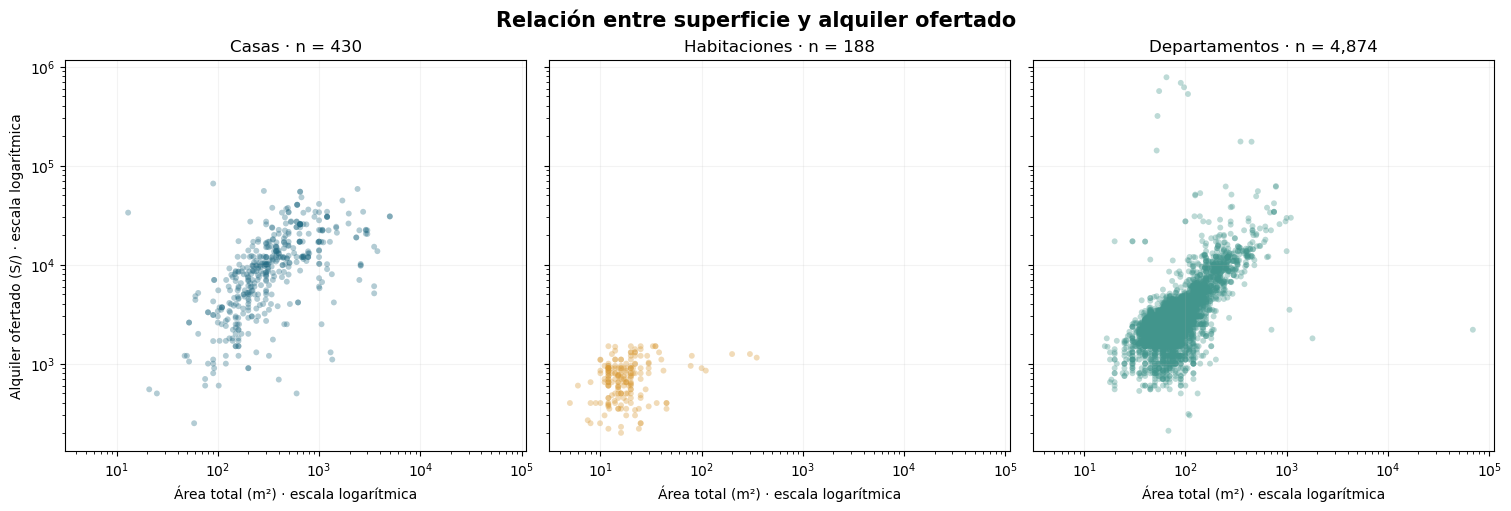

,tipo_inmueble,registros,graficados,no_graficados,cobertura_pct
0,casa,510,430,80,84.31
1,cuarto,832,188,644,22.60
2,departamento,5503,4874,629,88.57


In [148]:
# ============================================================
# 19. RELACIÓN ENTRE ÁREA Y PRECIO POR TIPO DE INMUEBLE
# ============================================================

def graficar_area_precio(datos):
    tipos = ["casa", "cuarto", "departamento"]
    nombres = ["Casas", "Habitaciones", "Departamentos"]
    colores = ["#256D85", "#D99A36", "#42958C"]

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 5),
        sharex=True, sharey=True,
        layout="constrained",
    )

    cobertura = []

    for ax, tipo, nombre, color in zip(
        axes, tipos, nombres, colores
    ):
        grupo = datos.loc[datos["tipo_inmueble"].eq(tipo)]

        # Solo valores positivos y finitos para los ejes logarítmicos
        validos = (
            grupo["area_total_m2"].gt(0)
            & grupo["precio_pen_pub"].gt(0)
            & np.isfinite(grupo["area_total_m2"])
            & np.isfinite(grupo["precio_pen_pub"])
        )
        muestra = grupo.loc[validos]

        ax.scatter(
            muestra["area_total_m2"],
            muestra["precio_pen_pub"],
            s=18, alpha=0.35, color=color,
            edgecolors="none",
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(f"{nombre} · n = {len(muestra):,}")
        ax.set_xlabel("Área total (m²) · escala logarítmica")
        ax.grid(alpha=0.15)

        cobertura.append({
            "tipo_inmueble": tipo,
            "registros": len(grupo),
            "graficados": len(muestra),
            "no_graficados": len(grupo) - len(muestra),
            "cobertura_pct": round(
                100 * len(muestra) / len(grupo), 2
            ) if len(grupo) else np.nan,
        })

    axes[0].set_ylabel("Alquiler ofertado (S/) · escala logarítmica")
    fig.suptitle(
        "Relación entre superficie y alquiler ofertado",
        fontsize=15, fontweight="bold",
    )

    return fig, pd.DataFrame(cobertura)


fig_area_precio, cobertura_area_precio = graficar_area_precio(df_eda)

plt.show()
display(cobertura_area_precio)

### Interpretación de la relación entre superficie y alquiler

En casas y departamentos se observa una tendencia positiva:
los inmuebles de mayor superficie tienden a presentar mayores
precios ofertados, aunque existe dispersión considerable.

En habitaciones, la relación visual es menos marcada. El gráfico
incluye únicamente 188 anuncios con área y precio disponibles,
por lo que no representa necesariamente a todas las habitaciones
de la base.

Ambos ejes utilizan escala logarítmica. Cada punto representa un
anuncio; los registros sin área o precio permanecen en la base,
pero no participan en esta visualización.

Todavía aparecen precios y superficies muy elevados, especialmente
en departamentos. Esta gráfica corresponde a una etapa intermedia:
falta aplicar la revisión documentada de precios del bloque 20
y resolver otras superficies señaladas. Los extremos no se
consideran errores únicamente por su magnitud.

In [149]:
# ============================================================
# 20. VENTAS CONFIRMADAS Y PRECIOS NO VERIFICADOS
# ============================================================

ventas_confirmadas = {
    "adondevivir-151370638":
        "La descripción indica precio de venta.",
    "adondevivir-150041850":
        "La descripción ofrece un departamento en venta en Breña.",
    "adondevivir-150077229":
        "La descripción ofrece un departamento en venta en Comas.",
    "urbania-151386771":
        "La descripción ofrece la venta de un departamento tríplex.",
    "urbania-60547860":
        "La descripción ofrece un departamento en venta en Comas.",
}

# Valores registrados antes del tratamiento.
precios_no_verificados = {
    "urbania-143732413": (
        685000.0,
        "El texto combina venta y alquiler; no permite confirmar "
        "que el precio registrado corresponda al alquiler mensual.",
    ),
    "urbania-148197597": (
        175000.0,
        "Oferta para temporada de verano; no se confirma "
        "el período al que corresponde el precio.",
    ),
    "urbania-65299945": (
        174300.0,
        "Oferta de alquiler temporal; no se dispone "
        "de un importe mensual verificable.",
    ),
    "facebook_marketplace-1147697194265072": (
        780000.0,
        "Precio señalado para revisión. No hay descripción "
        "disponible para verificar el importe y su periodicidad.",
    ),
    "facebook_marketplace-1077055534670453": (
        520000.0,
        "Precio señalado para revisión. No hay descripción "
        "disponible para verificar el importe y su periodicidad.",
    ),
}

# ------------------------------------------------------------
# 1. Preparar decisiones documentadas
# ------------------------------------------------------------
filas_decisiones = []

for identificador, evidencia in ventas_confirmadas.items():
    filas_decisiones.append({
        "id_anuncio": identificador,
        "accion": "excluir",
        "variable": None,
        "valor_esperado": None,
        "valor_nuevo": None,
        "evidencia": evidencia,
    })

for identificador, (precio, evidencia) in precios_no_verificados.items():
    filas_decisiones.append({
        "id_anuncio": identificador,
        "accion": "no_verificado",
        "variable": "precio_pen_pub",
        "valor_esperado": precio,
        "valor_nuevo": np.nan,
        "evidencia": evidencia,
    })

decisiones_precios = pd.DataFrame(filas_decisiones)

# ------------------------------------------------------------
# 2. Aplicar decisiones desde la base del bloque 18.1
# ------------------------------------------------------------
(
    df_eda_actualizado,
    excluidos_ventas,
    auditoria_precios,
    balance_precios,
) = aplicar_decisiones(
    datos=df_eda,
    decisiones=decisiones_precios,
)

# ------------------------------------------------------------
# 3. Acumular la auditoría
# ------------------------------------------------------------
auditoria_total_9 = pd.concat(
    [
        auditoria_total_8,
        auditoria_precios.assign(ronda=9),
    ],
    ignore_index=True,
)

# ------------------------------------------------------------
# 4. Verificar que los precios desconocidos no eliminen anuncios
# ------------------------------------------------------------
ids_precio_no_verificado = list(precios_no_verificados)

casos_conservados = df_eda_actualizado.loc[
    df_eda_actualizado["id_anuncio"].isin(
        ids_precio_no_verificado
    )
]

assert len(casos_conservados) == len(ids_precio_no_verificado)
assert casos_conservados["precio_pen_pub"].isna().all()

assert not df_eda_actualizado["id_anuncio"].isin(
    ventas_confirmadas
).any()

assert (
    len(df_eda_actualizado) + len(excluidos_ventas)
    == len(df_eda)
)

display(balance_precios)

display(
    auditoria_precios[
        [
            "id_anuncio",
            "accion",
            "variable",
            "valor_anterior",
            "valor_nuevo",
        ]
    ]
)

,concepto,cantidad
0,Registros de entrada,6845
1,Registros excluidos,5
2,Registros conservados,6840
3,Anuncios corregidos o reclasificados,0
4,Campos corregidos,0
5,Campos invalidados por error confirmado,0
6,Campos no verificados reemplazados por NaN,5


,id_anuncio,accion,variable,valor_anterior,valor_nuevo
0,adondevivir-151370638,excluir,pertenencia_base,Incluido,Excluido
1,adondevivir-150041850,excluir,pertenencia_base,Incluido,Excluido
2,adondevivir-150077229,excluir,pertenencia_base,Incluido,Excluido
3,urbania-151386771,excluir,pertenencia_base,Incluido,Excluido
4,urbania-60547860,excluir,pertenencia_base,Incluido,Excluido
5,urbania-143732413,no_verificado,precio_pen_pub,"685,000.00",NaN
6,urbania-148197597,no_verificado,precio_pen_pub,"175,000.00",NaN
7,urbania-65299945,no_verificado,precio_pen_pub,"174,300.00",NaN
8,facebook_marketplace-1147697194265072,no_verificado,precio_pen_pub,"780,000.00",NaN
9,facebook_marketplace-1077055534670453,no_verificado,precio_pen_pub,"520,000.00",NaN


### Revisión de los precios más altos

La consulta de las descripciones originales permitió identificar
cinco anuncios de venta adicionales, que se excluyen del análisis
de alquileres.

Otros cinco anuncios se apartan temporalmente porque no se puede
confirmar que el precio corresponda a un alquiler mensual.
No se consideran errores confirmados.

La selección por precio elevado se utilizó para localizar casos.
Las decisiones se sustentan en la evidencia disponible, no en
un límite automático de precio.

### Actualización del análisis de área y precio

La base provisional conserva 6.840 registros después de excluir
cinco ventas confirmadas y apartar cinco anuncios cuyo precio
mensual no pudo verificarse.

Para el gráfico de área y precio se aparta adicionalmente un
anuncio con superficie registrada de 69.090 m², pendiente de
verificación. El registro permanece en la base provisional.

Los demás extremos se conservan. El gráfico representa únicamente
los anuncios con precio y superficie positivos y disponibles.

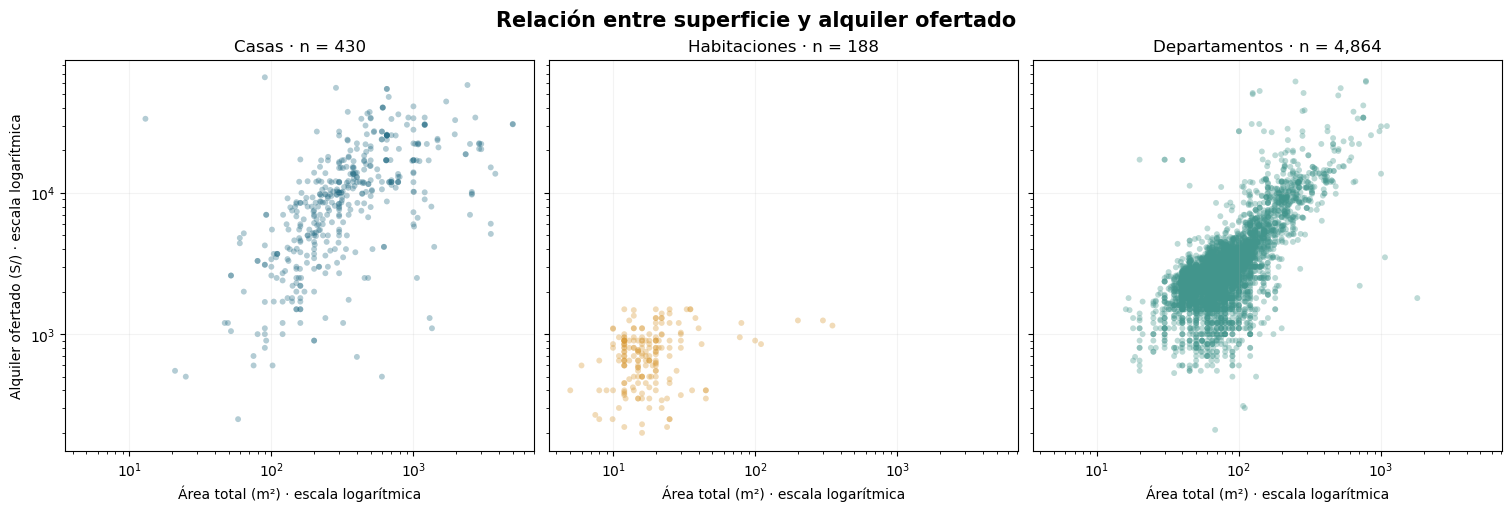

,tipo_inmueble,registros,graficados,no_graficados,cobertura_pct
0,casa,510,430,80,84.31
1,cuarto,832,188,644,22.60
2,departamento,5498,4864,634,88.47


,concepto,cantidad
0,Registros de entrada,6840
1,Registros excluidos,0
2,Registros conservados,6840
3,Anuncios corregidos o reclasificados,0
4,Campos corregidos,0
5,Campos invalidados por error confirmado,0
6,Campos no verificados reemplazados por NaN,1


In [150]:
# ============================================================
# 21. TRATAR EL ÁREA NO VERIFICADA Y ACTUALIZAR EL GRÁFICO
# ============================================================

decision_area_extrema = pd.DataFrame([
    {
        "id_anuncio": "babilonia-167543",
        "accion": "no_verificado",
        "variable": "area_total_m2",
        "valor_esperado": 69090.0,
        "valor_nuevo": np.nan,
        "evidencia": (
            "Área registrada de 69,090 m². La descripción del "
            "departamento no proporciona una superficie que permita "
            "confirmar o corregir este valor. No se presume "
            "una corrección decimal."
        ),
    }
])

(
    df_eda_area_revisada,
    excluidos_revision_area,
    auditoria_area_extrema,
    balance_area_extrema,
) = aplicar_decisiones(
    datos=df_eda_actualizado,
    decisiones=decision_area_extrema,
)

auditoria_total_10 = pd.concat(
    [
        auditoria_total_9,
        auditoria_area_extrema.assign(ronda=10),
    ],
    ignore_index=True,
)

# Verificar que se conserva el anuncio y se modifica solo su área.
assert len(df_eda_area_revisada) == len(df_eda_actualizado)
assert excluidos_revision_area.empty

caso = df_eda_area_revisada.loc[
    df_eda_area_revisada["id_anuncio"].eq("babilonia-167543")
]
assert len(caso) == 1
assert caso["area_total_m2"].isna().all()

# Actualizar la base utilizada por los siguientes bloques.
df_eda_actualizado = df_eda_area_revisada.copy()

# La función del bloque 19 utiliza pares con área y precio válidos.
fig_area_precio, cobertura_area_precio = graficar_area_precio(
    df_eda_actualizado
)

plt.show()
display(cobertura_area_precio)
display(balance_area_extrema)

### Relación entre superficie y alquiler después de la revisión

En departamentos se observa una asociación positiva entre superficie
y alquiler ofertado. Las casas también presentan una tendencia
positiva, aunque con mayor dispersión visual.

En habitaciones, la asociación es menos evidente. Los 188 anuncios
representados corresponden únicamente a aquellos con área y precio
disponibles; no necesariamente describen a las habitaciones sin
información de superficie.

La actualización excluye de la gráfica las ventas retiradas y los
campos que quedaron como NaN tras la revisión. Los anuncios con
campos desconocidos permanecen en la base, salvo las exclusiones
documentadas.

Persisten observaciones alejadas de la concentración principal.
Su posición no demuestra por sí sola un error, y la gráfica no
equivale a una validación completa de los datos.

Ambos ejes utilizan escala logarítmica. Las asociaciones observadas
no implican causalidad ni controlan por distrito u otras características.

## 22. Alquiler ofertado por distrito y tipo de inmueble

Se comparan las medianas y el rango entre los percentiles 25 y 75
de los alquileres, separando casas, habitaciones y departamentos.

El gráfico muestra hasta diez distritos con mayor número de anuncios
por tipo, considerando únicamente grupos con al menos diez registros.
Este mínimo es una regla de presentación, no una garantía estadística.

Las diferencias observadas también pueden reflejar distintas áreas,
calidades y fuentes de anuncios. No representan el efecto aislado
del distrito ni precios representativos de todo el mercado.

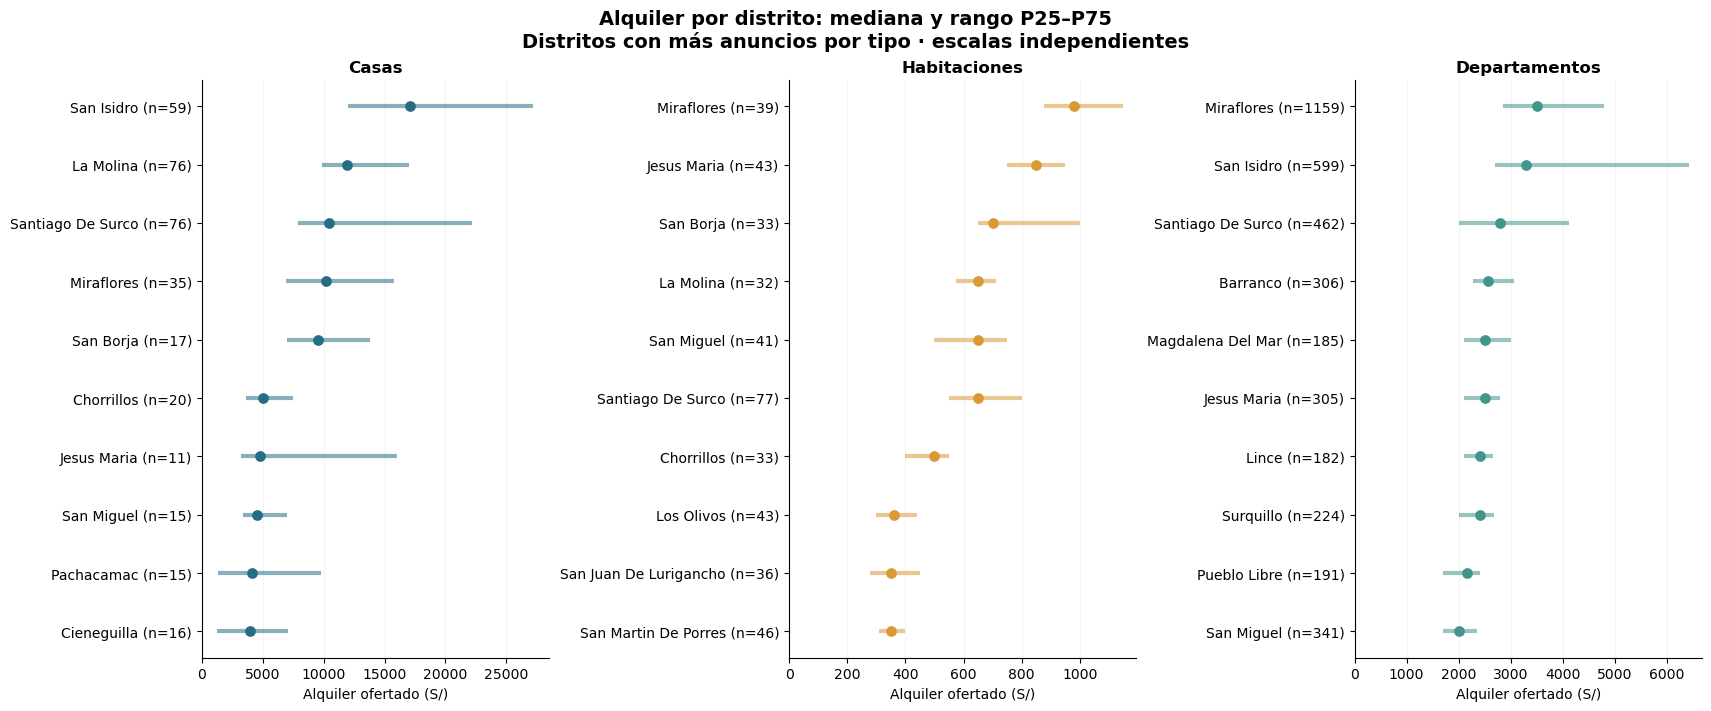

,tipo_inmueble,distrito,anuncios,mediana,p25,p75
0,casa,cieneguilla,16,"3,950.00","1,250.00","7,075.00"
1,casa,pachacamac,15,"4,150.00","1,325.00","9,809.00"
2,casa,san miguel,15,"4,500.00","3,400.00","6,970.00"
3,casa,jesus maria,11,"4,800.00","3,195.00","16,043.00"
4,casa,chorrillos,20,"5,000.00","3,600.00","7,490.00"
5,casa,san borja,17,"9,576.00","7,000.00","13,840.00"
6,casa,miraflores,35,"10,200.00","6,875.00","15,762.00"
7,casa,santiago de surco,76,"10,428.00","7,881.75","22,217.00"
8,casa,la molina,76,"11,900.00","9,896.50","17,000.00"
9,casa,san isidro,59,"17,090.00","11,995.00","27,200.00"


In [151]:
# ============================================================
# 22. ALQUILER POR DISTRITO Y TIPO DE INMUEBLE
# ============================================================

def analizar_precio_por_distrito(
    datos: pd.DataFrame,
    minimo: int = 10,
    top: int = 10,
):
    """Resume precios y grafica los distritos con mayor cobertura."""

    resumen = (
        datos.groupby(
            ["tipo_inmueble", "distrito"],
            observed=True,
            dropna=False,
        )
        .agg(
            anuncios=("precio_pen_pub", "count"),
            mediana=("precio_pen_pub", "median"),
            p25=("precio_pen_pub", lambda s: s.quantile(0.25)),
            p75=("precio_pen_pub", lambda s: s.quantile(0.75)),
        )
        .reset_index()
    )

    tipos = ["casa", "cuarto", "departamento"]
    nombres = ["Casas", "Habitaciones", "Departamentos"]
    colores = ["#256D85", "#D99A36", "#42958C"]

    fig, axes = plt.subplots(
        1, 3, figsize=(17, 7),
        layout="constrained",
    )

    seleccionados = []

    for ax, tipo, nombre, color in zip(
        axes, tipos, nombres, colores
    ):
        tabla = (
            resumen.loc[
                resumen["tipo_inmueble"].eq(tipo)
                & resumen["anuncios"].ge(minimo)
            ]
            .sort_values(
                ["anuncios", "distrito"],
                ascending=[False, True],
            )
            .head(top)
            .sort_values("mediana")
        )

        seleccionados.append(tabla)

        if tabla.empty:
            ax.set_title(nombre)
            ax.text(
                0.5, 0.5,
                "Sin grupos con el mínimo requerido",
                ha="center", va="center",
                transform=ax.transAxes,
            )
            ax.set_axis_off()
            continue

        posiciones = np.arange(len(tabla))

        ax.hlines(
            posiciones,
            tabla["p25"],
            tabla["p75"],
            color=color,
            linewidth=3,
            alpha=0.55,
        )

        ax.scatter(
            tabla["mediana"],
            posiciones,
            color=color,
            s=45,
            zorder=3,
        )

        etiquetas = [
            f"{str(distrito).title()} (n={cantidad})"
            for distrito, cantidad in zip(
                tabla["distrito"], tabla["anuncios"]
            )
        ]

        ax.set_yticks(posiciones)
        ax.set_yticklabels(etiquetas)
        ax.set_xlabel("Alquiler ofertado (S/)")
        ax.set_title(nombre, fontweight="bold")
        ax.set_xlim(left=0)
        ax.grid(axis="x", alpha=0.15)
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(
        "Alquiler por distrito: mediana y rango P25–P75\n"
        "Distritos con más anuncios por tipo · escalas independientes",
        fontsize=14,
        fontweight="bold",
    )

    return resumen, pd.concat(seleccionados, ignore_index=True), fig


resumen_distritos, distritos_graficados, fig_distritos = (
    analizar_precio_por_distrito(df_eda_actualizado)
)

plt.show()

display(
    distritos_graficados[
        ["tipo_inmueble", "distrito", "anuncios", "mediana", "p25", "p75"]
    ].round(2)
)


### Interpretación del alquiler ofertado por distrito

El punto representa la mediana y la línea el rango P25–P75,
que contiene el 50 % central de los precios. El número de anuncios
(n) corresponde únicamente a registros con precio disponible.

Entre los distritos seleccionados:

- **Casas:** San Isidro presenta la mayor mediana (S/17,090),
  seguido de La Molina (S/11,900) y Santiago de Surco (S/10,428).
  Los intervalos amplios muestran heterogeneidad de precios.
  Algunos grupos tienen pocos anuncios, como Jesús María (n=11).

- **Habitaciones:** las medianas más altas corresponden a
  Miraflores (S/980) y Jesús María (S/850). San Martín de Porres
  y San Juan de Lurigancho presentan medianas de S/350.

- **Departamentos:** Miraflores registra una mediana de S/3,500
  y San Isidro de S/3,300, frente a S/2,000 en San Miguel.
  San Isidro presenta un rango intercuartílico amplio:
  de S/2,702 a S/6,430.

Estas diferencias respaldan considerar el distrito en el análisis.
Sin embargo, no representan un efecto exclusivo de la ubicación:
también pueden reflejar diferencias de superficie, equipamiento
y composición de los anuncios.

Se muestran los diez distritos con mayor cantidad de precios
disponibles por tipo, no necesariamente los más caros o baratos
de Lima Metropolitana. Los paneles utilizan escalas independientes.

Los resultados describen precios ofertados en la muestra recopilada,
no alquileres efectivamente pactados ni estimaciones representativas
de todo el mercado. Deberán actualizarse después de las revisiones
posteriores de duplicidad y ubicación.

## 23. Alquiler según dormitorios y baños

Se analiza cómo varía el alquiler ofertado según el número de
dormitorios y baños, separando casas, habitaciones y departamentos.

Los gráficos muestran categorías con al menos diez precios disponibles.
El punto representa la mediana y la línea el rango P25–P75;
no es un intervalo de confianza.

Las diferencias son descriptivas: también pueden reflejar variaciones
de área, ubicación y calidad. Los baños fraccionarios se conservan.

En habitaciones, el número de baños puede describir espacios
compartidos o características de la vivienda completa. Su interpretación
requiere cautela. Si solo hay una categoría de dormitorios,
no es posible evaluar una relación dentro de ese segmento.

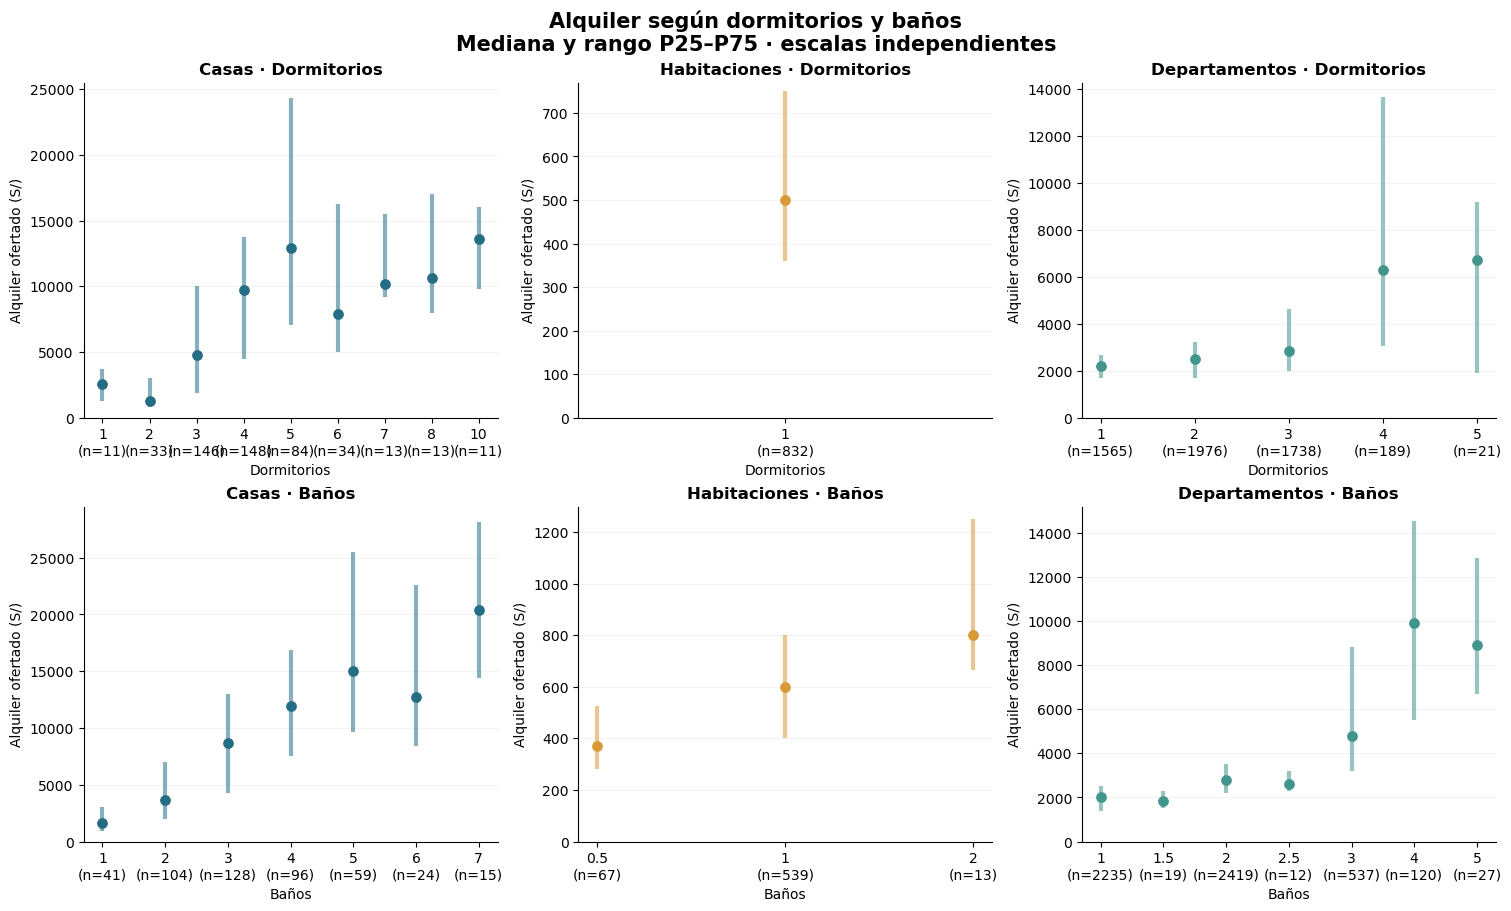

,tipo_inmueble,variable,cantidad,anuncios,mediana,p25,p75,graficado
0,casa,dormitorios,1.00,11,"2,600.00","1,275.00","3,700.00",True
1,casa,dormitorios,2.00,33,"1,300.00",800.00,"3,000.00",True
2,casa,dormitorios,3.00,146,"4,767.50","1,850.00","10,015.50",True
3,casa,dormitorios,4.00,148,"9,735.00","4,450.00","13,754.00",True
4,casa,dormitorios,5.00,84,"12,952.50","7,070.00","24,319.50",True
5,casa,dormitorios,6.00,34,"7,913.50","5,000.00","16,227.00",True
6,casa,dormitorios,7.00,13,"10,170.00","9,180.00","15,525.00",True
7,casa,dormitorios,8.00,13,"10,602.00","7,940.00","17,000.00",True
8,casa,dormitorios,9.00,9,"11,000.00","6,000.00","26,025.00",False
9,casa,dormitorios,10.00,11,"13,600.00","9,818.00","16,000.00",True


In [152]:
# ============================================================
# 23. ALQUILER SEGÚN DORMITORIOS Y BAÑOS
# ============================================================

def analizar_ambientes(datos: pd.DataFrame, minimo: int = 10):
    """Compara precios por cantidad de ambientes y tipo de inmueble."""

    tipos = ["casa", "cuarto", "departamento"]
    nombres = ["Casas", "Habitaciones", "Departamentos"]
    colores = ["#256D85", "#D99A36", "#42958C"]

    variables = {
        "dormitorios": "Dormitorios",
        "banos": "Baños",
    }

    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 9),
        layout="constrained",
    )

    tablas = []

    for fila, (variable, etiqueta) in enumerate(variables.items()):
        resumen = (
            datos.groupby(
                ["tipo_inmueble", variable],
                observed=True,
                dropna=False,
            )
            .agg(
                anuncios=("precio_pen_pub", "count"),
                mediana=("precio_pen_pub", "median"),
                p25=("precio_pen_pub", lambda s: s.quantile(0.25)),
                p75=("precio_pen_pub", lambda s: s.quantile(0.75)),
            )
            .reset_index()
            .rename(columns={variable: "cantidad"})
        )

        resumen["variable"] = variable
        resumen["graficado"] = (
            resumen["cantidad"].notna()
            & resumen["anuncios"].ge(minimo)
        )

        tablas.append(resumen)

        for columna, (tipo, nombre, color) in enumerate(
            zip(tipos, nombres, colores)
        ):
            ax = axes[fila, columna]

            tabla = resumen.loc[
                resumen["tipo_inmueble"].eq(tipo)
                & resumen["graficado"]
            ].sort_values("cantidad")

            ax.set_title(f"{nombre} · {etiqueta}", fontweight="bold")

            if tabla.empty:
                ax.text(
                    0.5, 0.5,
                    "Sin categorías con el mínimo requerido",
                    ha="center", va="center",
                    transform=ax.transAxes,
                )
                ax.set_axis_off()
                continue

            posiciones = np.arange(len(tabla))

            ax.vlines(
                posiciones,
                tabla["p25"],
                tabla["p75"],
                color=color,
                linewidth=3,
                alpha=0.55,
            )

            ax.scatter(
                posiciones,
                tabla["mediana"],
                color=color,
                s=45,
                zorder=3,
            )

            ax.set_xticks(posiciones)
            ax.set_xticklabels([
                f"{cantidad:g}\n(n={n})"
                for cantidad, n in zip(
                    tabla["cantidad"], tabla["anuncios"]
                )
            ])

            ax.set_xlabel(etiqueta)
            ax.set_ylabel("Alquiler ofertado (S/)")
            ax.set_ylim(bottom=0)
            ax.grid(axis="y", alpha=0.15)
            ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(
        "Alquiler según dormitorios y baños\n"
        "Mediana y rango P25–P75 · escalas independientes",
        fontsize=15,
        fontweight="bold",
    )

    return pd.concat(tablas, ignore_index=True), fig


resumen_ambientes, fig_ambientes = analizar_ambientes(
    df_eda_actualizado
)

plt.show()

display(
    resumen_ambientes[
        [
            "tipo_inmueble", "variable", "cantidad",
            "anuncios", "mediana", "p25", "p75", "graficado",
        ]
    ].round(2)
)

### Interpretación del alquiler según dormitorios y baños

Los puntos representan medianas y las líneas el rango P25–P75.
Solo se grafican categorías con al menos diez precios disponibles.
Los paneles utilizan escalas independientes.

**Casas.** Entre tres y cinco dormitorios se observa un aumento
de la mediana del alquiler. Sin embargo, la relación no es
uniformemente creciente: las casas con seis dormitorios presentan
una mediana inferior a las de cinco. La amplitud de los intervalos
muestra diferencias importantes dentro de cada categoría.

**Departamentos.** Las medianas aumentan entre uno y cinco
dormitorios, con un incremento marcado entre tres y cuatro.
También se observa una asociación generalmente positiva entre
cantidad de baños y alquiler, aunque existen excepciones.

**Habitaciones.** Los 832 anuncios con precio disponible tienen
un dormitorio, por lo que no es posible comparar precios entre
distintas cantidades de dormitorios dentro de este grupo.
Las medianas difieren según los baños registrados; sin embargo,
la categoría de dos baños tiene solo 13 anuncios y puede referirse
a baños disponibles en la vivienda compartida.

Los valores de 0.5 baños conservan la codificación de la fuente.
No deben interpretarse automáticamente como baño compartido,
pues esta condición se registra en otra variable.

Estas comparaciones no aíslan el efecto de dormitorios o baños:
también pueden intervenir la superficie, el distrito y otras
características. Las diferencias observadas no demuestran causalidad.


## 24. Revisión de atributos obtenidos mediante NLP

Se verifica la codificación de las variables que comienzan con attr_:
valores cero, uno, nulos y códigos distintos de los esperados.

Hasta confirmar la definición del proceso NLP, cero se interpreta
como atributo no detectado, no necesariamente como ausencia real.

También se identifican atributos sin variación en los valores
observados. La revisión no modifica la base.

In [153]:
# ============================================================
# 24. REVISIÓN DE ATRIBUTOS NLP
# ============================================================

def revisar_atributos_nlp(datos: pd.DataFrame) -> pd.DataFrame:
    """Resume la codificación y variación de los atributos NLP."""

    atributos = [
        columna for columna in datos.columns
        if columna.startswith("attr_")
    ]

    filas = []

    for atributo in atributos:
        serie = datos[atributo]

        ceros = int(serie.eq(0).sum())
        unos = int(serie.eq(1).sum())
        nulos = int(serie.isna().sum())

        invalidos = serie.notna() & ~serie.isin([0, 1])
        validos = ceros + unos

        filas.append({
            "variable": atributo,
            "ceros": ceros,
            "unos": unos,
            "nulos": nulos,
            "codigos_no_validos": int(invalidos.sum()),
            "detectado_pct": (
                round(100 * unos / validos, 2)
                if validos else np.nan
            ),
            "valores_distintos": serie.nunique(dropna=True),
        })

    return pd.DataFrame(
        filas,
        columns=[
            "variable", "ceros", "unos", "nulos",
            "codigos_no_validos", "detectado_pct",
            "valores_distintos",
        ],
    )


revision_nlp = revisar_atributos_nlp(df_eda_actualizado)

with pd.option_context("display.max_rows", None):
    display(revision_nlp)

print(
    "Atributos con códigos no válidos:",
    int(revision_nlp["codigos_no_validos"].gt(0).sum()),
)

print(
    "Atributos con un único valor observado:",
    int(revision_nlp["valores_distintos"].eq(1).sum()),
)

,variable,ceros,unos,nulos,codigos_no_validos,detectado_pct,valores_distintos
0,attr_amoblado,4749,2091,0,0,30.57,2
1,attr_piscina,5198,1642,0,0,24.01,2
2,attr_jardin,5417,1423,0,0,20.80,2
3,attr_terraza,3819,3021,0,0,44.17,2
4,attr_seguridad,2960,3880,0,0,56.73,2
5,attr_ascensor,4069,2771,0,0,40.51,2
6,attr_mascotas,4768,2072,0,0,30.29,2
7,attr_vista_mar,6314,526,0,0,7.69,2
8,attr_lavanderia,2076,4764,0,0,69.65,2
9,attr_cuarto_servicio,5695,1145,0,0,16.74,2


Atributos con códigos no válidos: 0
Atributos con un único valor observado: 0


### Resultado de la revisión de atributos NLP

Los 26 atributos presentan códigos binarios válidos en los 6,840
anuncios: no se encontraron nulos ni valores distintos de 0 y 1.
Todos los atributos presentan variación.

Los atributos con mayor frecuencia de detección son lavandería
(69.65 %), seguridad (56.73 %) y cercanía a comercios (50.03 %).
Servicios básicos presenta la menor frecuencia (1.64 %).

Estos porcentajes describen detecciones del proceso NLP, no la
presencia real verificada de las características. Un cero indica
que el atributo no fue detectado; no demuestra su ausencia.

La revisión confirma consistencia de codificación, pero no mide
la precisión de la extracción. Una frecuencia baja, por sí sola,
no justifica eliminar una variable.

In [154]:
# ============================================================
# 25. POSIBLES DUPLICADOS ENTRE FUENTES
# ============================================================

claves_duplicado = [
    "tipo_inmueble",
    "distrito",
    "precio_pen_pub",
    "area_total_m2",
    "dormitorios",
    "banos",
    "latitud",
    "longitud",
]

# Exigir datos completos en las claves evita agrupar por nulos
comparables = df_eda_actualizado.dropna(
    subset=claves_duplicado
).copy()

repetidos = comparables.loc[
    comparables.duplicated(
        subset=claves_duplicado,
        keep=False,
    )
].copy()

if not repetidos.empty:
    repetidos["grupo_revision"] = (
        repetidos.groupby(claves_duplicado, sort=False).ngroup() + 1
    )

    # Conservar únicamente grupos presentes en más de una fuente
    fuentes_por_grupo = (
        repetidos.groupby("grupo_revision")["portal"]
        .transform("nunique")
    )

    posibles_duplicados = repetidos.loc[
        fuentes_por_grupo.gt(1)
    ].sort_values(["grupo_revision", "portal"])

else:
    posibles_duplicados = repetidos.assign(
        grupo_revision=pd.Series(dtype="int64")
    )

print(f"Registros comparables: {len(comparables):,}")
print(f"Anuncios candidatos: {len(posibles_duplicados):,}")
print(
    "Grupos entre fuentes:",
    posibles_duplicados["grupo_revision"].nunique(),
)

display(
    posibles_duplicados[
        ["grupo_revision", "id_anuncio", "portal", *claves_duplicado]
    ]
)

Registros comparables: 5,422
Anuncios candidatos: 16
Grupos entre fuentes: 8


,grupo_revision,id_anuncio,portal,tipo_inmueble,distrito,precio_pen_pub,area_total_m2,dormitorios,banos,latitud,longitud
685,5,adondevivir-151370836,adondevivir,departamento,jesus maria,"2,250.00",65.00,2.00,1.00,-12.08,-77.06
4526,5,babilonia-174147,babilonia,departamento,jesus maria,"2,250.00",65.00,2.00,1.00,-12.08,-77.06
827,7,adondevivir-151524029,adondevivir,departamento,san isidro,"3,000.00",60.00,2.00,2.00,-12.09,-77.05
4195,7,babilonia-176758,babilonia,departamento,san isidro,"3,000.00",60.00,2.00,2.00,-12.09,-77.05
1279,8,adondevivir-151252748,adondevivir,departamento,miraflores,"4,140.00",116.00,3.00,2.00,-12.12,-77.03
3722,8,urbania-151252558,urbania,departamento,miraflores,"4,140.00",116.00,3.00,2.00,-12.12,-77.03
1677,10,adondevivir-151039101,adondevivir,departamento,pueblo libre,"2,000.00",45.00,1.00,1.00,-12.08,-77.07
2785,10,urbania-151039081,urbania,departamento,pueblo libre,"2,000.00",45.00,1.00,1.00,-12.08,-77.07
1753,11,adondevivir-151257517,adondevivir,departamento,pueblo libre,"4,500.00",115.00,3.00,3.00,-12.08,-77.06
4364,11,babilonia-167869,babilonia,departamento,pueblo libre,"4,500.00",115.00,3.00,3.00,-12.08,-77.06


In [156]:
# ============================================================
# 26. TRATAMIENTO DOCUMENTADO DE PUBLICACIONES REPETIDAS
# ============================================================

decisiones_duplicados = pd.DataFrame([
    ("babilonia-174147", "adondevivir-151370836",
     "Coinciden características detalladas, piso y condiciones."),
    ("urbania-151252558", "adondevivir-151252748",
     "Mismo texto, chalet, ubicación y anunciante."),
    ("urbania-151039081", "adondevivir-151039101",
     "Mismo anuncio con alternativas amoblada y sin amoblar."),
    ("babilonia-177044", "adondevivir-151524181",
     "Coinciden ubicación y características específicas de la casa."),
], columns=["id_retirado", "id_conservado", "evidencia"])

ids_necesarios = set(
    decisiones_duplicados["id_retirado"]
) | set(decisiones_duplicados["id_conservado"])

if not ids_necesarios.issubset(set(df_eda_actualizado["id_anuncio"])):
    raise ValueError("Faltan anuncios de los pares revisados.")

# Conservar las filas retiradas y su relación con la publicación elegida
duplicados_retirados = df_eda_actualizado.merge(
    decisiones_duplicados,
    left_on="id_anuncio",
    right_on="id_retirado",
    how="inner",
    validate="one_to_one",
)

df_eda_depurado = df_eda_actualizado.loc[
    ~df_eda_actualizado["id_anuncio"].isin(
        decisiones_duplicados["id_retirado"]
    )
].copy()

# El texto describe una casa/chalet en quinta de dos niveles
es_chalet = df_eda_depurado["id_anuncio"].eq("adondevivir-151252748")

auditoria_chalet = pd.DataFrame([{
    "id_anuncio": "adondevivir-151252748",
    "variable": "tipo_inmueble",
    "valor_anterior": df_eda_depurado.loc[
        es_chalet, "tipo_inmueble"
    ].iloc[0],
    "valor_nuevo": "casa",
    "evidencia": "Título y descripción: casa/chalet en quinta de dos niveles.",
}])

df_eda_depurado.loc[es_chalet, "tipo_inmueble"] = "casa"

print(f"Publicaciones retiradas: {len(duplicados_retirados)}")
print(f"Registros conservados: {len(df_eda_depurado):,}")

display(decisiones_duplicados)
display(auditoria_chalet)

Publicaciones retiradas: 4
Registros conservados: 6,836


,id_retirado,id_conservado,evidencia
0,babilonia-174147,adondevivir-151370836,"Coinciden características detalladas, piso y condiciones."
1,urbania-151252558,adondevivir-151252748,"Mismo texto, chalet, ubicación y anunciante."
2,urbania-151039081,adondevivir-151039101,Mismo anuncio con alternativas amoblada y sin amoblar.
3,babilonia-177044,adondevivir-151524181,Coinciden ubicación y características específicas de la ...


,id_anuncio,variable,valor_anterior,valor_nuevo,evidencia
0,adondevivir-151252748,tipo_inmueble,departamento,casa,Título y descripción: casa/chalet en quinta de dos niveles.


### Resultado de la revisión de duplicados entre fuentes

Se retiraron cuatro publicaciones repetidas respaldadas por
coincidencias de contenido y características específicas.
Se conservó la captura más reciente de cada par.

Un chalet publicado como departamento se reclasificó como casa.

La coincidencia de precio, superficie y coordenadas no basta
para confirmar duplicidad: dos anuncios del mismo edificio
describen unidades situadas en pisos diferentes y se conservaron.

Otros tres pares permanecen pendientes por evidencia insuficiente
o contradictoria. El control realizado no descarta duplicados
con diferencias en sus características registradas.

In [158]:
# ============================================================
# 27. REGISTRO DE POSIBLES DUPLICADOS NO CONFIRMADOS
# ============================================================

pares_pendientes = pd.DataFrame([
    ("adondevivir-151257517", "DUP_11",
     "Misma dirección y piso; superficies descritas de 115 y 107 m²."),
    ("babilonia-167869", "DUP_11",
     "Misma dirección y piso; superficies descritas de 115 y 107 m²."),
    ("adondevivir-151471085", "DUP_12",
     "Falta confirmar si ambos anuncios corresponden al mismo minidúplex."),
    ("babilonia-176107", "DUP_12",
     "Falta confirmar si ambos anuncios corresponden al mismo minidúplex."),
    ("facebook_marketplace-2289832111587505", "DUP_26",
     "Sin descripción disponible; requiere comparar las publicaciones."),
    ("tiktok-7706682828678827265", "DUP_26",
     "Sin descripción disponible; requiere comparar las publicaciones."),
], columns=[
    "id_anuncio",
    "grupo_posible_duplicado",
    "motivo_revision_duplicado",
])

faltan = set(pares_pendientes["id_anuncio"]) - set(
    df_eda_depurado["id_anuncio"]
)

if faltan:
    raise ValueError(f"No se encontraron estos anuncios: {sorted(faltan)}")

# Crear una nueva versión sin modificar el respaldo anterior
df_eda_control = df_eda_depurado.merge(
    pares_pendientes[
        ["id_anuncio", "grupo_posible_duplicado"]
    ],
    on="id_anuncio",
    how="left",
    validate="one_to_one",
)

df_eda_control["posible_duplicado_no_confirmado"] = (
    df_eda_control["grupo_posible_duplicado"].notna()
)

print(f"Registros conservados: {len(df_eda_control):,}")
print(
    "Registros con duplicidad pendiente:",
    df_eda_control["posible_duplicado_no_confirmado"].sum(),
)

display(pares_pendientes)

Registros conservados: 6,836
Registros con duplicidad pendiente: 6


,id_anuncio,grupo_posible_duplicado,motivo_revision_duplicado
0,adondevivir-151257517,DUP_11,Misma dirección y piso; superficies descritas de 115 y 1...
1,babilonia-167869,DUP_11,Misma dirección y piso; superficies descritas de 115 y 1...
2,adondevivir-151471085,DUP_12,Falta confirmar si ambos anuncios corresponden al mismo ...
3,babilonia-176107,DUP_12,Falta confirmar si ambos anuncios corresponden al mismo ...
4,facebook_marketplace-2289832111587505,DUP_26,Sin descripción disponible; requiere comparar las public...
5,tiktok-7706682828678827265,DUP_26,Sin descripción disponible; requiere comparar las public...


### Tratamiento de duplicados no confirmados

Se conservan seis anuncios agrupados en tres pares cuya duplicidad
no pudo confirmarse con la evidencia disponible.

Los pares quedan identificados mediante un código de seguimiento.
No se elimina ninguno por coincidencia de características únicamente.

Esta revisión queda documentada como una limitación pendiente
de contraste con las publicaciones originales.

In [159]:
from pathlib import Path

carpeta_salida = Path(CARPETA_PROYECTO) / "resultados"
carpeta_salida.mkdir(parents=True, exist_ok=True)

df_eda_control.to_csv(
    carpeta_salida / "base_eda_avance.csv",
    index=False,
    encoding="utf-8-sig",
)

pares_pendientes.to_csv(
    carpeta_salida / "duplicados_pendientes.csv",
    index=False,
    encoding="utf-8-sig",
)

print(f"Archivos guardados en: {carpeta_salida.resolve()}")

Archivos guardados en: C:\Users\HP\Downloads\PI_EDA_Final\resultados


## 28. Revisión de coordenadas

Se comprueba la disponibilidad y validez numérica de latitud
y longitud. Se representa la ubicación de los anuncios para
identificar puntos alejados del conjunto principal.

Una coordenada dentro de los rangos válidos del planeta puede
estar mal asignada. La pertenencia exacta a Lima Metropolitana
y la correspondencia con el distrito requieren límites geográficos
oficiales o evidencia del anuncio.

No se corrigen coordenadas ni se eliminan registros en este bloque.

,concepto,registros
0,Registros totales,6836
1,Con ambas coordenadas originales,6830
2,Sin alguna coordenada original,6
3,Con valores no convertibles a número,0
4,Pares completos fuera de rangos válidos,0
5,Pares numéricos dentro de rangos válidos,6830


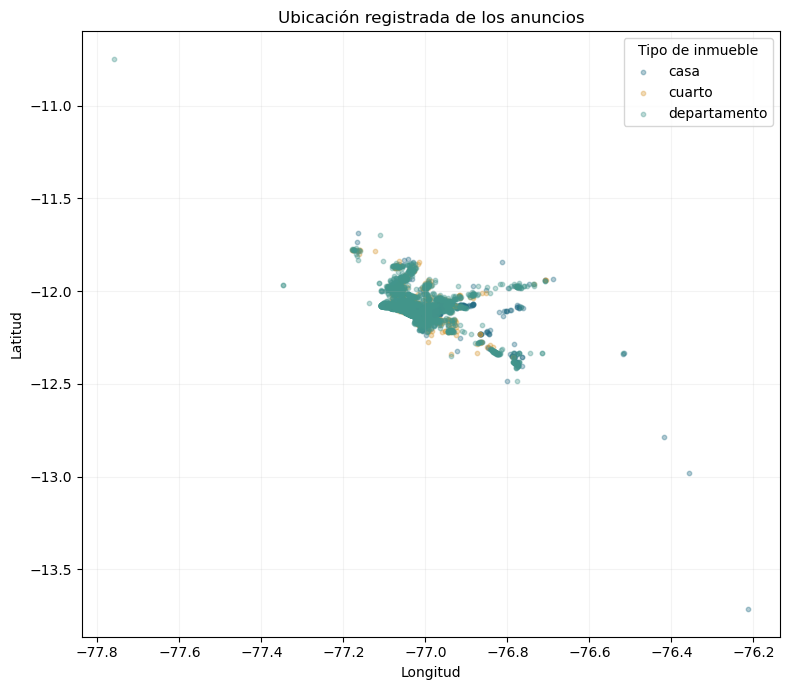

In [160]:
# ============================================================
# 28. DIAGNÓSTICO Y VISUALIZACIÓN DE COORDENADAS
# ============================================================

def revisar_coordenadas(datos: pd.DataFrame):
    """Revisa las coordenadas sin modificar la base."""

    lat = pd.to_numeric(datos["latitud"], errors="coerce")
    lon = pd.to_numeric(datos["longitud"], errors="coerce")

    completas = lat.notna() & lon.notna()
    validas = (
        completas
        & lat.between(-90, 90)
        & lon.between(-180, 180)
    )

    resumen = pd.DataFrame({
        "concepto": [
            "Registros totales",
            "Con ambas coordenadas originales",
            "Sin alguna coordenada original",
            "Con valores no convertibles a número",
            "Pares completos fuera de rangos válidos",
            "Pares numéricos dentro de rangos válidos",
        ],
        "registros": [
            len(datos),
            int(datos[["latitud", "longitud"]].notna().all(axis=1).sum()),
            int(datos[["latitud", "longitud"]].isna().any(axis=1).sum()),
            int((
                (datos["latitud"].notna() & lat.isna())
                | (datos["longitud"].notna() & lon.isna())
            ).sum()),
            int((completas & ~validas).sum()),
            int(validas.sum()),
        ],
    })

    fig, ax = plt.subplots(figsize=(8, 7))

    for tipo, color in [
        ("casa", "#256D85"),
        ("cuarto", "#D99A36"),
        ("departamento", "#42958C"),
    ]:
        mascara = validas & datos["tipo_inmueble"].eq(tipo)

        ax.scatter(
            lon.loc[mascara],
            lat.loc[mascara],
            s=10,
            alpha=0.35,
            color=color,
            label=tipo,
        )

    ax.set(
        xlabel="Longitud",
        ylabel="Latitud",
        title="Ubicación registrada de los anuncios",
    )
    ax.grid(alpha=0.15)
    ax.legend(title="Tipo de inmueble")
    fig.tight_layout()

    return resumen, fig


resumen_coordenadas, fig_coordenadas = revisar_coordenadas(
    df_eda_control
)

display(resumen_coordenadas)
plt.show()

### Interpretación de las coordenadas

La mayoría de los anuncios forma una concentración principal,
mientras que algunos puntos aparecen considerablemente alejados.

Estos puntos son señales de posible inconsistencia geográfica.
Estar dentro de los rangos válidos de latitud y longitud no garantiza
que la ubicación corresponda al inmueble ni al distrito registrado.

El gráfico no incluye límites administrativos, por lo que no permite
confirmar la pertenencia exacta a Lima Metropolitana.
No se eliminan registros ni se sustituyen coordenadas automáticamente.

In [161]:
# ============================================================
# 29. IDENTIFICAR COORDENADAS ALEJADAS PARA REVISIÓN
# ============================================================

def identificar_coordenadas_alejadas(datos, n=10):
    """Ordena puntos por distancia al centro mediano de la muestra."""

    lat = pd.to_numeric(datos["latitud"], errors="coerce")
    lon = pd.to_numeric(datos["longitud"], errors="coerce")

    validas = (
        lat.between(-90, 90)
        & lon.between(-180, 180)
    )

    revision = datos.loc[
        validas,
        ["id_anuncio", "portal", "tipo_inmueble", "distrito"],
    ].copy()

    if revision.empty:
        raise ValueError("No hay pares de coordenadas válidos.")

    revision["latitud"] = lat.loc[validas]
    revision["longitud"] = lon.loc[validas]

    # Punto de referencia descriptivo, no centro oficial de Lima
    lat_centro = revision["latitud"].median()
    lon_centro = revision["longitud"].median()

    lat_rad = np.radians(revision["latitud"])
    lon_rad = np.radians(revision["longitud"])
    lat0 = np.radians(lat_centro)
    lon0 = np.radians(lon_centro)

    # Distancia geográfica aproximada mediante Haversine
    a = (
        np.sin((lat_rad - lat0) / 2) ** 2
        + np.cos(lat0) * np.cos(lat_rad)
        * np.sin((lon_rad - lon0) / 2) ** 2
    )

    revision["distancia_centro_muestral_km"] = (
        6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    )

    return revision.nlargest(
        n, "distancia_centro_muestral_km"
    )


revision_geografica = identificar_coordenadas_alejadas(
    df_eda_control
)

with pd.option_context("display.max_columns", None):
    display(revision_geografica.round({
        "latitud": 6,
        "longitud": 6,
        "distancia_centro_muestral_km": 2,
    }))

,id_anuncio,portal,tipo_inmueble,distrito,latitud,longitud,distancia_centro_muestral_km
6585,facebook_marketplace-1713456763476558,facebook_marketplace,casa,la victoria,-13.72,-76.21,200.65
4406,babilonia-177042,babilonia,departamento,barranco,-10.75,-77.76,169.80
6717,facebook_marketplace-928223053055015,facebook_marketplace,casa,miraflores,-12.98,-76.36,122.44
6714,facebook_marketplace-2745062642557310,facebook_marketplace,casa,miraflores,-12.78,-76.42,101.32
6716,facebook_marketplace-1053040894042081,facebook_marketplace,casa,punta hermosa,-12.34,-76.52,61.71
5652,facebook_marketplace-1324518349825648,facebook_marketplace,casa,punta hermosa,-12.33,-76.52,61.63
6548,facebook_marketplace-907027365731170,facebook_marketplace,departamento,punta hermosa,-12.34,-76.52,61.59
6167,tiktok-7458847656530857222,tiktok,departamento,pucusana,-12.48,-76.78,51.07
3847,urbania-146768829,urbania,casa,pucusana,-12.48,-76.80,49.74
6131,tiktok-7690272281364483334,tiktok,casa,santa rosa,-11.69,-77.16,47.67


In [162]:
# ============================================================
# 30. TRATAMIENTO DE UBICACIÓN Y PRECIO NO VERIFICADOS
# ============================================================

filas_geo = []

# ------------------------------------------------------------
# 1. Exclusiones respaldadas por la ubicación original
# ------------------------------------------------------------
fuera_ambito = {
    "facebook_marketplace-1713456763476558":
        "Ubicación original: San Andrés, Pisco.",
    "facebook_marketplace-928223053055015":
        "Ubicación original: La Planicie de San Benito, Imperial, Cañete.",
    "facebook_marketplace-2745062642557310":
        "Ubicación original: Chocaya–Asia, km 93.5.",
}

for identificador, evidencia in fuera_ambito.items():
    filas_geo.append({
        "id_anuncio": identificador,
        "accion": "excluir",
        "variable": None,
        "valor_esperado": None,
        "valor_nuevo": None,
        "evidencia": evidencia,
    })

# ------------------------------------------------------------
# 2. Coordenadas: errores confirmados y valores no verificados
# Se utilizan los valores completos, no los redondeados de la tabla.
# ------------------------------------------------------------
coordenadas_revisadas = [
    (
        "babilonia-177042",
        -10.7476204, -77.7601907,
        "invalidar_valor",
        "Coordenadas incompatibles con la dirección original "
        "de Sáenz Peña, Barranco. No se dispone de reemplazo verificado.",
    ),
    (
        "facebook_marketplace-1053040894042081",
        -12.3389, -76.5186,
        "no_verificado",
        "Coordenadas señaladas para revisión. La ubicación original "
        "'Playa Central, Punta Hermosa' no permite confirmar "
        "el punto registrado ni recuperar coordenadas precisas.",
    ),
    (
        "facebook_marketplace-1324518349825648",
        -12.3333, -76.5167,
        "no_verificado",
        "Coordenadas señaladas para revisión. La referencia "
        "'A 1 cuadra del Boulevard de Punta Hermosa' "
        "no permite confirmar el punto ni recuperar uno preciso.",
    ),
    (
        "facebook_marketplace-907027365731170",
        -12.3364, -76.5186,
        "no_verificado",
        "Coordenadas señaladas para revisión. La ubicación original "
        "'Boulevard' es insuficiente para confirmar o corregir el punto.",
    ),
]

for identificador, latitud, longitud, accion, evidencia in coordenadas_revisadas:
    for variable, esperado in [
        ("latitud", latitud),
        ("longitud", longitud),
    ]:
        filas_geo.append({
            "id_anuncio": identificador,
            "accion": accion,
            "variable": variable,
            "valor_esperado": esperado,
            "valor_nuevo": np.nan,
            "evidencia": evidencia,
        })

# ------------------------------------------------------------
# 3. Precio por temporada: no convertirlo a mensual por suposición
# ------------------------------------------------------------
filas_geo.append({
    "id_anuncio": "urbania-146768829",
    "accion": "no_verificado",
    "variable": "precio_pen_pub",
    "valor_esperado": 44400.0,
    "valor_nuevo": np.nan,
    "evidencia": (
        "La descripción indica alquiler por toda la temporada, "
        "del 27 de diciembre hasta Semana Santa. "
        "No permite confirmar un precio de alquiler mensual."
    ),
})

decisiones_geo = pd.DataFrame(filas_geo)

# ------------------------------------------------------------
# 4. Aplicar decisiones sobre la base del bloque 27
# ------------------------------------------------------------
(
    df_eda_geo,
    retirados_revision_geo,
    auditoria_geo,
    balance_geo,
) = aplicar_decisiones(
    datos=df_eda_control,
    decisiones=decisiones_geo,
)

# Registrar el estado geográfico sin afirmar que los demás
# anuncios hayan sido validados individualmente.
df_eda_geo["estado_revision_geo"] = "Sin validación distrital completa"

for identificador, _, _, accion, _ in coordenadas_revisadas:
    mascara = df_eda_geo["id_anuncio"].eq(identificador)

    df_eda_geo.loc[mascara, "estado_revision_geo"] = (
        "Coordenadas invalidadas; sin reemplazo verificado"
        if accion == "invalidar_valor"
        else "Coordenadas no verificadas; reemplazadas por NaN"
    )

# ------------------------------------------------------------
# 5. Conservar la auditoría y comprobar el balance
# ------------------------------------------------------------
auditoria_total_11 = pd.concat(
    [
        auditoria_total_10,
        auditoria_geo.assign(ronda=11),
    ],
    ignore_index=True,
)

# La reclasificación del chalet sigue registrada en auditoria_chalet.
# Los duplicados retirados siguen registrados en duplicados_retirados.

assert len(df_eda_geo) + len(retirados_revision_geo) == len(df_eda_control)

for identificador, _, _, _, _ in coordenadas_revisadas:
    caso = df_eda_geo.loc[
        df_eda_geo["id_anuncio"].eq(identificador),
        ["latitud", "longitud"],
    ]
    assert len(caso) == 1
    assert caso.isna().all().all()

display(balance_geo)

display(
    auditoria_geo[
        ["id_anuncio", "accion", "variable", "valor_anterior", "valor_nuevo"]
    ]
)

,concepto,cantidad
0,Registros de entrada,6836
1,Registros excluidos,3
2,Registros conservados,6833
3,Anuncios corregidos o reclasificados,0
4,Campos corregidos,0
5,Campos invalidados por error confirmado,2
6,Campos no verificados reemplazados por NaN,7


,id_anuncio,accion,variable,valor_anterior,valor_nuevo
0,facebook_marketplace-1713456763476558,excluir,pertenencia_base,Incluido,Excluido
1,facebook_marketplace-928223053055015,excluir,pertenencia_base,Incluido,Excluido
2,facebook_marketplace-2745062642557310,excluir,pertenencia_base,Incluido,Excluido
3,babilonia-177042,invalidar_valor,latitud,-10.75,NaN
4,babilonia-177042,invalidar_valor,longitud,-77.76,NaN
5,facebook_marketplace-1053040894042081,no_verificado,latitud,-12.34,NaN
6,facebook_marketplace-1053040894042081,no_verificado,longitud,-76.52,NaN
7,facebook_marketplace-1324518349825648,no_verificado,latitud,-12.33,NaN
8,facebook_marketplace-1324518349825648,no_verificado,longitud,-76.52,NaN
9,facebook_marketplace-907027365731170,no_verificado,latitud,-12.34,NaN


### Resultado de la revisión geográfica

Se excluyeron tres anuncios cuya ubicación original corresponde
a Pisco, Imperial–Cañete y Asia. También se apartó un anuncio
de alquiler por temporada cuyo precio mensual no está verificado.

Se invalidó un par de coordenadas incompatible con la dirección
descrita del inmueble, conservando el anuncio y los valores
anteriores en la auditoría.

Tres anuncios mantienen coordenadas pendientes de verificación.
No se excluyeron inmuebles únicamente por su distancia al centro
de la muestra. La validación contra límites distritales oficiales
no se ha realizado para toda la base.

In [163]:
# ============================================================
# 31. CONTROL DE CIERRE: REGISTROS, EXCLUSIONES Y NULOS
# ============================================================

df_cierre_eda = df_eda_geo.copy()

# ------------------------------------------------------------
# 1. Consolidar los registros retirados y su procedencia
# ------------------------------------------------------------
exclusiones_cierre = pd.concat(
    [
        excluidos_dormitorios_total.assign(
            etapa_exclusion="Dormitorios sin información verificable"
        ),
        excluidos_acumulados_revision.assign(
            etapa_exclusion="Fuera del alcance: bloques 12 y 13"
        ),
        excluidos_ventas.assign(
            etapa_exclusion="Ventas confirmadas: bloque 20"
        ),
        duplicados_retirados.assign(
            etapa_exclusion="Publicaciones duplicadas: bloque 26"
        ),
        retirados_revision_geo.assign(
            etapa_exclusion="Fuera del ámbito geográfico: bloque 30"
        ),
    ],
    ignore_index=True,
)

# ------------------------------------------------------------
# 2. Verificar integridad y correspondencia con la base original
# ------------------------------------------------------------
assert df_cierre_eda["id_anuncio"].notna().all()
assert df_cierre_eda["id_anuncio"].is_unique
assert exclusiones_cierre["id_anuncio"].is_unique

ids_originales = set(df_original["id_anuncio"])
ids_conservados = set(df_cierre_eda["id_anuncio"])
ids_excluidos = set(exclusiones_cierre["id_anuncio"])

assert ids_conservados.isdisjoint(ids_excluidos)
assert ids_conservados | ids_excluidos == ids_originales

# Reglas específicas acordadas para estas dos variables.
assert df_cierre_eda["dormitorios"].notna().all()
assert df_cierre_eda["estacionamientos"].notna().all()

# ------------------------------------------------------------
# 3. Balance de la base
# ------------------------------------------------------------
balance_cierre = pd.DataFrame({
    "concepto": [
        "Registros originales",
        "Registros retirados",
        "Registros conservados",
        "Conservados con precio desconocido",
        "Conservados con posible duplicidad no confirmada",
    ],
    "cantidad": [
        len(df_original),
        len(exclusiones_cierre),
        len(df_cierre_eda),
        int(df_cierre_eda["precio_pen_pub"].isna().sum()),
        int(df_cierre_eda["posible_duplicado_no_confirmado"].sum()),
    ],
})

display(balance_cierre)

display(
    exclusiones_cierre.groupby("etapa_exclusion")
    .size()
    .rename("registros")
    .reset_index()
)

# ------------------------------------------------------------
# 4. Resumen actualizado de valores faltantes
# ------------------------------------------------------------
variables_revision = [
    "precio_pen_pub",
    "area_total_m2",
    "dormitorios",
    "banos",
    "banos_propios",
    "banos_compartidos",
    "estacionamientos",
    "piso_departamento",
    "cant_pisos",
    "latitud",
    "longitud",
]

resumen_faltantes_final = pd.DataFrame({
    "variable": variables_revision,
    "nulos": [
        df_cierre_eda[columna].isna().sum()
        for columna in variables_revision
    ],
    "nulos_pct": [
        round(df_cierre_eda[columna].isna().mean() * 100, 2)
        for columna in variables_revision
    ],
})

display(resumen_faltantes_final)

,concepto,cantidad
0,Registros originales,7061
1,Registros retirados,228
2,Registros conservados,6833
3,Conservados con precio desconocido,8
4,Conservados con posible duplicidad no confirmada,6


,etapa_exclusion,registros
0,Dormitorios sin información verificable,211
1,Fuera del alcance: bloques 12 y 13,5
2,Fuera del ámbito geográfico: bloque 30,3
3,Publicaciones duplicadas: bloque 26,4
4,Ventas confirmadas: bloque 20,5


,variable,nulos,nulos_pct
0,precio_pen_pub,8,0.12
1,area_total_m2,1350,19.76
2,dormitorios,0,0.00
3,banos,343,5.02
4,banos_propios,411,6.01
5,banos_compartidos,412,6.03
6,estacionamientos,0,0.00
7,piso_departamento,1684,24.65
8,cant_pisos,4540,66.44
9,latitud,10,0.15


### Balance y valores faltantes al cierre de la revisión

La base conserva 6,833 anuncios. Se retiraron 211 por dormitorios
sin información verificable, 13 por estar fuera del alcance
o ámbito geográfico y cuatro por duplicidad confirmada.

La mayor proporción de nulos corresponde a cantidad de pisos
(66.44 %), piso de ubicación (24.65 %) y área total (19.76 %).
Estos valores permanecen sin imputación.

Dormitorios no presenta nulos debido al criterio de inclusión.
Estacionamientos no presenta nulos porque se aplicó la regla
del proyecto de sustituir los valores vacíos por cero.

Se conservan ocho anuncios sin precio mensual verificable.
Pueden aportar información sobre otras características, pero
no participan en cálculos que requieren precio disponible.

Seis anuncios mantienen una marca de posible duplicidad no
confirmada. La ausencia de esa marca en otros anuncios no
garantiza que todos los duplicados hayan sido identificados.

Los nulos incluyen ausencias originales y valores invalidados
o no verificados durante la revisión. Los motivos y valores
anteriores se conservan en la auditoría.

In [164]:
# ============================================================
# 32. VALIDACIÓN Y EXPORTACIÓN DE LA BASE REVISADA
# ============================================================

from pathlib import Path

df_eda_final = df_cierre_eda.copy()

# ------------------------------------------------------------
# 1. Validaciones de integridad
# ------------------------------------------------------------
assert df_eda_final["id_anuncio"].notna().all()
assert df_eda_final["id_anuncio"].is_unique
assert (
    len(df_eda_final) + len(exclusiones_cierre)
    == len(df_original)
)

# ------------------------------------------------------------
# 2. Incorporar la reclasificación documentada del chalet
# ------------------------------------------------------------
auditoria_chalet_cierre = auditoria_chalet.copy()
auditoria_chalet_cierre["accion"] = "corregir"
auditoria_chalet_cierre["fuente_evidencia"] = (
    "Título y descripción de la base original"
)
auditoria_chalet_cierre["ronda"] = "Revisión de duplicados"

auditoria_final = pd.concat(
    [auditoria_total_11, auditoria_chalet_cierre],
    ignore_index=True,
)

# ------------------------------------------------------------
# 3. Resumen de todas las variables
# ------------------------------------------------------------
resumen_variables_final = pd.DataFrame({
    "variable": df_eda_final.columns,
    "tipo_dato": df_eda_final.dtypes.astype(str).to_numpy(),
    "nulos": df_eda_final.isna().sum().to_numpy(),
    "nulos_pct": (
        df_eda_final.isna().mean().mul(100).round(2).to_numpy()
    ),
    "valores_unicos": df_eda_final.nunique().to_numpy(),
})

# ------------------------------------------------------------
# 4. Exportar a una carpeta específica de esta revisión
# ------------------------------------------------------------
carpeta_cierre = Path(CARPETA_PROYECTO) / "resultados_eda_revisado"
carpeta_cierre.mkdir(parents=True, exist_ok=True)

archivos_exportar = {
    "base_alquileres_eda_final.csv": df_eda_final,
    "balance_cierre.csv": balance_cierre,
    "resumen_variables_final.csv": resumen_variables_final,
    "resumen_faltantes_final.csv": resumen_faltantes_final,
    "auditoria_cambios.csv": auditoria_final,
    "exclusiones_documentadas.csv": exclusiones_cierre,
    "estacionamientos_completados_con_cero.csv": cambios_estacionamientos,
    "duplicados_confirmados_retirados.csv": duplicados_retirados,
    "duplicados_pendientes.csv": pares_pendientes,
}

for nombre, tabla in archivos_exportar.items():
    tabla.to_csv(
        carpeta_cierre / nombre,
        index=False,
        encoding="utf-8-sig",
        na_rep="",
    )

print(f"Registros exportados: {len(df_eda_final):,}")
print(f"Columnas: {df_eda_final.shape[1]}")
print(f"Archivos exportados: {len(archivos_exportar)}")
print(f"Carpeta: {carpeta_cierre.resolve()}")

Registros exportados: 6,833
Columnas: 48
Archivos exportados: 9
Carpeta: C:\Users\HP\Downloads\PI_EDA_Final\resultados_eda_revisado


### Correlación entre superficie y características del inmueble

Se calcula la correlación de Spearman entre `area_total_m2` y las
características seleccionadas para cada tipo de inmueble.

El coeficiente varía entre −1 y 1: los valores positivos indican que
ambas variables tienden a aumentar juntas; los negativos indican
una relación inversa. Los valores cercanos a cero indican poca
asociación monotónica, aunque pueden existir otras relaciones.

Cada cálculo utiliza únicamente anuncios con ambos valores disponibles,
sin imputación. Se excluyen las áreas pendientes de verificación.
Las variables constantes o con menos de tres pares válidos se muestran
como no calculables (NC).

Las correlaciones describen asociaciones, no causalidad. Su interpretación
considera la cobertura de los datos, la sustitución de estacionamientos
faltantes por cero y la posible referencia de los baños a toda la vivienda
en anuncios de habitaciones.

,tipo_inmueble,variable,pares_validos,spearman,estado
0,casa,dormitorios,431,0.337,Calculada
1,casa,banos,427,0.550,Calculada
2,casa,banos_propios,427,0.551,Calculada
3,casa,banos_compartidos,427,NC,Variable constante
4,casa,precio_pen_pub,428,0.691,Calculada
5,casa,estacionamientos,431,0.616,Calculada
6,cuarto,banos,169,0.062,Calculada
7,cuarto,banos_propios,155,0.136,Calculada
8,cuarto,banos_compartidos,154,-0.137,Calculada
9,cuarto,precio_pen_pub,188,0.214,Calculada


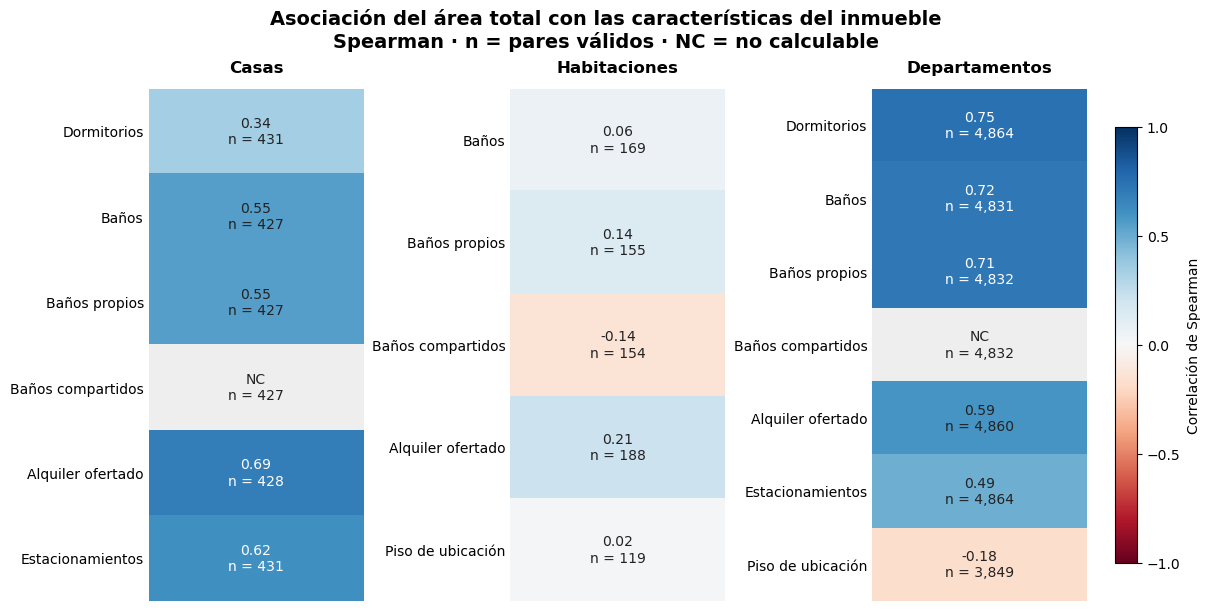

In [165]:
# ============================================================
# 33. CORRELACIÓN DEL ÁREA POR TIPO DE INMUEBLE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import display


VARIABLES_POR_TIPO = {
    "casa": [
        "dormitorios", "banos", "banos_propios",
        "banos_compartidos", "precio_pen_pub", "estacionamientos",
    ],
    "cuarto": [
        "banos", "banos_propios", "banos_compartidos",
        "precio_pen_pub", "piso_departamento",
    ],
    "departamento": [
        "dormitorios", "banos", "banos_propios",
        "banos_compartidos", "precio_pen_pub",
        "estacionamientos", "piso_departamento",
    ],
}

ETIQUETAS = {
    "dormitorios": "Dormitorios",
    "banos": "Baños",
    "banos_propios": "Baños propios",
    "banos_compartidos": "Baños compartidos",
    "precio_pen_pub": "Alquiler ofertado",
    "estacionamientos": "Estacionamientos",
    "piso_departamento": "Piso de ubicación",
}

TIPOS = {
    "casa": "Casas",
    "cuarto": "Habitaciones",
    "departamento": "Departamentos",
}


def calcular_correlaciones_area(datos):
    """Calcula Spearman por pares válidos, sin modificar la base."""
    requeridas = {"tipo_inmueble", "area_total_m2"}
    for variables in VARIABLES_POR_TIPO.values():
        requeridas.update(variables)

    faltantes = sorted(requeridas - set(datos.columns))
    if faltantes:
        raise ValueError(f"Faltan columnas necesarias: {faltantes}")

    base = datos.copy()

    # Excluir del análisis las áreas pendientes de verificación.
    pendiente = pd.Series(False, index=base.index)

    if "area_pendiente_verificacion" in base.columns:
        pendiente |= (
            base["area_pendiente_verificacion"]
            .astype("string")
            .str.strip()
            .str.lower()
            .isin(["true", "1", "1.0"])
        )

    # Caso pendiente documentado durante el EDA.
    if "id_anuncio" in base.columns:
        pendiente |= base["id_anuncio"].eq("babilonia-167543")

    base = base.loc[~pendiente].copy()
    resultados = []

    for tipo, variables in VARIABLES_POR_TIPO.items():
        grupo = base.loc[base["tipo_inmueble"].eq(tipo)]

        for variable in variables:
            pares = (
                grupo[["area_total_m2", variable]]
                .apply(pd.to_numeric, errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .dropna()
            )

            # Una superficie válida debe ser positiva.
            pares = pares.loc[pares["area_total_m2"].gt(0)]
            n = len(pares)

            if n < 3:
                rho = np.nan
                estado = "Menos de 3 pares válidos"
            elif pares.nunique().lt(2).any():
                rho = np.nan
                estado = "Variable constante"
            else:
                # Spearman = Pearson entre rangos; admite empates.
                rangos = pares.rank(method="average")
                rho = rangos["area_total_m2"].corr(rangos[variable])
                estado = "Calculada"

            resultados.append({
                "tipo_inmueble": tipo,
                "variable": variable,
                "pares_validos": n,
                "spearman": rho,
                "estado": estado,
            })

    return pd.DataFrame(resultados)


def graficar_correlaciones_area(resultados):
    """Dibuja un panel por tipo con una escala común de −1 a 1."""
    fig, axes = plt.subplots(
        1, 3, figsize=(12, 6), layout="constrained"
    )

    cmap = plt.get_cmap("RdBu").copy()
    cmap.set_bad("#eeeeee")
    norma = Normalize(vmin=-1, vmax=1)

    for ax, (tipo, titulo) in zip(axes, TIPOS.items()):
        tabla = (
            resultados.loc[resultados["tipo_inmueble"].eq(tipo)]
            .set_index("variable")
            .reindex(VARIABLES_POR_TIPO[tipo])
        )

        valores = tabla["spearman"].to_numpy(dtype=float)[:, None]

        ax.imshow(
            np.ma.masked_invalid(valores),
            cmap=cmap,
            norm=norma,
            aspect="auto",
        )

        ax.set_title(titulo, fontweight="bold", pad=12)
        ax.set_xticks([])
        ax.set_yticks(range(len(tabla)))
        ax.set_yticklabels(
            [ETIQUETAS[variable] for variable in tabla.index]
        )
        ax.tick_params(axis="y", length=0)

        for fila, (_, registro) in enumerate(tabla.iterrows()):
            rho = registro["spearman"]
            n = int(registro["pares_validos"])

            texto = (
                f"NC\nn = {n:,}"
                if pd.isna(rho)
                else f"{rho:.2f}\nn = {n:,}"
            )
            color = (
                "white" if pd.notna(rho) and abs(rho) >= 0.60
                else "#222222"
            )

            ax.text(
                0, fila, texto,
                ha="center", va="center",
                fontsize=10, color=color,
            )

        for borde in ax.spines.values():
            borde.set_visible(False)

    barra = fig.colorbar(
        ScalarMappable(norm=norma, cmap=cmap),
        ax=axes,
        shrink=0.85,
        pad=0.03,
    )
    barra.set_label("Correlación de Spearman")
    barra.set_ticks([-1, -0.5, 0, 0.5, 1])

    fig.suptitle(
        "Asociación del área total con las características del inmueble\n"
        "Spearman · n = pares válidos · NC = no calculable",
        fontsize=14,
        fontweight="bold",
    )

    return fig


# Calcular y presentar resultados.
correlaciones_area = calcular_correlaciones_area(df_eda_final)

display(
    correlaciones_area.style.format(
        {"spearman": "{:.3f}", "pares_validos": "{:,.0f}"},
        na_rep="NC",
    )
)

fig_correlaciones_area = graficar_correlaciones_area(
    correlaciones_area
)
plt.show()

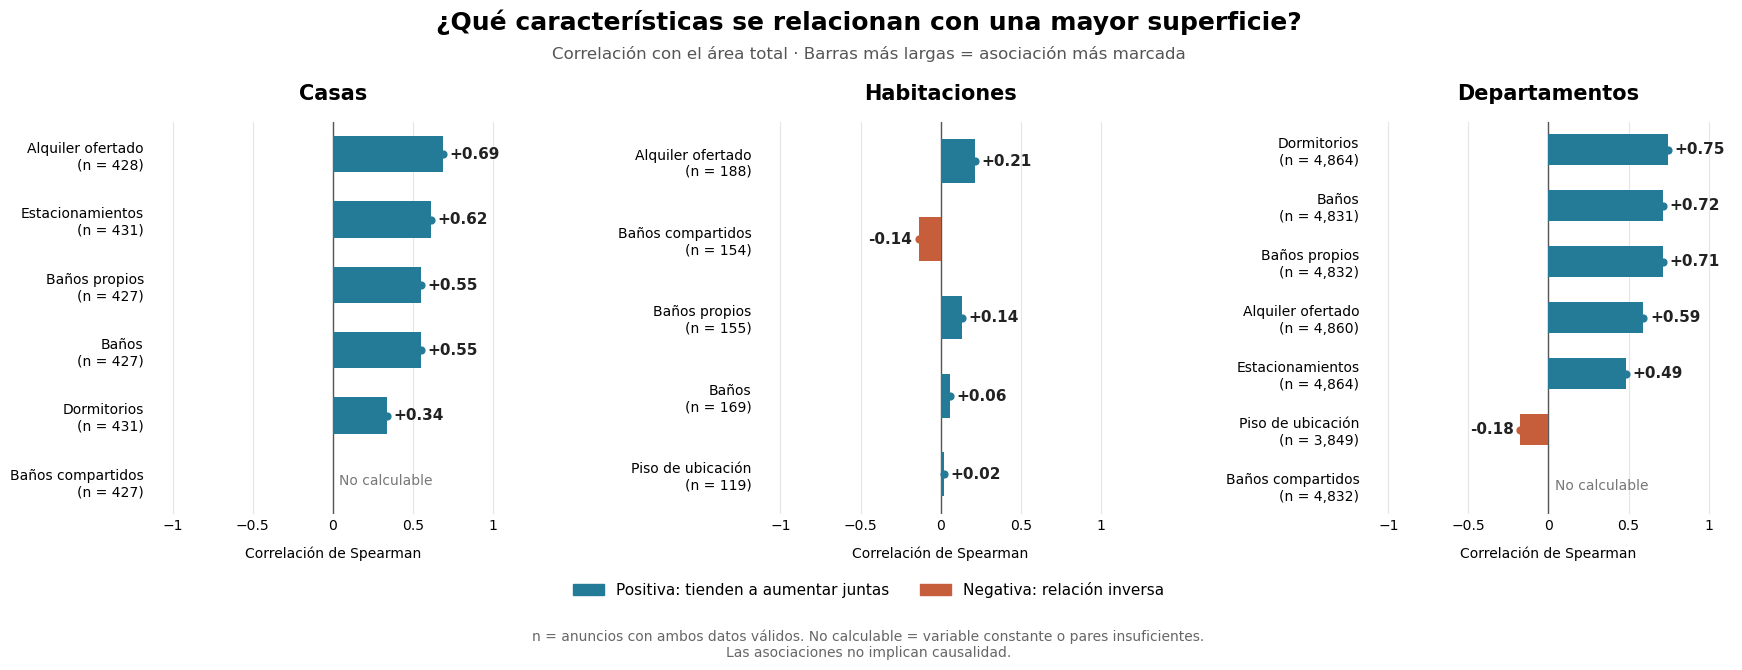

In [166]:
# ============================================================
# 34. CORRELACIONES DEL ÁREA: BARRAS HORIZONTALES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


def graficar_correlaciones_barras(resultados):
    """Presenta las correlaciones calculadas en tres paneles."""
    tipos = {
        "casa": "Casas",
        "cuarto": "Habitaciones",
        "departamento": "Departamentos",
    }

    etiquetas = {
        "dormitorios": "Dormitorios",
        "banos": "Baños",
        "banos_propios": "Baños propios",
        "banos_compartidos": "Baños compartidos",
        "precio_pen_pub": "Alquiler ofertado",
        "estacionamientos": "Estacionamientos",
        "piso_departamento": "Piso de ubicación",
    }

    positivo = "#247B97"
    negativo = "#C65D3B"

    fig, axes = plt.subplots(1, 3, figsize=(18, 7))
    fig.subplots_adjust(
        left=0.10, right=0.98, top=0.80,
        bottom=0.24, wspace=0.65,
    )

    for ax, (tipo, titulo) in zip(axes, tipos.items()):
        tabla = resultados.loc[
            resultados["tipo_inmueble"].eq(tipo)
        ].copy()

        # Mostrar primero las asociaciones de mayor magnitud.
        tabla["magnitud"] = tabla["spearman"].abs()
        tabla = tabla.sort_values(
            "magnitud", ascending=False, na_position="last"
        ).reset_index(drop=True)

        posiciones = np.arange(len(tabla))

        for posicion, fila in tabla.iterrows():
            rho = fila["spearman"]

            if pd.isna(rho):
                ax.text(
                    0.04, posicion, "No calculable",
                    va="center", fontsize=10, color="#777777",
                )
                continue

            color = positivo if rho >= 0 else negativo

            ax.barh(
                posicion, rho,
                height=0.56, color=color, zorder=3,
            )

            # Un punto permite ver asociaciones casi iguales a cero.
            ax.scatter(rho, posicion, color=color, s=24, zorder=4)

            # Evitar presentar “−0.00” por redondeo.
            texto = "≈ 0.00" if abs(rho) < 0.005 else f"{rho:+.2f}"

            ax.text(
                rho + (0.04 if rho >= 0 else -0.04),
                posicion,
                texto,
                va="center",
                ha="left" if rho >= 0 else "right",
                fontsize=11,
                fontweight="bold",
                color="#222222",
            )

        rotulos = [
            f"{etiquetas[fila['variable']]}\n"
            f"(n = {int(fila['pares_validos']):,})"
            for _, fila in tabla.iterrows()
        ]

        ax.set_yticks(posiciones)
        ax.set_yticklabels(rotulos, fontsize=10)
        ax.set_ylim(len(tabla) - 0.5, -0.5)
        ax.set_xlim(-1.15, 1.15)
        ax.set_xticks([-1, -0.5, 0, 0.5, 1])
        ax.set_xticklabels(["−1", "−0.5", "0", "0.5", "1"])

        ax.axvline(0, color="#555555", linewidth=1)
        ax.grid(axis="x", color="#E5E5E5", linewidth=0.8)
        ax.set_axisbelow(True)

        ax.set_title(titulo, fontsize=15, fontweight="bold", pad=16)
        ax.set_xlabel("Correlación de Spearman", labelpad=10)
        ax.tick_params(axis="both", length=0)

        for borde in ax.spines.values():
            borde.set_visible(False)

    fig.suptitle(
        "¿Qué características se relacionan con una mayor superficie?",
        fontsize=18, fontweight="bold", y=0.96,
    )

    fig.text(
        0.5, 0.89,
        "Correlación con el área total · "
        "Barras más largas = asociación más marcada",
        ha="center", fontsize=12, color="#555555",
    )

    fig.legend(
        handles=[
            Patch(color=positivo, label="Positiva: tienden a aumentar juntas"),
            Patch(color=negativo, label="Negativa: relación inversa"),
        ],
        loc="lower center",
        bbox_to_anchor=(0.5, 0.10),
        ncol=2, frameon=False, fontsize=11,
    )

    fig.text(
        0.5, 0.035,
        "n = anuncios con ambos datos válidos. "
        "No calculable = variable constante o pares insuficientes.\n"
        "Las asociaciones no implican causalidad.",
        ha="center", fontsize=10, color="#666666",
    )

    return fig


fig_correlaciones_barras = graficar_correlaciones_barras(
    correlaciones_area
)
plt.show()

### Interpretación de las correlaciones con el área total

**Casas.** El área presenta una asociación positiva con el alquiler
ofertado (ρ = 0.69), los estacionamientos (ρ = 0.61) y los baños
(ρ = 0.55). La relación con dormitorios es menor (ρ = 0.34).
En los anuncios analizados, las casas más grandes tienden a ofrecerse
a precios mayores y disponer de más estacionamientos y baños.

**Departamentos.** Las asociaciones más altas corresponden a
dormitorios (ρ = 0.75), baños (ρ = 0.72) y baños propios (ρ = 0.71).
El área también se relaciona positivamente con el alquiler
(ρ = 0.59) y los estacionamientos (ρ = 0.48).
La asociación con el piso de ubicación es negativa y débil
(ρ = −0.18).

**Habitaciones.** La asociación entre área y alquiler es positiva,
pero débil (ρ = 0.22). El área presenta asociaciones débiles con
baños propios (ρ = 0.28) y baños compartidos (ρ = −0.29).
La relación con baños totales y piso de ubicación es cercana a cero.
Estos resultados se basan en entre 128 y 206 pares válidos, por lo
que describen solamente las habitaciones con información disponible.

**Valores no calculables.** Los baños compartidos no presentan
variación en los pares analizados de casas y departamentos.
Por eso aparecen como NC; esto no equivale a una correlación de cero.

**Conclusión.** El área muestra asociaciones más marcadas con las
características físicas y el alquiler en casas y departamentos que
en habitaciones. Estos resultados respaldan el análisis separado
por tipo de inmueble, pero no demuestran causalidad ni determinan
por sí solos qué variables deben incorporarse a un modelo.

Las correlaciones no controlan por distrito u otras características.
Además, deben interpretarse considerando los datos faltantes y la
regla aplicada de completar estacionamientos faltantes con cero.

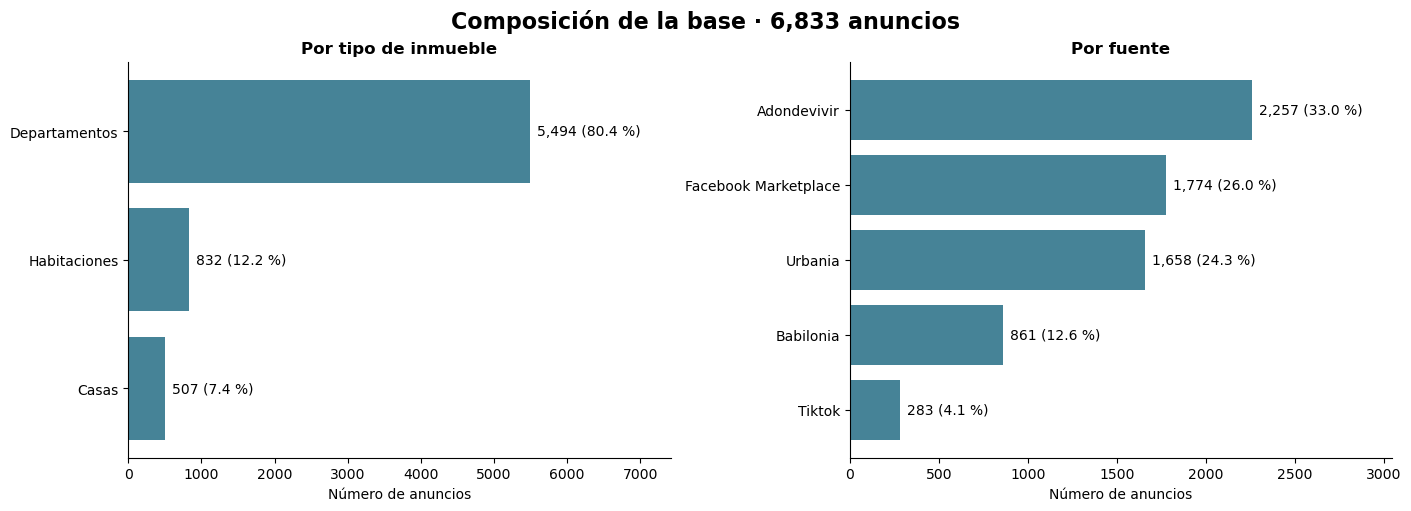

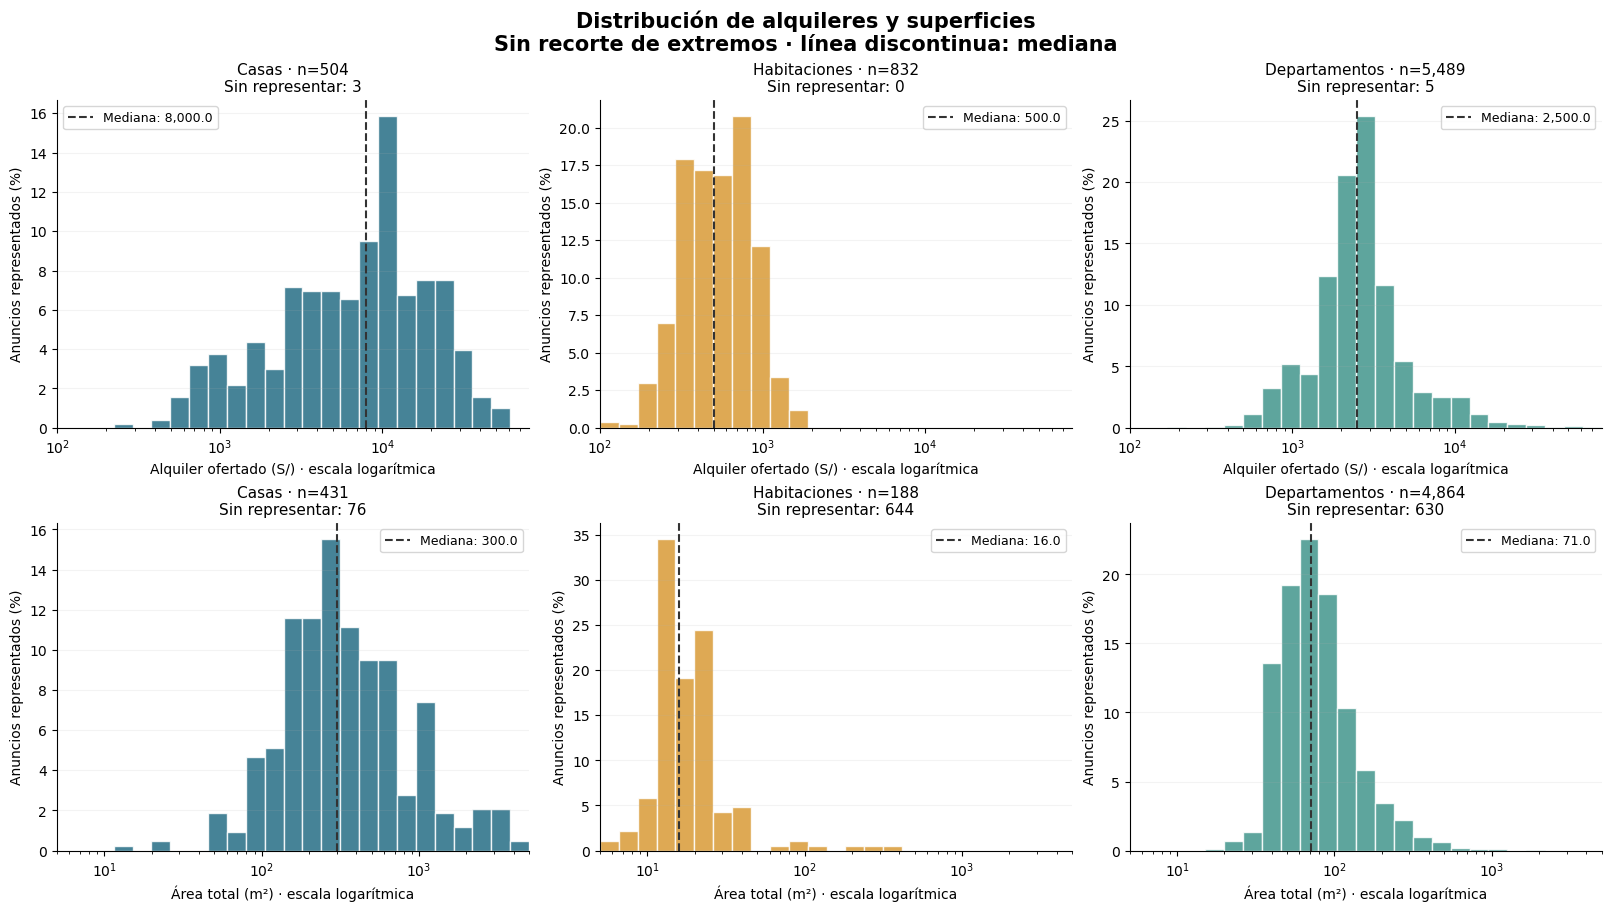

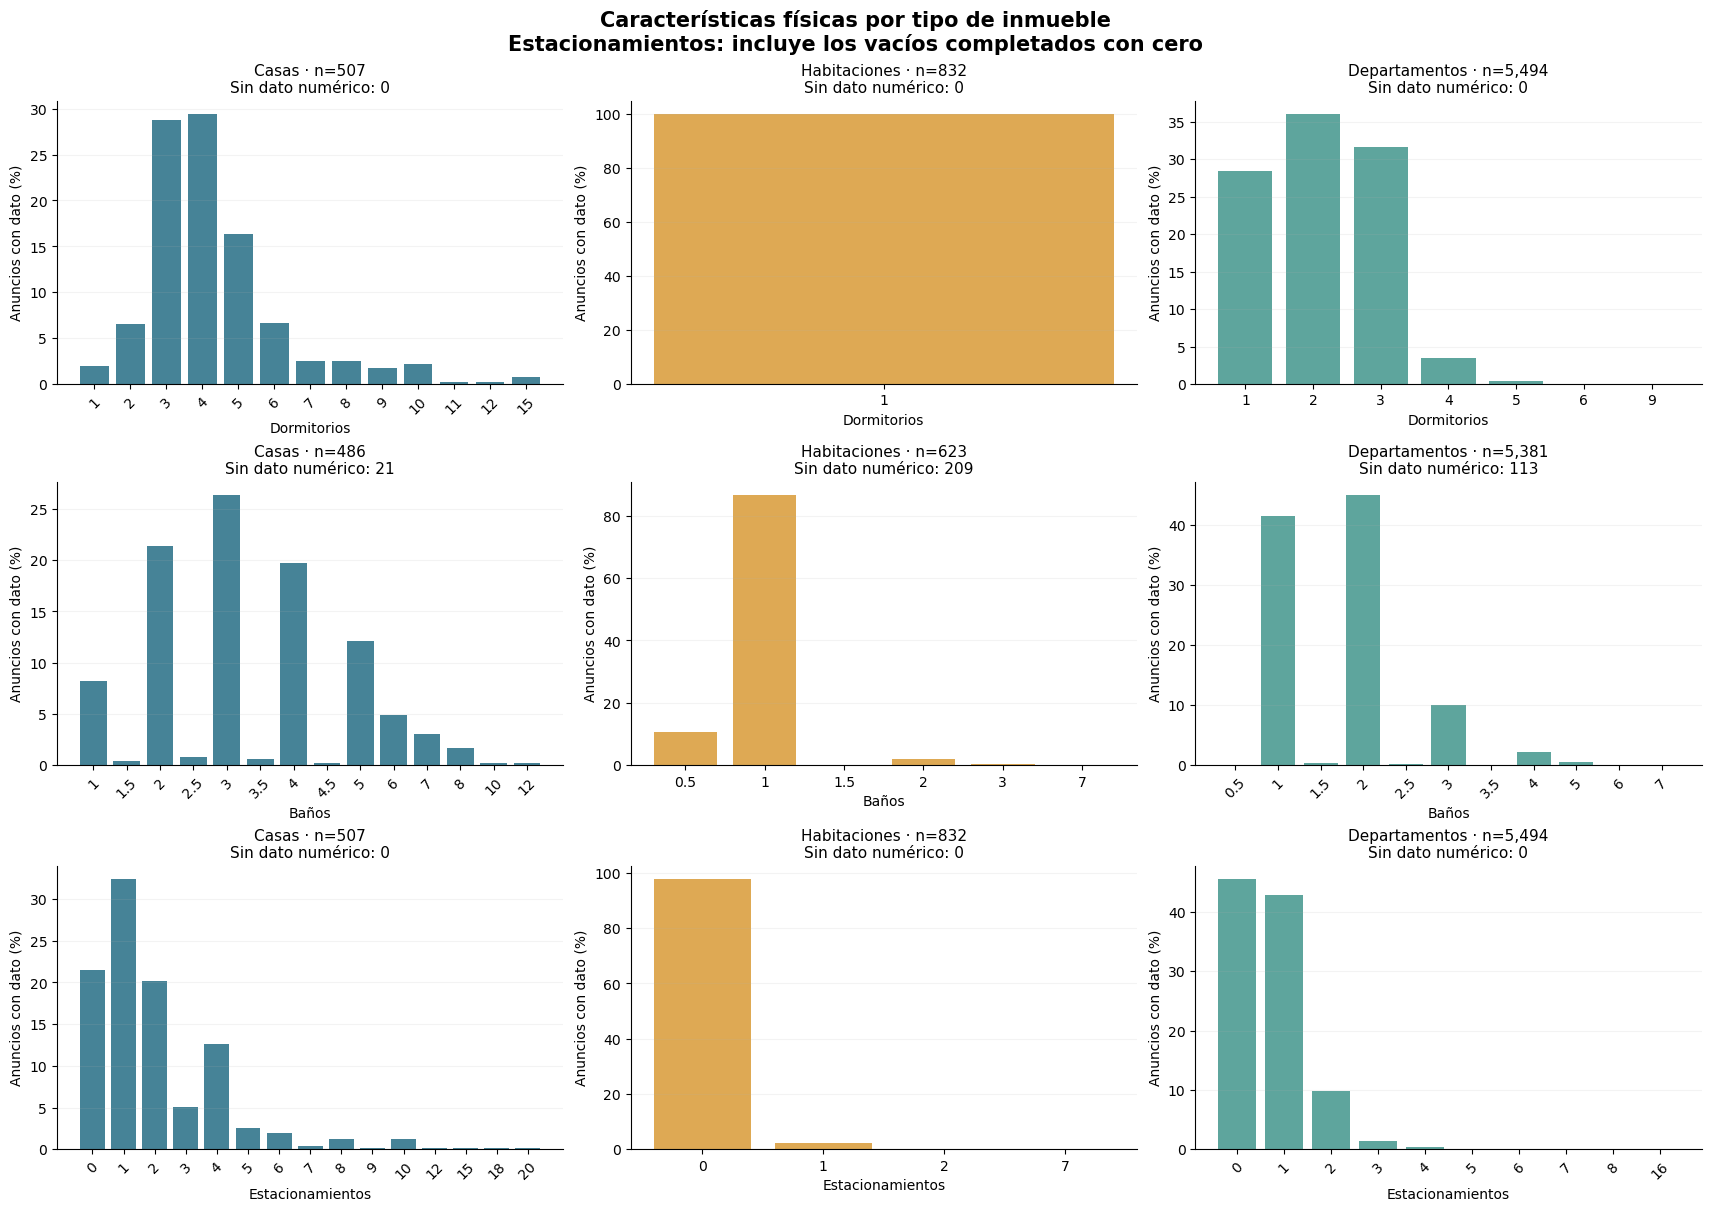

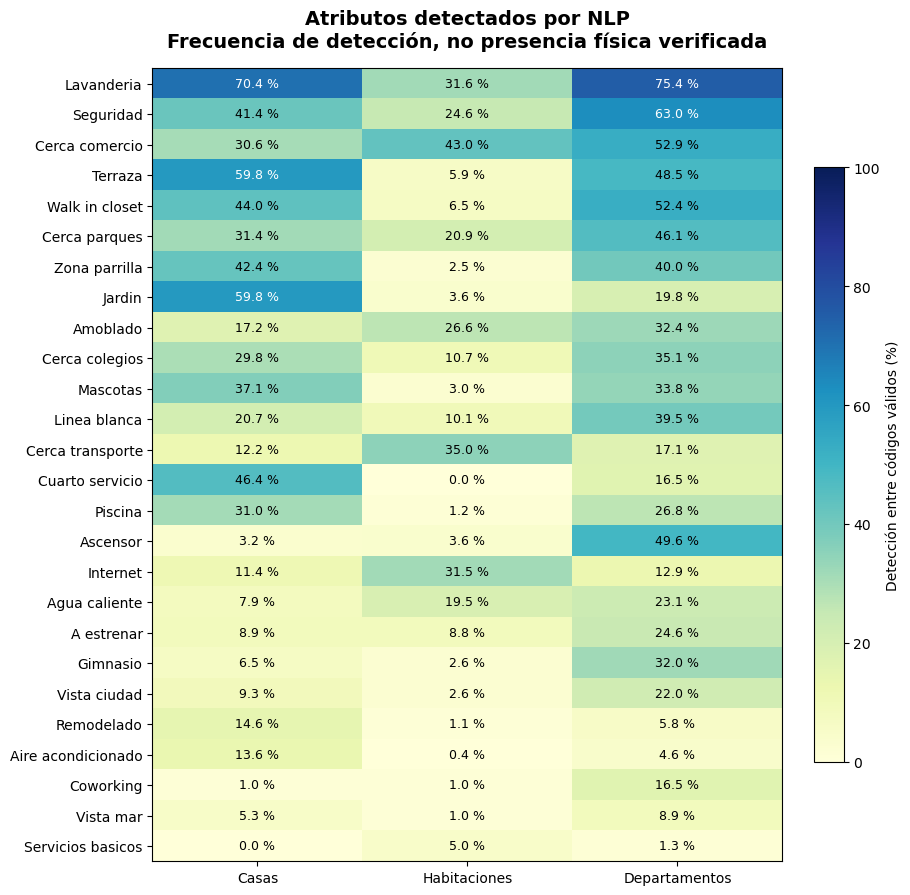

Gráficos guardados en: C:\Users\HP\Downloads\PI_EDA_Final\resultados_eda_revisado\graficos_descriptivos


In [167]:
# ============================================================
# 35. GRÁFICOS DESCRIPTIVOS DE LA BASE FINAL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path

TIPOS_GRAFICO = {
    "casa": ("Casas", "#256D85"),
    "cuarto": ("Habitaciones", "#D99A36"),
    "departamento": ("Departamentos", "#42958C"),
}

CARPETA_GRAFICOS = (
    Path(CARPETA_PROYECTO)
    / "resultados_eda_revisado"
    / "graficos_descriptivos"
)
CARPETA_GRAFICOS.mkdir(parents=True, exist_ok=True)


def guardar_mostrar(figura, nombre):
    """Guarda la figura y la muestra en el notebook."""
    figura.savefig(
        CARPETA_GRAFICOS / nombre,
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(figura)


def obtener_numericos(serie):
    """Conversión temporal: no modifica los datos originales."""
    return pd.to_numeric(
        serie, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)


# ============================================================
# 35.1. COMPOSICIÓN DE LA MUESTRA
# Los porcentajes se calculan sobre todos los anuncios.
# ============================================================

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), layout="constrained"
)

for ax, variable, titulo in zip(
    axes,
    ["tipo_inmueble", "portal"],
    ["Por tipo de inmueble", "Por fuente"],
):
    conteos = (
        df_eda_final[variable]
        .fillna("Sin información")
        .value_counts()
        .sort_values()
    )

    etiquetas = [
        TIPOS_GRAFICO[valor][0]
        if valor in TIPOS_GRAFICO
        else str(valor).replace("_", " ").title()
        for valor in conteos.index
    ]

    barras = ax.barh(
        etiquetas, conteos.values, color="#256D85", alpha=0.85
    )

    ax.bar_label(
        barras,
        labels=[
            f"{n:,} ({100 * n / len(df_eda_final):.1f} %)"
            for n in conteos
        ],
        padding=5,
        fontsize=10,
    )

    ax.set_xlim(0, conteos.max() * 1.35)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Número de anuncios")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    f"Composición de la base · {len(df_eda_final):,} anuncios",
    fontsize=16,
    fontweight="bold",
)

guardar_mostrar(fig, "01_composicion.png")


# ============================================================
# 35.2. DISTRIBUCIÓN DE PRECIOS Y ÁREAS
# Intervalos logarítmicos comunes por variable.
# Altura: porcentaje de observaciones representadas en cada grupo.
# ============================================================

variables_continuas = {
    "precio_pen_pub": "Alquiler ofertado (S/)",
    "area_total_m2": "Área total (m²)",
}

fig, axes = plt.subplots(
    2, 3, figsize=(16, 9), layout="constrained"
)

for fila, (variable, etiqueta) in enumerate(
    variables_continuas.items()
):
    todos = obtener_numericos(df_eda_final[variable])
    positivos = todos.loc[todos.gt(0)]

    if positivos.empty:
        for ax in axes[fila]:
            ax.text(
                0.5, 0.5, "Sin valores positivos disponibles",
                ha="center", va="center", transform=ax.transAxes,
            )
            ax.set_axis_off()
        continue

    minimo, maximo = positivos.min(), positivos.max()

    if minimo == maximo:
        minimo, maximo = minimo / 1.1, maximo * 1.1

    intervalos = np.geomspace(minimo, maximo, 26)

    for columna, (tipo, (nombre, color)) in enumerate(
        TIPOS_GRAFICO.items()
    ):
        ax = axes[fila, columna]
        grupo = df_eda_final.loc[
            df_eda_final["tipo_inmueble"].eq(tipo)
        ]
        serie = obtener_numericos(grupo[variable])
        valores = serie.loc[serie.gt(0)]

        if not valores.empty:
            ax.hist(
                valores,
                bins=intervalos,
                weights=np.full(len(valores), 100 / len(valores)),
                color=color,
                edgecolor="white",
                alpha=0.85,
            )
            ax.axvline(
                valores.median(),
                color="#333333",
                linestyle="--",
                linewidth=1.5,
                label=f"Mediana: {valores.median():,.1f}",
            )
            ax.legend(fontsize=9)

        ax.set_xscale("log")
        ax.set_xlim(intervalos[0], intervalos[-1])
        ax.set_title(
            f"{nombre} · n={len(valores):,}\n"
            f"Sin representar: {len(grupo) - len(valores):,}",
            fontsize=11,
        )
        ax.set_xlabel(f"{etiqueta} · escala logarítmica")
        ax.set_ylabel("Anuncios representados (%)")
        ax.grid(axis="y", alpha=0.15)
        ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Distribución de alquileres y superficies\n"
    "Sin recorte de extremos · línea discontinua: mediana",
    fontsize=15,
    fontweight="bold",
)

guardar_mostrar(fig, "02_distribucion_precio_area.png")


# ============================================================
# 35.3. FRECUENCIAS DE DORMITORIOS, BAÑOS Y ESTACIONAMIENTOS
# Se mantienen las categorías originales, incluidos medios baños.
# ============================================================

variables_conteo = {
    "dormitorios": "Dormitorios",
    "banos": "Baños",
    "estacionamientos": "Estacionamientos",
}

fig, axes = plt.subplots(
    3, 3, figsize=(17, 12), layout="constrained"
)

for fila, (variable, etiqueta) in enumerate(
    variables_conteo.items()
):
    for columna, (tipo, (nombre, color)) in enumerate(
        TIPOS_GRAFICO.items()
    ):
        ax = axes[fila, columna]
        grupo = df_eda_final.loc[
            df_eda_final["tipo_inmueble"].eq(tipo)
        ]
        serie = obtener_numericos(grupo[variable])
        frecuencias = serie.dropna().value_counts().sort_index()

        if frecuencias.empty:
            ax.text(
                0.5, 0.5, "Sin información",
                ha="center", va="center", transform=ax.transAxes,
            )
            ax.set_axis_off()
            continue

        porcentajes = frecuencias / frecuencias.sum() * 100

        ax.bar(
            np.arange(len(frecuencias)),
            porcentajes.values,
            color=color,
            alpha=0.85,
        )

        ax.set_xticks(np.arange(len(frecuencias)))
        ax.set_xticklabels(
            [f"{valor:g}" for valor in frecuencias.index],
            rotation=45 if len(frecuencias) > 8 else 0,
        )
        ax.set_title(
            f"{nombre} · n={frecuencias.sum():,}\n"
            f"Sin dato numérico: {serie.isna().sum():,}",
            fontsize=11,
        )
        ax.set_xlabel(etiqueta)
        ax.set_ylabel("Anuncios con dato (%)")
        ax.grid(axis="y", alpha=0.15)
        ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Características físicas por tipo de inmueble\n"
    "Estacionamientos: incluye los vacíos completados con cero",
    fontsize=15,
    fontweight="bold",
)

guardar_mostrar(fig, "03_caracteristicas_fisicas.png")


# ============================================================
# 35.4. ATRIBUTOS NLP POR TIPO DE INMUEBLE
# Porcentaje de unos entre códigos válidos 0/1.
# Cero significa no detectado, no ausencia física comprobada.
# ============================================================

atributos = [
    columna for columna in df_eda_final.columns
    if columna.startswith("attr_")
]

if atributos:
    nlp = df_eda_final[atributos].apply(
        pd.to_numeric, errors="coerce"
    )
    nlp = nlp.where(nlp.isin([0, 1]))
    nlp["tipo_inmueble"] = df_eda_final["tipo_inmueble"]

    frecuencias_nlp = (
        nlp.groupby("tipo_inmueble")[atributos]
        .mean()
        .mul(100)
        .T
        .reindex(columns=list(TIPOS_GRAFICO))
    )

    orden = frecuencias_nlp.mean(axis=1).sort_values(
        ascending=False
    ).index
    frecuencias_nlp = frecuencias_nlp.loc[orden]

    fig, ax = plt.subplots(
        figsize=(9, max(8, len(atributos) * 0.34)),
        layout="constrained",
    )

    colores = plt.get_cmap("YlGnBu").copy()
    colores.set_bad("#EEEEEE")

    imagen = ax.imshow(
        np.ma.masked_invalid(frecuencias_nlp.to_numpy()),
        cmap=colores,
        vmin=0,
        vmax=100,
        aspect="auto",
    )

    ax.set_xticks(range(len(TIPOS_GRAFICO)))
    ax.set_xticklabels([
        nombre for nombre, _ in TIPOS_GRAFICO.values()
    ])
    ax.set_yticks(range(len(frecuencias_nlp)))
    ax.set_yticklabels([
        variable.removeprefix("attr_").replace("_", " ").capitalize()
        for variable in frecuencias_nlp.index
    ])

    for fila in range(len(frecuencias_nlp)):
        for columna in range(len(TIPOS_GRAFICO)):
            valor = frecuencias_nlp.iloc[fila, columna]
            ax.text(
                columna, fila,
                "Sin datos" if pd.isna(valor) else f"{valor:.1f} %",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if pd.notna(valor) and valor > 55 else "black",
            )

    fig.colorbar(
        imagen, ax=ax, label="Detección entre códigos válidos (%)",
        shrink=0.75,
    )
    ax.set_title(
        "Atributos detectados por NLP\n"
        "Frecuencia de detección, no presencia física verificada",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )

    guardar_mostrar(fig, "04_atributos_nlp.png")

print(f"Gráficos guardados en: {CARPETA_GRAFICOS.resolve()}")

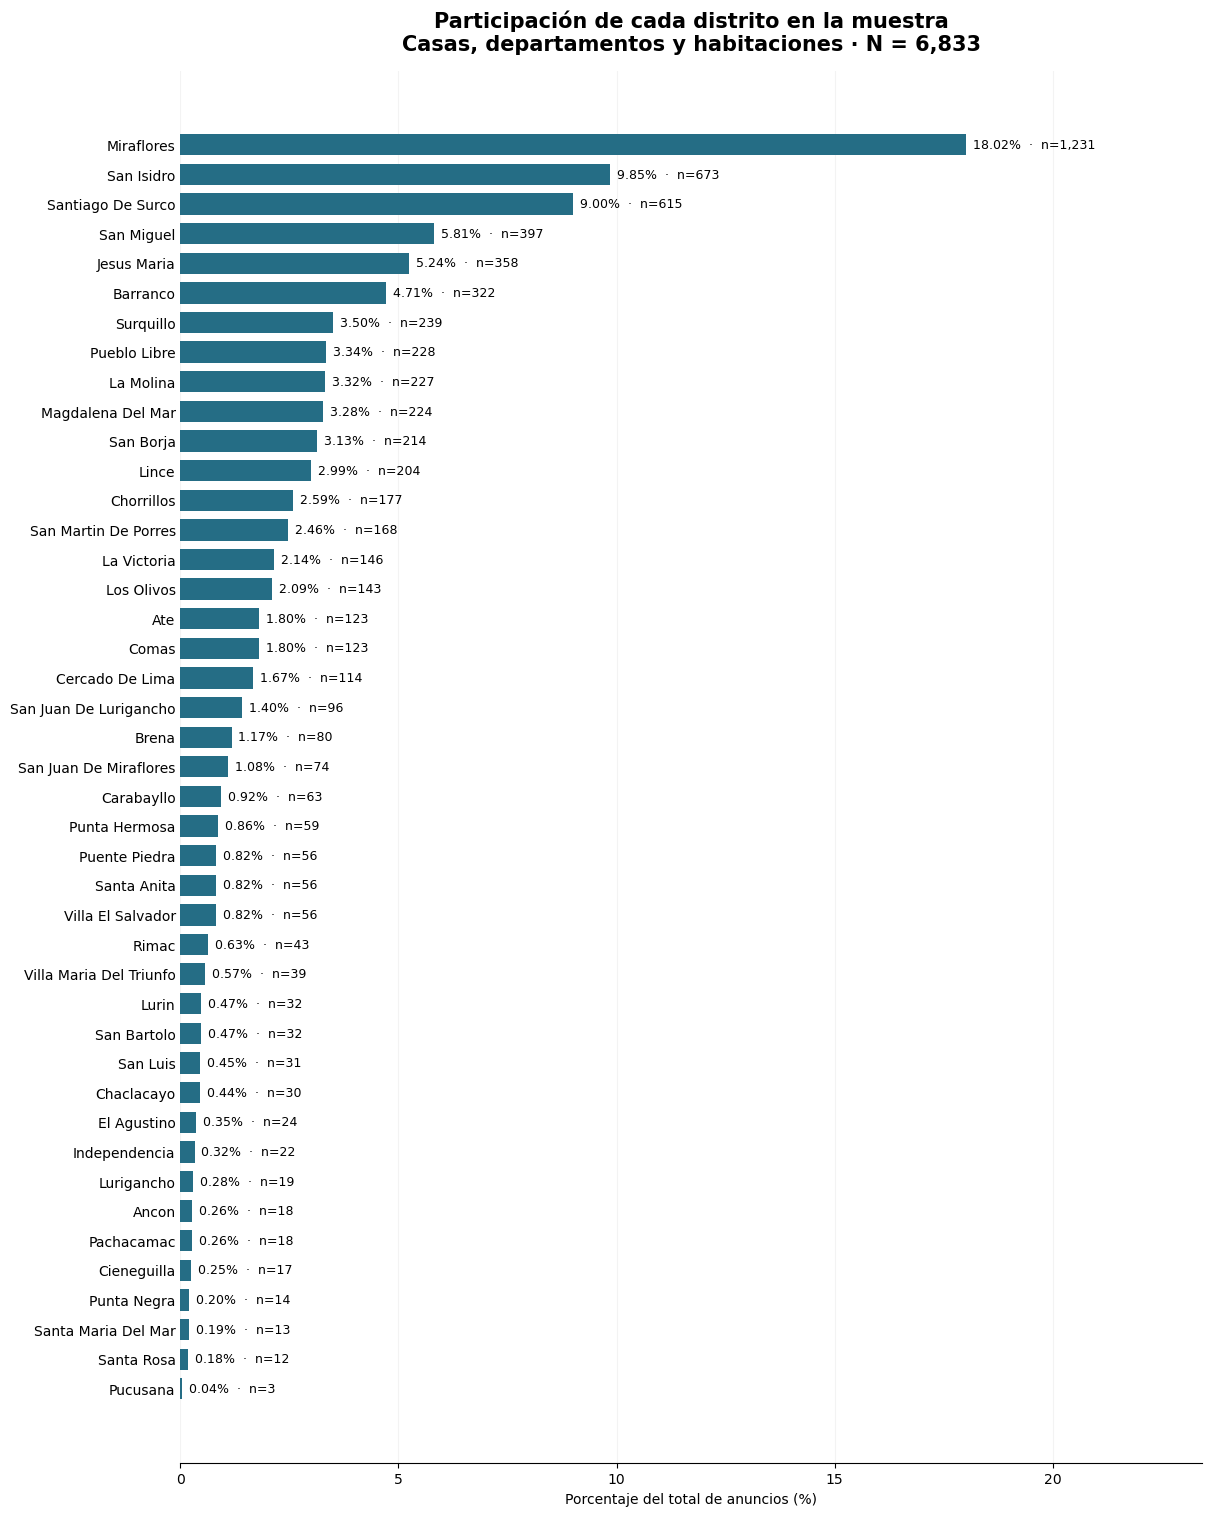

,distrito,anuncios,porcentaje
0,miraflores,"1,231",18.02%
1,san isidro,673,9.85%
2,santiago de surco,615,9.00%
3,san miguel,397,5.81%
4,jesus maria,358,5.24%
5,barranco,322,4.71%
6,surquillo,239,3.50%
7,pueblo libre,228,3.34%
8,la molina,227,3.32%
9,magdalena del mar,224,3.28%


In [175]:
# ============================================================
# 36. DISTRIBUCIÓN PORCENTUAL DE LA MUESTRA POR DISTRITO
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Agrupar sin modificar la base.
distritos = (
    df_eda_final["distrito"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace("", pd.NA)
    .fillna("Sin distrito informado")
)

resumen_distritos_muestra = (
    distritos.value_counts()
    .rename_axis("distrito")
    .reset_index(name="anuncios")
)

total_anuncios = len(df_eda_final)

resumen_distritos_muestra["porcentaje"] = (
    resumen_distritos_muestra["anuncios"]
    .div(total_anuncios)
    .mul(100)
)

resumen_distritos_muestra = (
    resumen_distritos_muestra
    .sort_values(
        ["anuncios", "distrito"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

# Gráfico de todos los distritos de la muestra.
fig, ax = plt.subplots(
    figsize=(12, max(6, len(resumen_distritos_muestra) * 0.35)),
    layout="constrained",
)

barras = ax.barh(
    resumen_distritos_muestra["distrito"].str.title(),
    resumen_distritos_muestra["porcentaje"],
    color="#256D85",
    height=0.72,
)

ax.bar_label(
    barras,
    labels=[
        f"{porcentaje:.2f}%  ·  n={cantidad:,}"
        for porcentaje, cantidad in zip(
            resumen_distritos_muestra["porcentaje"],
            resumen_distritos_muestra["anuncios"],
        )
    ],
    padding=5,
    fontsize=9,
)

ax.invert_yaxis()
ax.set_xlim(
    0,
    resumen_distritos_muestra["porcentaje"].max() * 1.30,
)
ax.set_xlabel("Porcentaje del total de anuncios (%)")
ax.set_ylabel("")
ax.set_title(
    "Participación de cada distrito en la muestra\n"
    f"Casas, departamentos y habitaciones · N = {total_anuncios:,}",
    fontsize=15,
    fontweight="bold",
    pad=15,
)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.15)
ax.tick_params(axis="y", length=0, labelsize=10)
ax.spines[["top", "right", "left"]].set_visible(False)

# Guardar gráfico y tabla.
carpeta = (
    Path(CARPETA_PROYECTO)
    / "resultados_eda_revisado"
    / "graficos_descriptivos"
)
carpeta.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta / "05_porcentaje_todos_distritos.png",
    dpi=200,
    bbox_inches="tight",
)

resumen_distritos_muestra.to_csv(
    carpeta / "porcentaje_todos_distritos.csv",
    index=False,
    encoding="utf-8-sig",
)

plt.show()

display(
    resumen_distritos_muestra.style.format({
        "anuncios": "{:,.0f}",
        "porcentaje": "{:.2f}%",
    })
)

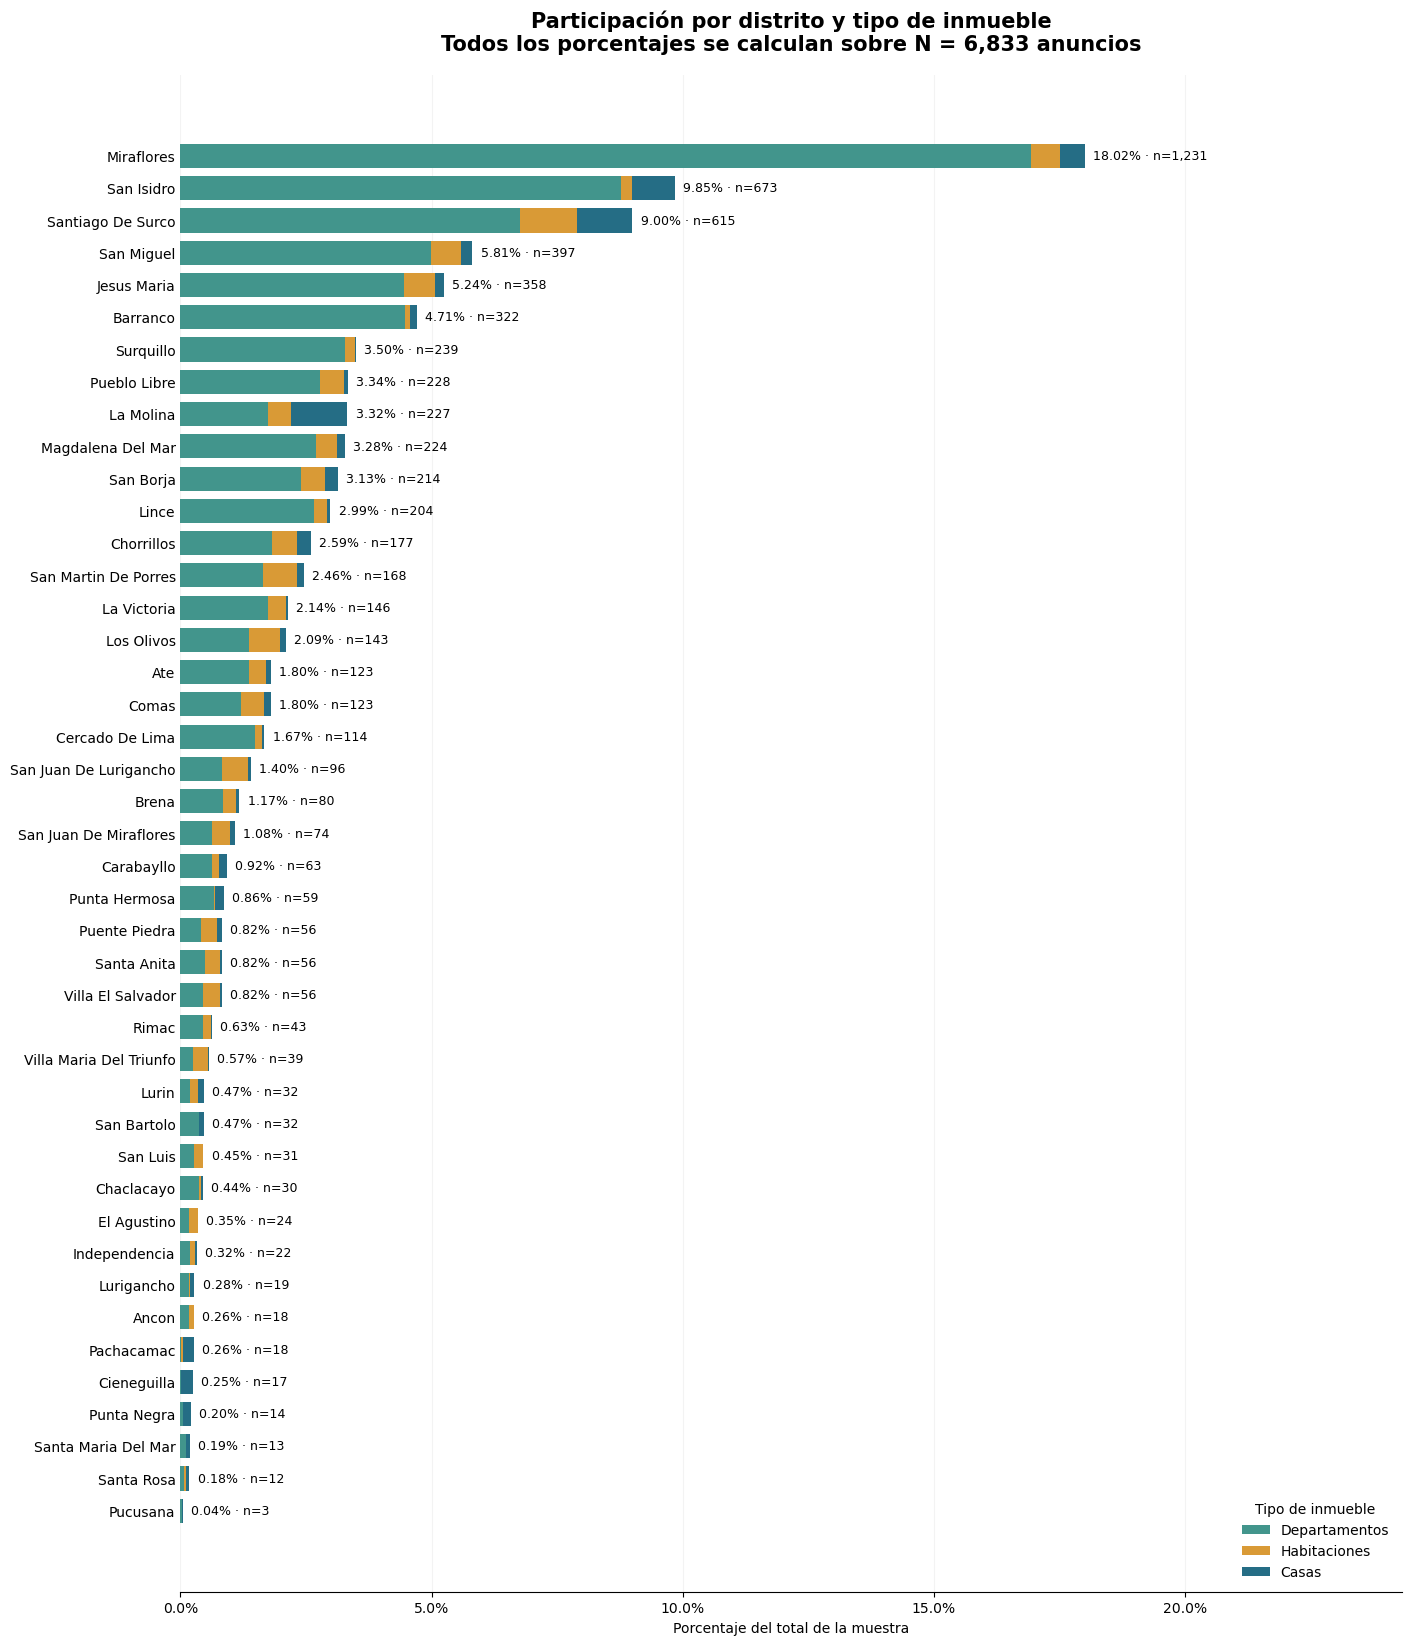

tipo_inmueble,distrito,Departamentos (%),Habitaciones (%),Casas (%),Total distrito (%),Anuncios
0,miraflores,16.95%,0.57%,0.50%,18.02%,"1,231"
1,san isidro,8.78%,0.20%,0.86%,9.85%,673
2,santiago de surco,6.76%,1.13%,1.11%,9.00%,615
3,san miguel,4.99%,0.60%,0.22%,5.81%,397
4,jesus maria,4.45%,0.63%,0.16%,5.24%,358
5,barranco,4.48%,0.10%,0.13%,4.71%,322
6,surquillo,3.28%,0.19%,0.03%,3.50%,239
7,pueblo libre,2.78%,0.47%,0.09%,3.34%,228
8,la molina,1.74%,0.47%,1.11%,3.32%,227
9,magdalena del mar,2.71%,0.41%,0.16%,3.28%,224


In [179]:
# ============================================================
# 36. PARTICIPACIÓN POR DISTRITO Y TIPO DE INMUEBLE
# Denominador: todos los anuncios de df_eda_final.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import PercentFormatter

# Copia temporal: no modifica la base final.
base_grafico = df_eda_final[
    ["distrito", "tipo_inmueble"]
].copy()

base_grafico["distrito"] = (
    base_grafico["distrito"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace("", pd.NA)
    .fillna("sin distrito informado")
)

tipos = ["departamento", "cuarto", "casa"]

nombres = {
    "departamento": "Departamentos",
    "cuarto": "Habitaciones",
    "casa": "Casas",
}

colores = {
    "departamento": "#42958C",
    "cuarto": "#D99A36",
    "casa": "#256D85",
}

# Evitar que categorías desconocidas queden fuera del gráfico.
if not base_grafico["tipo_inmueble"].isin(tipos).all():
    raise ValueError(
        "Existen tipos de inmueble vacíos o no reconocidos. "
        "Revisarlos antes de calcular los porcentajes."
    )

total_muestra = len(base_grafico)

if total_muestra == 0:
    raise ValueError("La base no contiene anuncios.")

# Cantidad de anuncios por distrito y tipo.
conteos_distrito_tipo = pd.crosstab(
    base_grafico["distrito"],
    base_grafico["tipo_inmueble"],
).reindex(columns=tipos, fill_value=0)

# Ordenar distritos por cantidad total de anuncios.
orden = (
    conteos_distrito_tipo.sum(axis=1)
    .rename("total")
    .reset_index()
    .sort_values(
        ["total", "distrito"],
        ascending=[False, True],
    )["distrito"]
)

conteos_distrito_tipo = conteos_distrito_tipo.loc[orden]

# Todos los porcentajes utilizan el mismo denominador.
porcentajes_distrito_tipo = (
    conteos_distrito_tipo.div(total_muestra).mul(100)
)

total_distrito = conteos_distrito_tipo.sum(axis=1)
porcentaje_distrito = porcentajes_distrito_tipo.sum(axis=1)

assert int(total_distrito.sum()) == total_muestra
assert np.isclose(porcentaje_distrito.sum(), 100)

# ------------------------------------------------------------
# Gráfico horizontal de barras apiladas
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(14, max(7, len(conteos_distrito_tipo) * 0.38)),
    layout="constrained",
)

posiciones = np.arange(len(conteos_distrito_tipo))
inicio = np.zeros(len(conteos_distrito_tipo))

for tipo in tipos:
    valores = porcentajes_distrito_tipo[tipo].to_numpy()

    ax.barh(
        posiciones,
        valores,
        left=inicio,
        height=0.75,
        label=nombres[tipo],
        color=colores[tipo],
    )

    inicio += valores

# Etiqueta final: porcentaje total y cantidad del distrito.
for posicion, porcentaje, cantidad in zip(
    posiciones,
    porcentaje_distrito,
    total_distrito,
):
    ax.annotate(
        f"{porcentaje:.2f}% · n={cantidad:,}",
        xy=(porcentaje, posicion),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

ax.set_yticks(posiciones)
ax.set_yticklabels(
    conteos_distrito_tipo.index.str.title(),
    fontsize=10,
)
ax.invert_yaxis()

ax.set_xlim(0, porcentaje_distrito.max() * 1.35)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel("Porcentaje del total de la muestra")
ax.set_ylabel("")

ax.set_title(
    "Participación por distrito y tipo de inmueble\n"
    f"Todos los porcentajes se calculan sobre N = {total_muestra:,} anuncios",
    fontsize=15,
    fontweight="bold",
    pad=18,
)

ax.legend(
    loc="lower right",
    title="Tipo de inmueble",
    frameon=False,
)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.15)
ax.tick_params(axis="y", length=0)
ax.spines[["top", "right", "left"]].set_visible(False)

# ------------------------------------------------------------
# Tabla con porcentajes exactos, incluidos segmentos pequeños
# ------------------------------------------------------------
tabla_distrito_tipo = porcentajes_distrito_tipo.rename(
    columns={
        tipo: f"{nombres[tipo]} (%)"
        for tipo in tipos
    }
).copy()

tabla_distrito_tipo["Total distrito (%)"] = porcentaje_distrito
tabla_distrito_tipo["Anuncios"] = total_distrito
tabla_distrito_tipo = tabla_distrito_tipo.reset_index()

# Guardar resultados.
carpeta = (
    Path(CARPETA_PROYECTO)
    / "resultados_eda_revisado"
    / "graficos_descriptivos"
)
carpeta.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta / "porcentaje_distrito_por_inmueble.png",
    dpi=200,
    bbox_inches="tight",
)

tabla_distrito_tipo.to_csv(
    carpeta / "porcentaje_distrito_por_inmueble.csv",
    index=False,
    encoding="utf-8-sig",
)

plt.show()

formato = {
    columna: "{:.2f}%"
    for columna in tabla_distrito_tipo.columns
    if "(%)" in columna
}
formato["Anuncios"] = "{:,.0f}"

display(tabla_distrito_tipo.style.format(formato))

### Selección de variables y tratamiento de datos faltantes

Para conformar la base de modelamiento, se seleccionaron 30 variables relacionadas con el alquiler ofertado, la ubicación y las características de los inmuebles. Posteriormente, se aplicó el **análisis de casos completos** (*complete-case analysis*), conservando únicamente los anuncios con información disponible en todas las variables seleccionadas. Esta decisión permite entrenar y comparar los modelos sobre una misma muestra, sin introducir imputaciones adicionales.

El procedimiento excluyó **429 anuncios (6.28 %)** y conservó **6,404 observaciones (93.72 %)**. Los valores faltantes de las variables no seleccionadas no determinaron la eliminación de registros.

Aunque la pérdida global fue limitada, este porcentaje no garantiza ausencia de sesgo, pues la validez del análisis depende del mecanismo que origina los datos faltantes. Por ello, se reconoce como limitación la posible selección de anuncios con mayor disponibilidad de información. Asimismo, la exclusión de variables constituye una decisión de especificación del modelo y no demuestra que carezcan de utilidad predictiva.

In [180]:
import pandas as pd
from pathlib import Path

# 1. Cargar la base final del EDA.
carpeta = Path(CARPETA_PROYECTO) / "resultados_eda_revisado"
entrada = carpeta / "base_alquileres_eda_final.csv"
salida = carpeta / "base_alquileres_modelo.csv"

datos = pd.read_csv(entrada, encoding="utf-8-sig")

# 2. Seleccionar únicamente las variables solicitadas.
cols_mantener = [
    'distrito',
    'ambito',
    'tipo_inmueble',
    'precio_pen_pub',
    'dormitorios',
    'estacionamientos',
    'latitud',
    'longitud',
    'banos_propios',
    'banos_compartidos',
    'attr_amoblado',
    'attr_piscina',
    'attr_jardin',
    'attr_terraza',
    'attr_seguridad',
    'attr_ascensor',
    'attr_mascotas',
    'attr_lavanderia',
    'attr_cuarto_servicio',
    'attr_aire_acondicionado',
    'attr_gimnasio',
    'attr_a_estrenar',
    'attr_remodelado',
    'attr_linea_blanca',
    'attr_agua_caliente',
    'attr_walk_in_closet',
    'attr_coworking',
    'attr_zona_parrilla',
    'attr_servicios_basicos',
    'attr_internet'
]

columnas_ausentes = [
    columna for columna in cols_mantener
    if columna not in datos.columns
]
if columnas_ausentes:
    raise ValueError(f"Columnas no encontradas: {columnas_ausentes}")

seleccion = datos.loc[:, cols_mantener].copy()

# Reconocer también como faltantes las celdas vacías o con espacios.
seleccion = seleccion.replace(r"^\s*$", pd.NA, regex=True)

# 3. Eliminar filas con al menos un faltante en las variables seleccionadas.
df_modelo = seleccion.dropna(how="any").reset_index(drop=True)

# 4. Guardar el resultado sin sobrescribir la base final del EDA.
df_modelo.to_csv(salida, index=False, encoding="utf-8-sig")

resumen = pd.DataFrame({
    "concepto": [
        "Registros de entrada",
        "Registros eliminados por faltantes",
        "Registros conservados",
        "Variables conservadas"
    ],
    "cantidad": [
        len(datos),
        len(datos) - len(df_modelo),
        len(df_modelo),
        df_modelo.shape[1]
    ]
})

display(resumen)
print(f"Archivo guardado: {salida}")

,concepto,cantidad
0,Registros de entrada,6833
1,Registros eliminados por faltantes,429
2,Registros conservados,6404
3,Variables conservadas,30


Archivo guardado: c:\Users\HP\Downloads\PI_EDA_Final\resultados_eda_revisado\base_alquileres_modelo.csv


Registros de la base: 6,404
Variables: 30
Registros no representables en gráficos de precio: 0


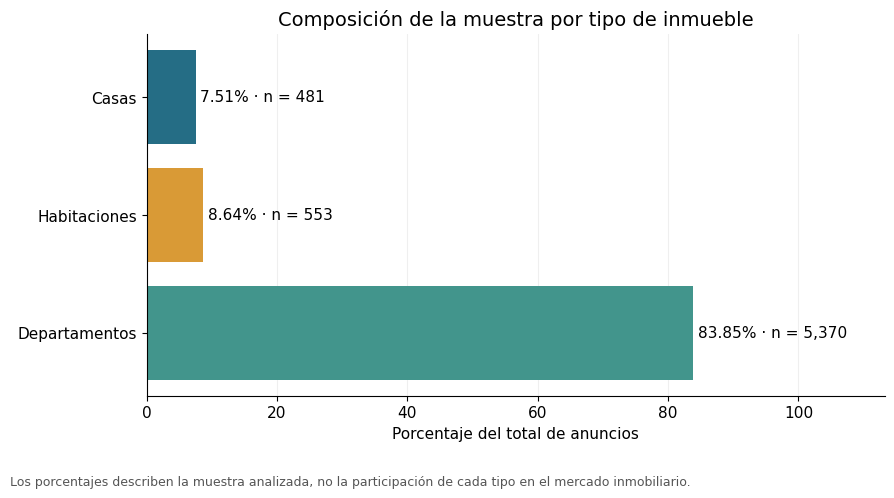

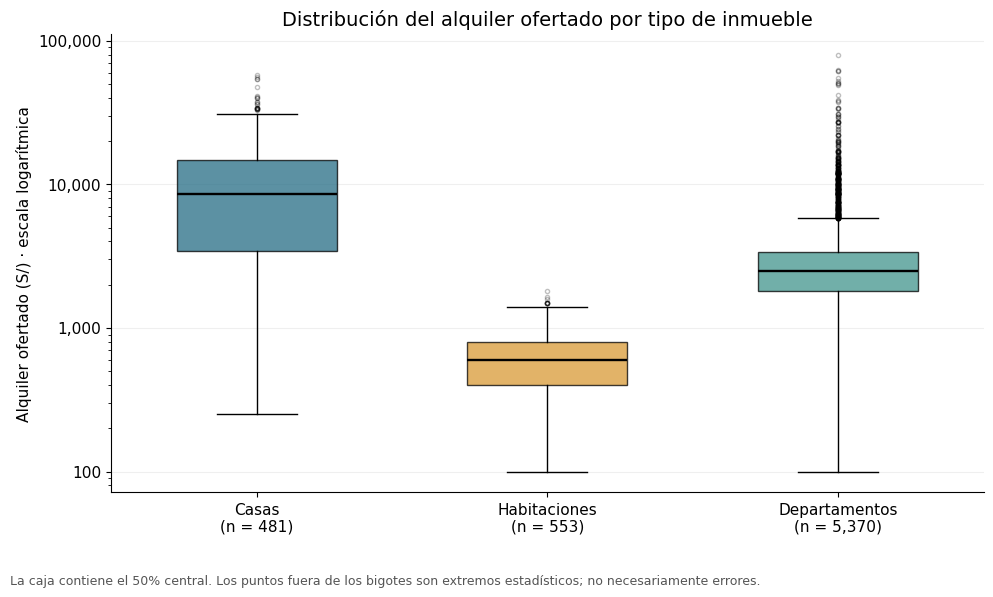

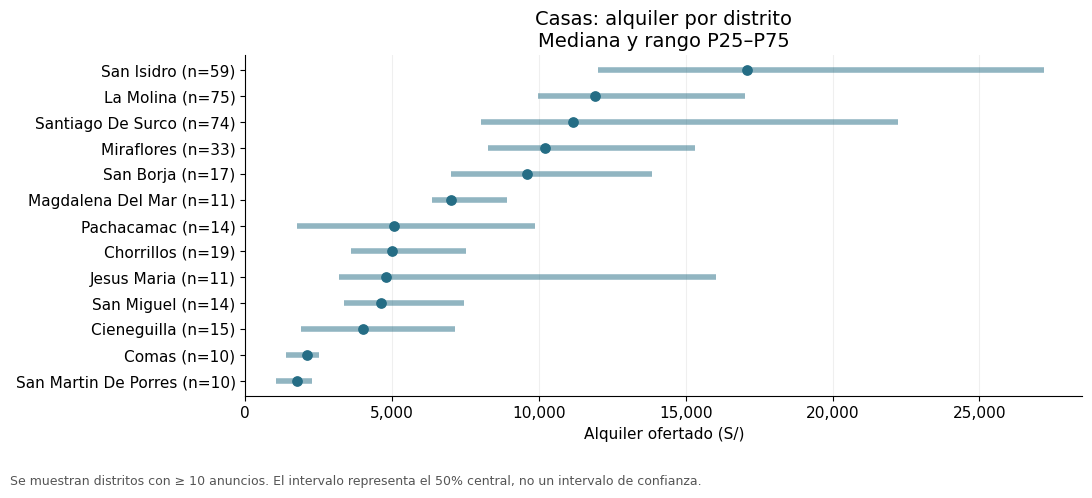

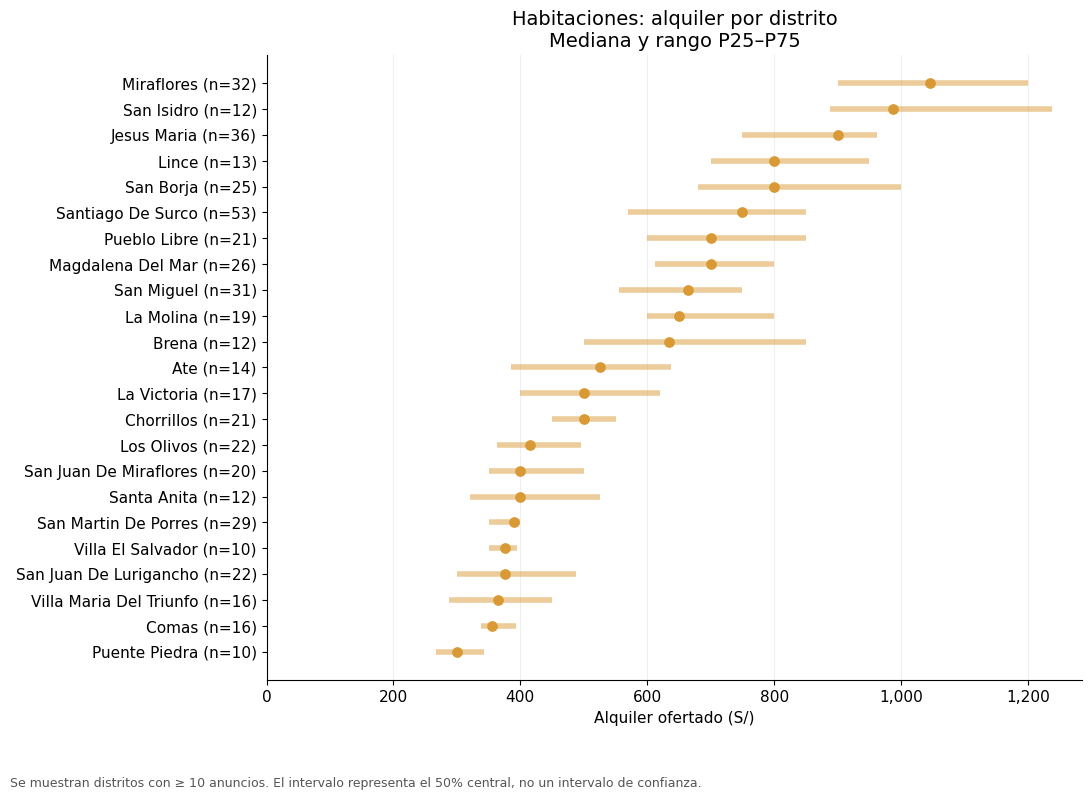

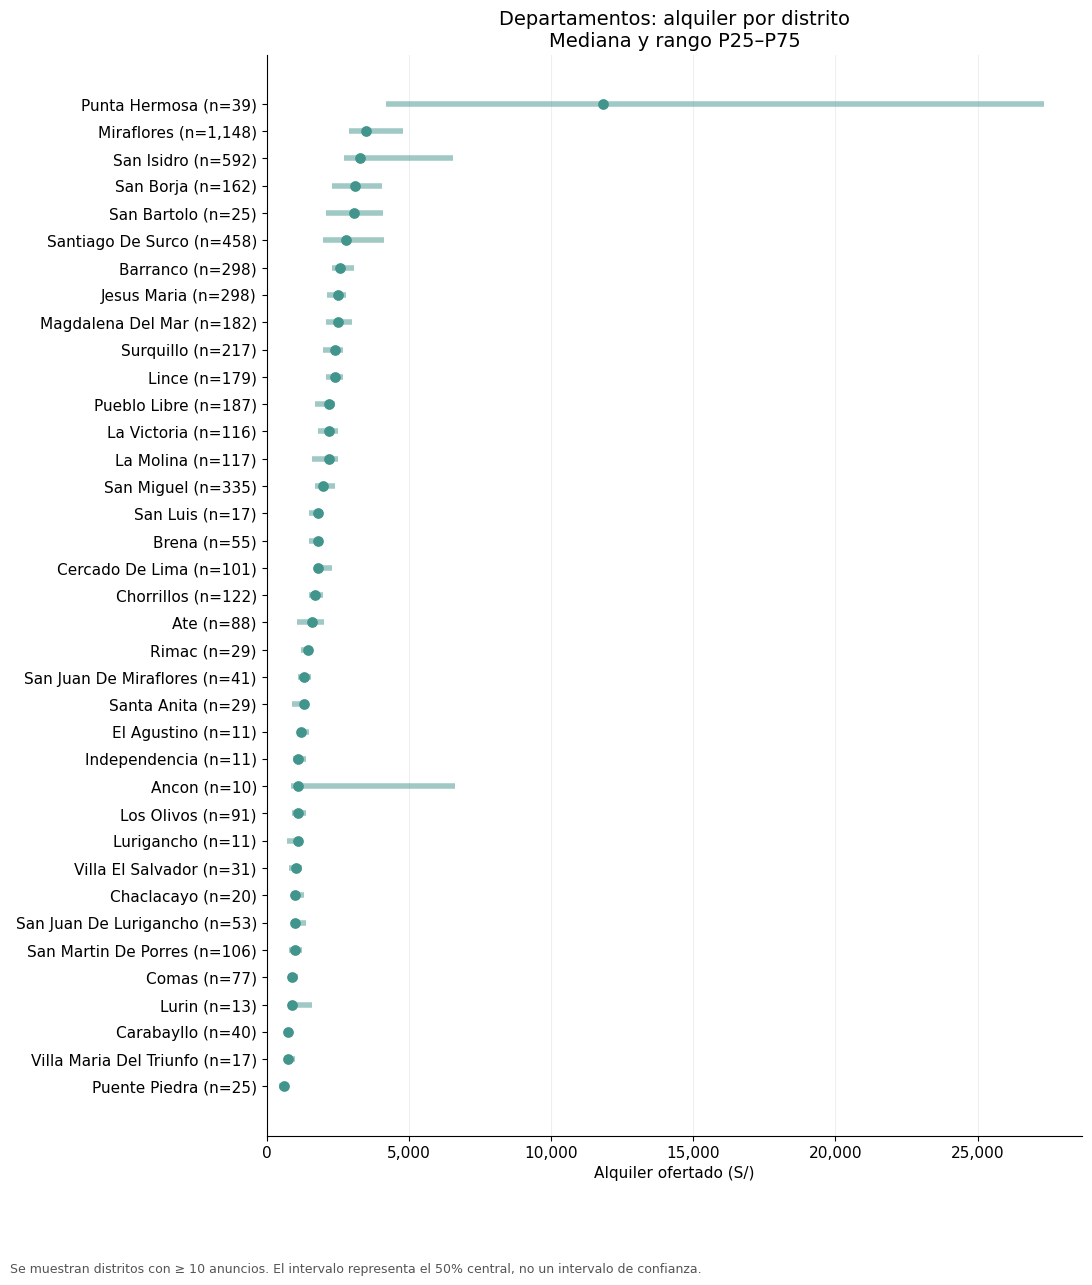

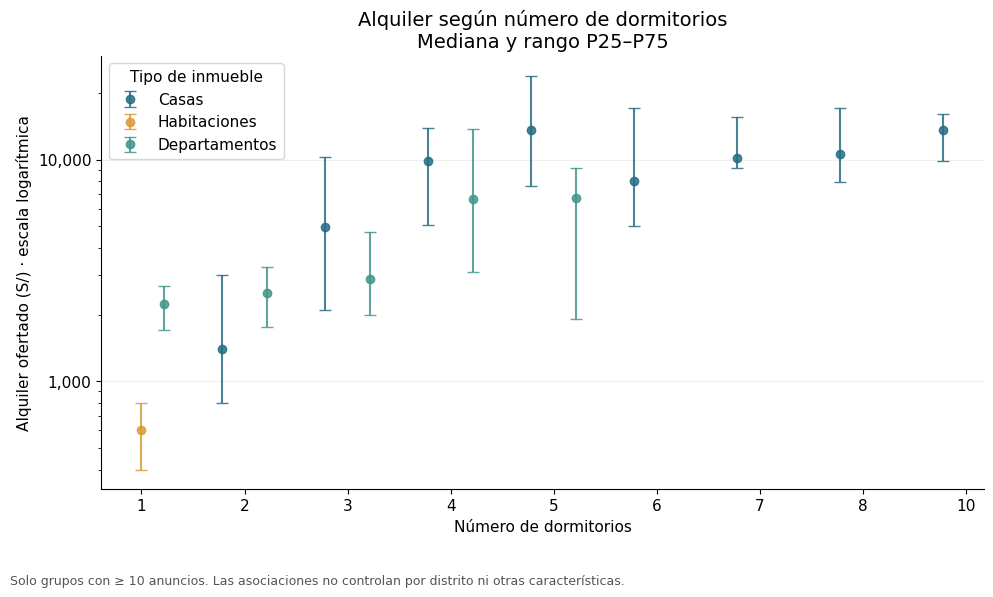

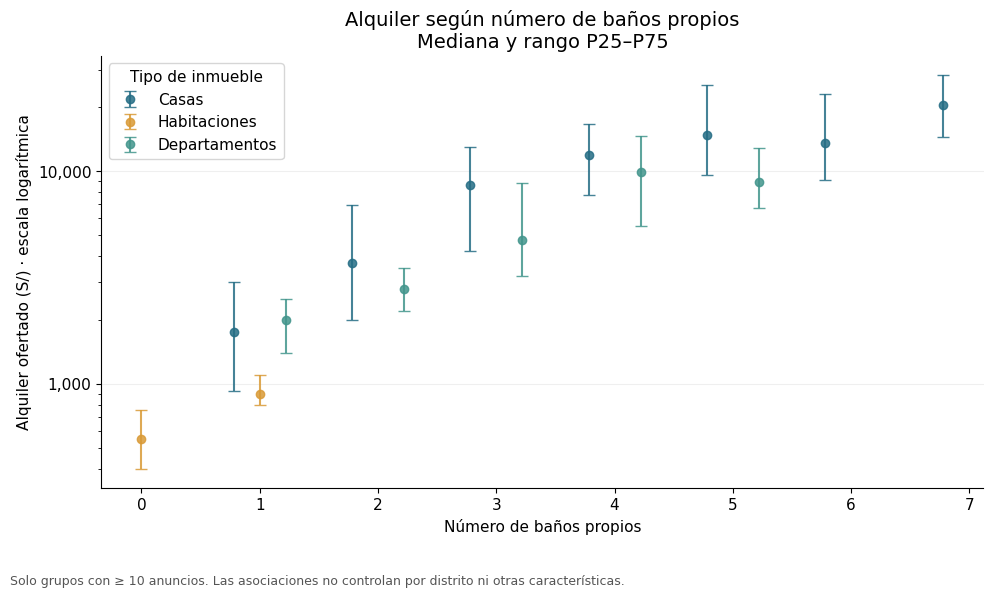

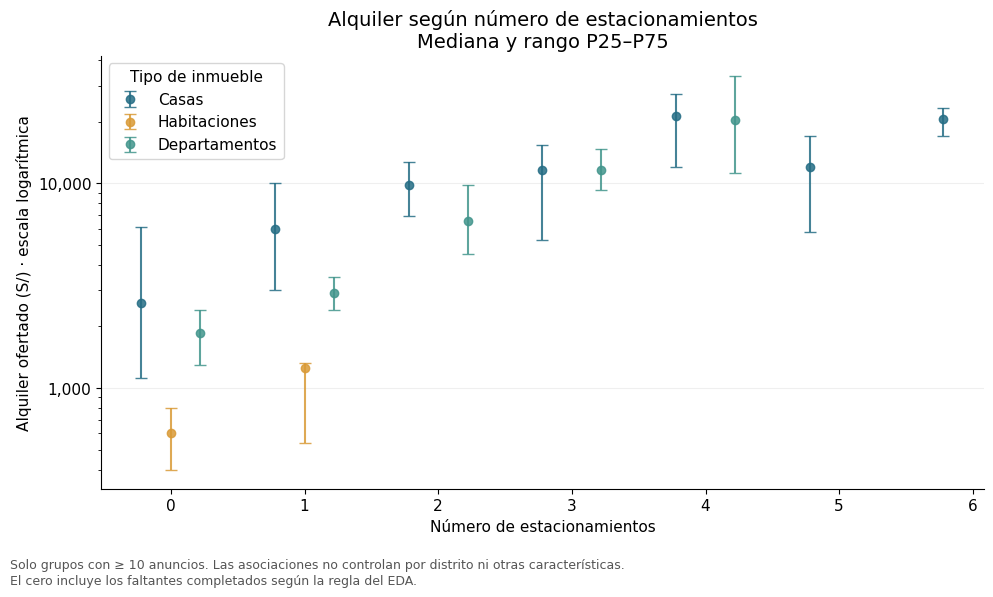

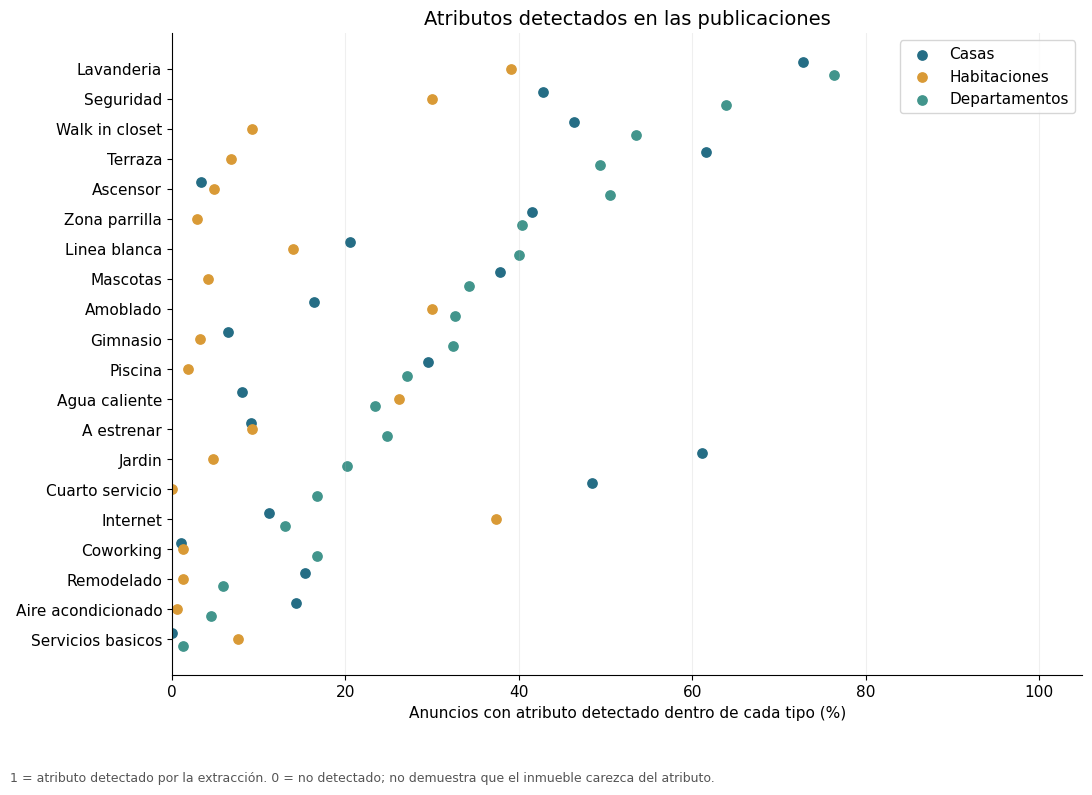

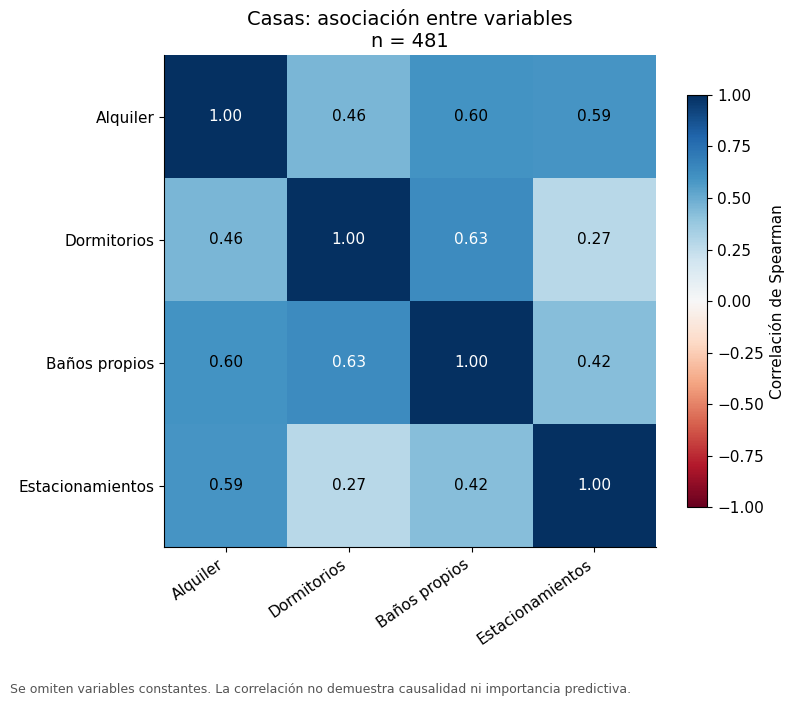

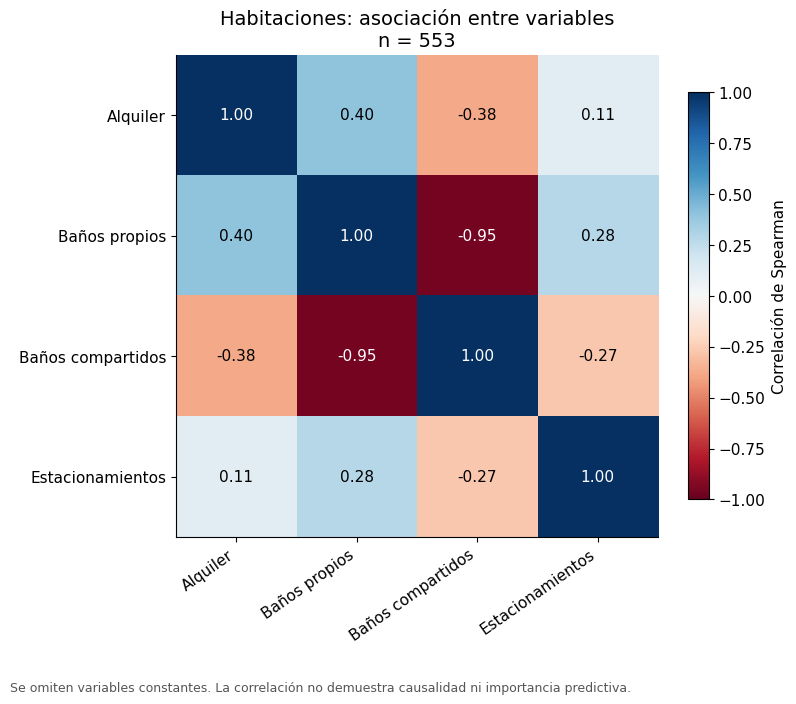

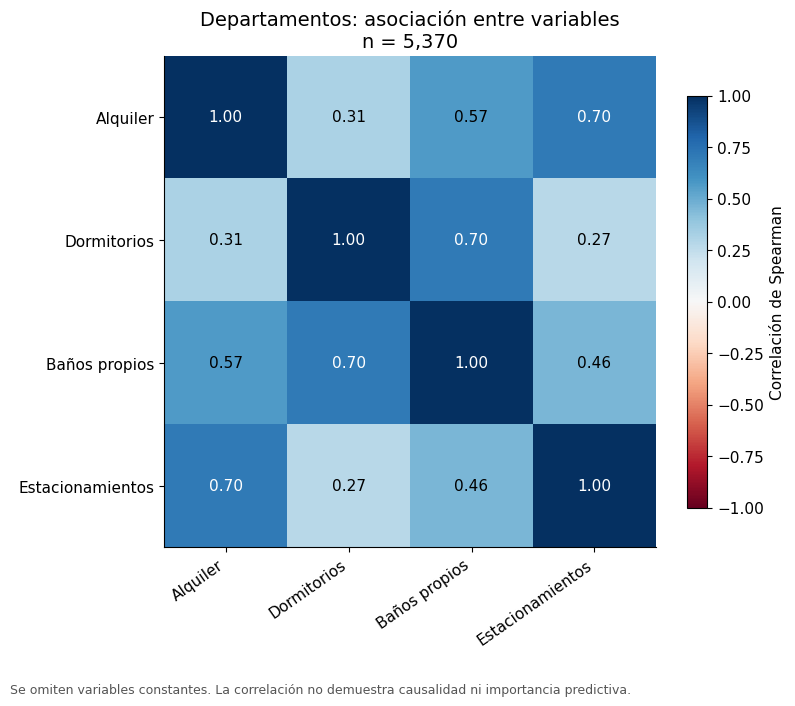


Gráficos guardados en: c:\Users\HP\Downloads\PI_EDA_Final\resultados_eda_revisado\graficos_modelamiento


In [181]:
# ============================================================
# GRÁFICOS PARA EL INFORME: BASE COMPLETA PARA MODELAMIENTO
# Cada gráfico se muestra y guarda como una imagen independiente.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ------------------------------------------------------------
# 1. CONFIGURACIÓN Y CARGA
# ------------------------------------------------------------

CARPETA_BASE = Path(CARPETA_PROYECTO) / "resultados_eda_revisado"
ARCHIVO = CARPETA_BASE / "base_alquileres_modelo.csv"
CARPETA_GRAFICOS = CARPETA_BASE / "graficos_modelamiento"
CARPETA_GRAFICOS.mkdir(parents=True, exist_ok=True)

datos = pd.read_csv(ARCHIVO, encoding="utf-8-sig")
datos = datos.replace(r"^\s*$", pd.NA, regex=True)

if datos.empty:
    raise ValueError("La base no contiene registros.")

if datos.isna().any().any():
    raise ValueError(
        "La base contiene faltantes. Revisa el bloque de casos completos."
    )

TIPOS = {
    "casa": "Casas",
    "cuarto": "Habitaciones",
    "departamento": "Departamentos"
}

COLORES = {
    "casa": "#256D85",
    "cuarto": "#D99A36",
    "departamento": "#42958C"
}

tipos_desconocidos = set(datos["tipo_inmueble"]) - set(TIPOS)
if tipos_desconocidos:
    raise ValueError(f"Tipos no reconocidos: {tipos_desconocidos}")

MIN_ANUNCIOS = 10

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False
})

formato_numero = FuncFormatter(lambda valor, _: f"{valor:,.0f}")


def guardar_grafico(fig, nombre, nota):
    """Guarda y muestra una figura independiente."""
    fig.text(
        0.01, 0.01, nota,
        fontsize=9, color="#555555",
        ha="left", va="bottom"
    )
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.savefig(
        CARPETA_GRAFICOS / f"{nombre}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


def resumen_precio(base, grupos):
    """Cantidad, mediana y rango intercuartílico del alquiler."""
    return (
        base.groupby(grupos, observed=True)["precio_pen_pub"]
        .agg(
            anuncios="count",
            mediana="median",
            p25=lambda x: x.quantile(0.25),
            p75=lambda x: x.quantile(0.75)
        )
        .reset_index()
    )


# Copia para los gráficos de precio con escala logarítmica.
# No modifica la base ni elimina registros del archivo original.
precios_validos = (
    np.isfinite(datos["precio_pen_pub"])
    & datos["precio_pen_pub"].gt(0)
)
datos_precio = datos.loc[precios_validos].copy()

print(f"Registros de la base: {len(datos):,}")
print(f"Variables: {datos.shape[1]}")
print(
    "Registros no representables en gráficos de precio:",
    int((~precios_validos).sum())
)


# ------------------------------------------------------------
# GRÁFICO 1. COMPOSICIÓN POR TIPO DE INMUEBLE
# Permite conocer el peso de cada segmento en la muestra.
# ------------------------------------------------------------

conteos = (
    datos["tipo_inmueble"]
    .value_counts()
    .reindex(TIPOS, fill_value=0)
)
porcentajes = conteos / len(datos) * 100

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.barh(
    [TIPOS[t] for t in conteos.index],
    porcentajes,
    color=[COLORES[t] for t in conteos.index]
)

for barra, tipo in zip(barras, conteos.index):
    ax.text(
        barra.get_width() + 0.7,
        barra.get_y() + barra.get_height() / 2,
        f"{porcentajes[tipo]:.2f}% · n = {conteos[tipo]:,}",
        va="center"
    )

ax.set_xlim(0, porcentajes.max() * 1.35)
ax.invert_yaxis()
ax.set_xlabel("Porcentaje del total de anuncios")
ax.set_title("Composición de la muestra por tipo de inmueble")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

guardar_grafico(
    fig,
    "01_composicion_tipo",
    "Los porcentajes describen la muestra analizada, no la participación "
    "de cada tipo en el mercado inmobiliario."
)


# ------------------------------------------------------------
# GRÁFICO 2. DISTRIBUCIÓN DEL ALQUILER POR TIPO
# Compara mediana, dispersión y valores extremos.
# ------------------------------------------------------------

tipos_presentes = [
    t for t in TIPOS
    if datos_precio["tipo_inmueble"].eq(t).any()
]

series = [
    datos_precio.loc[
        datos_precio["tipo_inmueble"].eq(t), "precio_pen_pub"
    ]
    for t in tipos_presentes
]

fig, ax = plt.subplots(figsize=(10, 6))

cajas = ax.boxplot(
    series,
    patch_artist=True,
    widths=0.55,
    medianprops={"color": "black", "linewidth": 1.7},
    flierprops={
        "marker": "o",
        "markersize": 3,
        "alpha": 0.25
    }
)

for caja, tipo in zip(cajas["boxes"], tipos_presentes):
    caja.set_facecolor(COLORES[tipo])
    caja.set_alpha(0.75)

ax.set_xticks(range(1, len(tipos_presentes) + 1))
ax.set_xticklabels([
    f"{TIPOS[t]}\n(n = {len(s):,})"
    for t, s in zip(tipos_presentes, series)
])

ax.set_yscale("log")
ax.yaxis.set_major_formatter(formato_numero)
ax.set_ylabel("Alquiler ofertado (S/) · escala logarítmica")
ax.set_title("Distribución del alquiler ofertado por tipo de inmueble")
ax.grid(axis="y", alpha=0.2)

guardar_grafico(
    fig,
    "02_distribucion_alquiler",
    "La caja contiene el 50% central. Los puntos fuera de los bigotes "
    "son extremos estadísticos; no necesariamente errores."
)


# ------------------------------------------------------------
# GRÁFICOS 3–5. ALQUILER POR DISTRITO
# Una imagen por tipo de inmueble.
# Incluye todos los distritos con al menos 10 anuncios de ese tipo.
# ------------------------------------------------------------

for numero, (tipo, titulo) in enumerate(TIPOS.items(), start=3):

    base_tipo = datos_precio.loc[
        datos_precio["tipo_inmueble"].eq(tipo)
    ]

    tabla = resumen_precio(base_tipo, ["distrito"])
    tabla = (
        tabla.loc[tabla["anuncios"].ge(MIN_ANUNCIOS)]
        .sort_values("mediana")
    )

    if tabla.empty:
        continue

    y = np.arange(len(tabla))

    fig, ax = plt.subplots(
        figsize=(11, max(5, len(tabla) * 0.35))
    )

    ax.hlines(
        y, tabla["p25"], tabla["p75"],
        color=COLORES[tipo], alpha=0.5, linewidth=4
    )
    ax.scatter(
        tabla["mediana"], y,
        color=COLORES[tipo], s=45, zorder=3
    )

    ax.set_yticks(y)
    ax.set_yticklabels([
        f"{d.title()} (n={n:,})"
        for d, n in zip(tabla["distrito"], tabla["anuncios"])
    ])

    ax.set_xlim(left=0)
    ax.xaxis.set_major_formatter(formato_numero)
    ax.set_xlabel("Alquiler ofertado (S/)")
    ax.set_title(
        f"{titulo}: alquiler por distrito\n"
        "Mediana y rango P25–P75"
    )
    ax.grid(axis="x", alpha=0.2)

    guardar_grafico(
        fig,
        f"{numero:02d}_alquiler_distrito_{tipo}",
        f"Se muestran distritos con ≥ {MIN_ANUNCIOS} anuncios. "
        "El intervalo representa el 50% central, no un intervalo de confianza."
    )


# ------------------------------------------------------------
# GRÁFICOS 6–8. ALQUILER Y CARACTERÍSTICAS FÍSICAS
# Una imagen por variable; colores por tipo de inmueble.
# Se muestran medianas e intervalos P25–P75.
# ------------------------------------------------------------

caracteristicas = {
    "dormitorios": "Número de dormitorios",
    "banos_propios": "Número de baños propios",
    "estacionamientos": "Número de estacionamientos"
}

for numero, (variable, etiqueta) in enumerate(
    caracteristicas.items(), start=6
):
    tabla = resumen_precio(
        datos_precio, ["tipo_inmueble", variable]
    )
    tabla = tabla.loc[tabla["anuncios"].ge(MIN_ANUNCIOS)]

    if tabla.empty:
        continue

    niveles = sorted(tabla[variable].unique())
    posiciones = {valor: i for i, valor in enumerate(niveles)}
    desplazamientos = {"casa": -0.22, "cuarto": 0, "departamento": 0.22}

    fig, ax = plt.subplots(
        figsize=(max(10, len(niveles) * 0.8), 6)
    )

    for tipo, titulo in TIPOS.items():
        sub = tabla.loc[tabla["tipo_inmueble"].eq(tipo)]
        if sub.empty:
            continue

        x = np.array([
            posiciones[v] for v in sub[variable]
        ]) + desplazamientos[tipo]

        errores = np.vstack([
            sub["mediana"] - sub["p25"],
            sub["p75"] - sub["mediana"]
        ])

        ax.errorbar(
            x, sub["mediana"],
            yerr=errores,
            fmt="o",
            color=COLORES[tipo],
            label=titulo,
            capsize=4,
            markersize=6,
            alpha=0.85
        )

    ax.set_xticks(range(len(niveles)))
    ax.set_xticklabels([f"{v:g}" for v in niveles])
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(formato_numero)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Alquiler ofertado (S/) · escala logarítmica")
    ax.set_title(
        f"Alquiler según {etiqueta.lower()}\n"
        "Mediana y rango P25–P75"
    )
    ax.legend(title="Tipo de inmueble")
    ax.grid(axis="y", alpha=0.2)

    nota = (
        f"Solo grupos con ≥ {MIN_ANUNCIOS} anuncios. "
        "Las asociaciones no controlan por distrito ni otras características."
    )

    if variable == "estacionamientos":
        nota += "\nEl cero incluye los faltantes completados según la regla del EDA."

    guardar_grafico(
        fig,
        f"{numero:02d}_alquiler_segun_{variable}",
        nota
    )


# ------------------------------------------------------------
# GRÁFICO 9. ATRIBUTOS DETECTADOS POR TIPO
# Permite comparar equipamiento y servicios mencionados.
# ------------------------------------------------------------

atributos = [c for c in datos.columns if c.startswith("attr_")]

if atributos:

    if not datos[atributos].isin([0, 1]).all().all():
        raise ValueError("Hay atributos con códigos distintos de 0 y 1.")

    frecuencia = (
        datos.groupby("tipo_inmueble")[atributos]
        .mean()
        .mul(100)
        .reindex(TIPOS)
        .T
    )

    orden = datos[atributos].mean().sort_values(ascending=False).index
    frecuencia = frecuencia.loc[orden]

    etiquetas = [
        c.replace("attr_", "").replace("_", " ").capitalize()
        for c in frecuencia.index
    ]

    y = np.arange(len(frecuencia))
    fig, ax = plt.subplots(figsize=(11, max(7, len(atributos) * 0.4)))

    for desplazamiento, (tipo, titulo) in zip(
        [-0.22, 0, 0.22], TIPOS.items()
    ):
        ax.scatter(
            frecuencia[tipo], y + desplazamiento,
            color=COLORES[tipo], label=titulo, s=45
        )

    ax.set_yticks(y)
    ax.set_yticklabels(etiquetas)
    ax.invert_yaxis()
    ax.set_xlim(0, 105)
    ax.set_xlabel("Anuncios con atributo detectado dentro de cada tipo (%)")
    ax.set_title("Atributos detectados en las publicaciones")
    ax.legend()
    ax.grid(axis="x", alpha=0.2)

    guardar_grafico(
        fig,
        "09_atributos_por_tipo",
        "1 = atributo detectado por la extracción. "
        "0 = no detectado; no demuestra que el inmueble carezca del atributo."
    )


# ------------------------------------------------------------
# GRÁFICOS 10–12. CORRELACIONES POR TIPO
# Spearman evalúa asociaciones monotónicas entre variables.
# Se omiten variables constantes dentro de cada segmento.
# ------------------------------------------------------------

variables_correlacion = {
    "precio_pen_pub": "Alquiler",
    "dormitorios": "Dormitorios",
    "banos_propios": "Baños propios",
    "banos_compartidos": "Baños compartidos",
    "estacionamientos": "Estacionamientos"
}

for numero, (tipo, titulo) in enumerate(TIPOS.items(), start=10):

    base_tipo = datos_precio.loc[
        datos_precio["tipo_inmueble"].eq(tipo),
        list(variables_correlacion)
    ]

    variables_con_variacion = [
        c for c in base_tipo.columns
        if base_tipo[c].nunique() > 1
    ]

    if len(variables_con_variacion) < 2:
        continue

    # Correlación de Pearson sobre rangos = Spearman.
    correlacion = (
        base_tipo[variables_con_variacion]
        .rank(method="average")
        .corr()
    )

    fig, ax = plt.subplots(figsize=(8, 7))

    imagen = ax.imshow(
        correlacion,
        cmap="RdBu",
        vmin=-1, vmax=1
    )

    etiquetas = [
        variables_correlacion[c] for c in correlacion.columns
    ]

    ax.set_xticks(range(len(etiquetas)))
    ax.set_yticks(range(len(etiquetas)))
    ax.set_xticklabels(etiquetas, rotation=35, ha="right")
    ax.set_yticklabels(etiquetas)

    for i in range(len(etiquetas)):
        for j in range(len(etiquetas)):
            valor = correlacion.iloc[i, j]
            ax.text(
                j, i, f"{valor:.2f}",
                ha="center", va="center",
                color="white" if abs(valor) >= 0.6 else "black"
            )

    barra = fig.colorbar(imagen, ax=ax, shrink=0.8)
    barra.set_label("Correlación de Spearman")

    ax.set_title(
        f"{titulo}: asociación entre variables\n"
        f"n = {len(base_tipo):,}"
    )

    guardar_grafico(
        fig,
        f"{numero:02d}_correlaciones_{tipo}",
        "Se omiten variables constantes. "
        "La correlación no demuestra causalidad ni importancia predictiva."
    )

print(f"\nGráficos guardados en: {CARPETA_GRAFICOS}")